# <font color='blue'> Marketing & E-Commerce Analytics </font>

### <font color='green'> Understanding Customer Behaviour Through Data Analytics, Marketing Experiments & Revenue Analytics </font>

##### EDA · Funnel Analysis · A/B Testing · Customer Segmentation · Revenue Analysis

![](https://frontlinesmedia.in/wp-content/uploads/2026/02/Pi7_image_tool-1024x677.jpeg)

**By:** Nur Alyaa Jamal

**Project objective:** Explore customer behaviour, evaluate marketing campaign effectiveness, analyse conversion funnels and purchasing patterns, and uncover data-driven insights into revenue, customer engagement, product performance, and business growth through statistical analysis.

> **Analysis principles**
> - Observed patterns and statistical associations do not necessarily prove causation.
> - A/B testing should account for experiment assignments and compare appropriate treatment and control groups.
> - Marketing campaign effectiveness should be evaluated using relevant metrics such as conversion rate, revenue per customer, average order value and uplift.
> - Customer behaviour should be analysed across different stages of the purchasing funnel, from browsing and clicking to carting and purchasing.
> - Revenue analysis should consider discounts, refunds and campaign exposure to avoid misleading business conclusions.
> - Statistical significance and practical business impact should be interpreted together.
> - The dataset is entirely synthetic. Findings demonstrate analytical techniques and should not be treated as evidence of actual e-commerce business performance.
> - The notebook generates data-dependent findings when executed. All numerical results and interpretations should reflect the actual dataset.

## Notebook roadmap

This notebook follows a structured marketing and e-commerce analytics workflow:

1. **Load & validate** — Explore dataset structure, tables, data types, missing values, duplicates and data consistency.
2. **Explore customer & product behaviour** — Analyse customer profiles, product distributions, purchasing patterns and interaction activities.
3. **Analyse conversion funnels** — Examine customer progression through browsing, clicking, adding products to cart and completing purchases.
4. **Evaluate marketing campaigns** — Investigate campaign exposure, traffic sources, customer engagement and purchasing behaviour.
5. **Conduct A/B testing** — Compare experiment groups, evaluate conversion rates, test statistical significance and measure campaign uplift.
6. **Analyse revenue & transactions** — Investigate sales performance, average order value, discounts, refunds and revenue contributions.
7. **Explore customer segmentation** — Identify differences in purchasing behaviour across loyalty tiers, customer groups and traffic sources.
8. **Analyse trends & seasonality** — Examine purchasing patterns over time, including seasonal trends and weekend effects.
9. **Evaluate product performance** — Identify top-performing products, categories and purchasing patterns.
10. **Translate into business insights** — Summarise key findings, marketing implications, business recommendations and analytical limitations.

> **SQL + Python approach.** Cleaned tables are copied into an in-memory SQLite database. SQL handles joins, conditional aggregation, window functions, CTEs and RFM scoring. Python handles statistical testing, modelling and charts. The roadmap steps above map to Sections 3-13, with business findings in Section 14 and the conclusion in Section 15.

## 1. Import libraries

This notebook uses **SQL (SQLite)** for data extraction and aggregation, and **pandas, NumPy, Matplotlib, Seaborn, SciPy and Statsmodels** for cleaning, statistical testing and visualisation. SQLite ships with Python, so no extra installation is needed.

In [1]:
# Core
from pathlib import Path
from IPython.display import display, HTML
import gc
import html
import sqlite3
import warnings

# Data manipulation
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Statistical analysis
from scipy import stats
from scipy.stats import chi2_contingency, mannwhitneyu, norm
import statsmodels.api as sm

warnings.filterwarnings("ignore")

# Visualisation settings
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", "{:,.2f}".format)


CARD_COLORS = {
    "purple": ("#F3E8FF", "#7E22CE"),
    "blue": ("#E0F2FE", "#0369A1"),
    "teal": ("#CCFBF1", "#0F766E"),
    "green": ("#DCFCE7", "#15803D"),
    "yellow": ("#FEF3C7", "#B45309"),
    "pink": ("#FCE7F3", "#BE185D"),
    "orange": ("#FFEDD5", "#C2410C"),
    "red": ("#FEE2E2", "#B91C1C"),
    "slate": ("#F1F5F9", "#334155"),
}

def show_cards(cards, columns=3):
    """Render colourful HTML cards. Each item: title, body, optional color and icon."""
    card_html = []
    for item in cards:
        title = html.escape(str(item.get("title", "")))
        body = str(item.get("body", ""))
        color = item.get("color", "blue")
        icon = html.escape(str(item.get("icon", "✦")))
        bg, accent = CARD_COLORS.get(color, CARD_COLORS["blue"])
        card_html.append(
            f'<div style="background:{bg};border:1px solid {accent}30;'
            f'border-top:5px solid {accent};border-radius:14px;padding:16px 18px;'
            f'min-width:0;box-shadow:0 3px 10px rgba(15,23,42,.06);">'
            f'<div style="font-size:22px;margin-bottom:6px">{icon}</div>'
            f'<div style="font-size:15px;font-weight:750;color:{accent};margin-bottom:8px">{title}</div>'
            f'<div style="font-size:13.5px;line-height:1.55;color:#1f2937">{body}</div>'
            f'</div>'
        )
    display(HTML(
        f'<div style="display:grid;grid-template-columns:repeat({columns},minmax(0,1fr));'
        f'gap:14px;margin:12px 0 20px 0;">{"".join(card_html)}</div>'
    ))

def show_banner(title, message, color="purple", icon="💡"):
    bg, accent = CARD_COLORS.get(color, CARD_COLORS["purple"])
    display(HTML(
        f'<div style="background:{bg};border-left:6px solid {accent};border-radius:12px;'
        f'padding:15px 18px;margin:12px 0 18px 0;color:#1f2937;line-height:1.6">'
        f'<span style="font-size:20px;margin-right:8px">{icon}</span>'
        f'<strong style="color:{accent}">{html.escape(title)}</strong><br>{message}</div>'
    ))

# small formatting helpers
def pct(value, d=1):
    return f"{value:.{d}f}%" if pd.notna(value) else "N/A"

def money(value, d=0):
    return f"${value:,.{d}f}" if pd.notna(value) else "N/A"

def fmt_p(p):
    if pd.isna(p):
        return "N/A"
    return "<0.001" if p < 0.001 else f"{p:.3f}"

# statistical helpers
def benjamini_hochberg(p_values):
    """Benjamini-Hochberg false-discovery-rate adjustment; returns adjusted p-values (q-values)."""
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    if n == 0:
        return np.array([])
    order = np.argsort(p)
    ranked = p[order]
    adjusted = ranked * n / np.arange(1, n + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    result = np.empty(n, dtype=float)
    result[order] = np.clip(adjusted, 0, 1)
    return result

def cramers_v(table):
    """Chi-square test of independence + Cramer's V effect size for a contingency table."""
    chi2, p, dof, _ = chi2_contingency(table, correction=False)
    n = np.asarray(table).sum()
    k = min(np.asarray(table).shape) - 1
    v = np.sqrt(chi2 / (n * k)) if k > 0 and n > 0 else np.nan
    return chi2, p, dof, v

def two_prop_test(x_t, n_t, x_c, n_c):
    """Two-proportion z-test of treatment vs control (pooled SE for the test, unpooled SE for the 95% CI)."""
    p_t, p_c = x_t / n_t, x_c / n_c
    diff = p_t - p_c
    p_pool = (x_t + x_c) / (n_t + n_c)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_t + 1 / n_c))
    z = diff / se_pool if se_pool > 0 else np.nan
    p_val = 2 * (1 - norm.cdf(abs(z))) if pd.notna(z) else np.nan
    se = np.sqrt(p_t * (1 - p_t) / n_t + p_c * (1 - p_c) / n_c)
    return {
        "rate_treat": p_t, "rate_ctrl": p_c, "diff": diff,
        "ci_low": diff - 1.96 * se, "ci_high": diff + 1.96 * se,
        "rel_lift": diff / p_c if p_c > 0 else np.nan, "z": z, "p_value": p_val,
    }

FINDINGS = {}

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the dataset

The dataset has **five related tables**. They are loaded into pandas first, and later copied into an in-memory **SQLite database** so that the same data can be analysed with SQL queries (joins, aggregations, window functions) and with Python.

In [2]:
# Kaggle path first; the other locations are fallbacks for running outside Kaggle.
candidate_dirs = [
    Path("/kaggle/input/datasets/geethasagarbonthu/marketing-and-e-commerce-analytics-dataset"),
    Path("."),
    Path("/mnt/data"),
]
DATA_DIR = next((d for d in candidate_dirs if (d / "events.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not locate the dataset. Put campaigns.csv, customers.csv, events.csv, products.csv and "
        "transactions.csv beside this notebook, or update DATA_DIR."
    )

campaigns    = pd.read_csv(DATA_DIR / "campaigns.csv")
customers    = pd.read_csv(DATA_DIR / "customers.csv")
products     = pd.read_csv(DATA_DIR / "products.csv")
transactions = pd.read_csv(DATA_DIR / "transactions.csv")
events       = pd.read_csv(DATA_DIR / "events.csv")

print(f"Datasets loaded successfully from: {DATA_DIR}\n")
for name, frame in [("campaigns", campaigns), ("customers", customers), ("products", products),
                    ("transactions", transactions), ("events", events)]:
    print(f"{name:<13} rows: {frame.shape[0]:>9,} | columns: {frame.shape[1]}")

Datasets loaded successfully from: /kaggle/input/datasets/geethasagarbonthu/marketing-and-e-commerce-analytics-dataset

campaigns     rows:        50 | columns: 7
customers     rows:   100,000 | columns: 7
products      rows:     2,000 | columns: 6
transactions  rows:   103,127 | columns: 9
events        rows: 2,000,000 | columns: 12


In [3]:
print("1. Campaigns Data")
display(campaigns.head())
print("2. Customers Data")
display(customers.head())
print("3. Products Data")
display(products.head())
print("4. Transactions Data")
display(transactions.head())
print("5. Events Data")
display(events.head())

1. Campaigns Data


,campaign_id,channel,objective,start_date,end_date,target_segment,expected_uplift
0,1,Paid Search,Cross-sell,2021-10-25,2021-11-26,Deal Seekers,0.02
1,2,Email,Retention,2021-10-24,2021-12-24,Deal Seekers,0.12
2,3,Email,Reactivation,2023-10-08,2023-11-30,Churn Risk,0.10
3,4,Display,Reactivation,2022-07-25,2022-10-07,Deal Seekers,0.11
4,5,Social,Acquisition,2022-07-09,2022-09-29,New Customers,0.14


2. Customers Data


,customer_id,signup_date,country,age,gender,loyalty_tier,acquisition_channel
0,1,2021-04-08,BR,48,Male,Bronze,Referral
1,2,2023-04-28,IN,36,Female,Silver,Organic
2,3,2022-12-18,UK,35,Female,Silver,Organic
3,4,2022-04-26,US,45,Male,Silver,Paid Search
4,5,2022-04-20,IN,53,Male,Silver,Organic


3. Products Data


,product_id,category,brand,base_price,launch_date,is_premium
0,1,Grocery,Brand_58,14.19,2021-08-02,0
1,2,Fashion,Brand_1,25.80,2021-09-14,0
2,3,Electronics,Brand_70,165.46,2021-01-18,1
3,4,Fashion,Brand_56,75.45,2023-03-03,1
4,5,Sports,Brand_1,72.50,2022-04-19,1


4. Transactions Data


,transaction_id,timestamp,customer_id,product_id,quantity,discount_applied,gross_revenue,campaign_id,refund_flag
0,1,2021-12-27 08:25:15,59540,"1,630.00",3,0.00,43.74,0,0
1,2,2023-06-06 21:14:26,54871,"1,901.00",3,0.00,174.78,21,0
2,3,2023-08-31 05:29:54,51818,"1,884.00",1,0.00,40.61,37,0
3,4,2022-06-26 20:33:46,18164,"1,114.00",2,0.15,68.76,13,0
4,5,2023-07-26 18:12:35,86915,408.00,1,0.00,14.64,4,0


5. Events Data


,event_id,timestamp,customer_id,session_id,event_type,product_id,device_type,traffic_source,campaign_id,page_category,session_duration_sec,experiment_group
0,1,2021-01-14 13:35:43,43812,535101,view,"1,004.00",desktop,Email,43,PLP,115.10,Control
1,2,2021-12-03 21:36:50,71340,96426,add_to_cart,986.00,desktop,Email,10,PDP,32.40,Variant_A
2,3,2021-12-27 08:25:15,59540,220126,purchase,"1,630.00",mobile,Organic,0,PDP,190.70,Variant_A
3,4,2022-01-22 15:06:54,3601,484555,add_to_cart,"1,532.00",desktop,Paid Search,30,Checkout,134.80,Variant_B
4,5,2021-05-10 12:03:09,92735,60646,bounce,NaN,desktop,Email,26,PLP,53.10,Variant_A


## 3. Understand the data

Before any analysis, check the size, data types, missing values, duplicates and **how the tables connect**. In a multi-table dataset, the relationships between tables matter as much as the contents of each table.

In [4]:
tables = {"campaigns": campaigns, "customers": customers, "products": products,
          "transactions": transactions, "events": events}

overview = pd.DataFrame({
    "Rows": {k: len(v) for k, v in tables.items()},
    "Columns": {k: v.shape[1] for k, v in tables.items()},
    "Missing cells": {k: int(v.isna().sum().sum()) for k, v in tables.items()},
    "Exact duplicate rows": {k: int(v.duplicated().sum()) for k, v in tables.items()},
    "Memory (MB)": {k: v.memory_usage(deep=True).sum() / 1e6 for k, v in tables.items()},
})
display(overview)

print("Columns with missing values:")
missing_rows = []
for name, frame in tables.items():
    for col, n in frame.isna().sum().items():
        if n > 0:
            missing_rows.append({"Table": name, "Column": col, "Missing": int(n), "Missing (%)": n / len(frame) * 100})
display(pd.DataFrame(missing_rows))

print("\nData types (events):")
display(events.dtypes.to_frame("dtype").T)

show_cards([
    {"title": "Customers", "body": f"<strong>{len(customers):,}</strong> customers<br><strong>{len(products):,}</strong> products", "color": "purple", "icon": "👥"},
    {"title": "Events", "body": f"<strong>{len(events):,}</strong> interaction events<br>{events['timestamp'].min()[:10]} → {events['timestamp'].max()[:10]}", "color": "blue", "icon": "🖱️"},
    {"title": "Transactions", "body": f"<strong>{len(transactions):,}</strong> purchases<br><strong>{transactions['customer_id'].nunique():,}</strong> unique buyers", "color": "green", "icon": "🛒"},
    {"title": "Campaigns", "body": f"<strong>{len(campaigns)}</strong> campaigns<br><strong>{campaigns['channel'].nunique()}</strong> channels", "color": "pink", "icon": "📣"},
], columns=4)

show_banner(
    "Data-quality reminder",
    "Missing cells and duplicates are only the first checks. In multi-table data, also verify <strong>keys</strong>, "
    "<strong>category spelling</strong>, <strong>how revenue is recorded</strong> (e.g. refunds as negative values) and "
    "<strong>what each ID really represents</strong>. These are examined below.",
    color="yellow", icon="🔎"
)

,Rows,Columns,Missing cells,Exact duplicate rows,Memory (MB)
campaigns,50,7,0,0,0.02
customers,100000,7,0,0,29.17
products,2000,6,0,0,0.39
transactions,103127,9,20898,0,13.61
events,2000000,12,240671,0,782.62


Columns with missing values:


,Table,Column,Missing,Missing (%)
0,transactions,product_id,10449,10.13
1,transactions,gross_revenue,10449,10.13
2,events,product_id,200371,10.02
3,events,device_type,40300,2.02



Data types (events):


,event_id,timestamp,customer_id,session_id,event_type,product_id,device_type,traffic_source,campaign_id,page_category,session_duration_sec,experiment_group
dtype,int64,object,int64,int64,object,float64,object,object,int64,object,float64,object


### 🧾 Data dictionary

| Table | Column | Meaning |
|---|---|---|
| `customers` | `signup_date`, `country`, `age`, `gender`, `loyalty_tier`, `acquisition_channel` | Customer profile (tiers: Bronze < Silver < Gold < Platinum) |
| `products` | `category`, `brand`, `base_price`, `launch_date`, `is_premium` | Product catalogue |
| `campaigns` | `channel`, `objective`, `start_date`, `end_date`, `target_segment`, `expected_uplift` | Campaign design; `expected_uplift` is the planned lift |
| `events` | `event_type`, `product_id`, `device_type`, `traffic_source`, `campaign_id`, `page_category`, `session_duration_sec`, `experiment_group` | One interaction. `campaign_id = 0` means **no campaign exposure** |
| `transactions` | `quantity`, `discount_applied`, `gross_revenue`, `campaign_id`, `refund_flag` | One purchase, linked to a purchase event |

In [5]:
# Key and relationship integrity checks
purchase_events = events[events["event_type"] == "purchase"]
link = purchase_events.merge(transactions[["customer_id", "timestamp", "transaction_id"]],
                             on=["customer_id", "timestamp"], how="inner")

integrity = pd.DataFrame([
    ["customer_id is unique in customers",           customers["customer_id"].is_unique],
    ["product_id is unique in products",             products["product_id"].is_unique],
    ["campaign_id is unique in campaigns",           campaigns["campaign_id"].is_unique],
    ["event_id is unique in events",                 events["event_id"].is_unique],
    ["transaction_id is unique in transactions",     transactions["transaction_id"].is_unique],
    ["All event customers exist in customers",       events["customer_id"].isin(customers["customer_id"]).all()],
    ["All transaction customers exist in customers", transactions["customer_id"].isin(customers["customer_id"]).all()],
    ["All event products exist in products",         events["product_id"].dropna().isin(products["product_id"]).all()],
    ["All transaction products exist in products",   transactions["product_id"].dropna().isin(products["product_id"]).all()],
    ["All non-zero event campaigns exist in campaigns", events.loc[events["campaign_id"] > 0, "campaign_id"].isin(campaigns["campaign_id"]).all()],
    ["Purchase events match transactions 1-to-1 (customer_id + timestamp)",
     len(purchase_events) == len(transactions) == len(link) and link["transaction_id"].is_unique],
], columns=["Check", "Passed"])
integrity["Passed"] = integrity["Passed"].map({True: "✅ Yes", False: "❌ No"})
display(integrity)

print(f"Purchase events: {len(purchase_events):,} | Transactions: {len(transactions):,} | Matched pairs: {len(link):,}")

,Check,Passed
0,customer_id is unique in customers,✅ Yes
1,product_id is unique in products,✅ Yes
2,campaign_id is unique in campaigns,✅ Yes
3,event_id is unique in events,✅ Yes
4,transaction_id is unique in transactions,✅ Yes
5,All event customers exist in customers,✅ Yes
6,All transaction customers exist in customers,✅ Yes
7,All event products exist in products,✅ Yes
8,All transaction products exist in products,✅ Yes
9,All non-zero event campaigns exist in campaigns,✅ Yes


Purchase events: 103,127 | Transactions: 103,127 | Matched pairs: 103,127


In [6]:
# Data-quality investigation (each finding is computed, not typed in)
raw_sources = events["traffic_source"].nunique()
clean_sources = events["traffic_source"].str.strip().str.title().nunique()

evt_key = events["customer_id"].astype(str) + "_" + events["session_id"].astype(str)
events_per_session = evt_key.value_counts()

groups_per_customer = events.groupby("customer_id")["experiment_group"].nunique()

rev_missing = transactions["gross_revenue"].isna()
prod_missing = transactions["product_id"].isna()
neg_rev = transactions["gross_revenue"] < 0

# Are exposure dates inside the campaign window?
exposed = events.loc[events["campaign_id"] > 0, ["timestamp", "campaign_id"]].merge(campaigns, on="campaign_id")
exp_day = pd.to_datetime(exposed["timestamp"]).dt.normalize()
in_window = ((exp_day >= pd.to_datetime(exposed["start_date"])) & (exp_day <= pd.to_datetime(exposed["end_date"]))).mean() * 100

# Events recorded before the customer's signup date
ev_signup = events[["customer_id", "timestamp"]].merge(customers[["customer_id", "signup_date"]], on="customer_id")
before_signup = (ev_signup["timestamp"].str[:10] < ev_signup["signup_date"]).mean() * 100

quality = pd.DataFrame([
    ["traffic_source spelling variants", f"{raw_sources} raw labels vs {clean_sources} after standardising case", "Standardise to Title Case"],
    ["device_type missing", f"{events['device_type'].isna().sum():,} events ({events['device_type'].isna().mean()*100:.1f}%)", "Label as 'Unknown' (not dropped)"],
    ["product_id missing on events", f"{events['product_id'].isna().sum():,} events (all bounces + some purchases)", "Expected for bounces; excluded from product-level analysis"],
    ["transaction product_id missing", f"{prod_missing.sum():,} ({prod_missing.mean()*100:.1f}%)", "Cannot be attributed to a category; kept for order counts"],
    ["transaction gross_revenue missing", f"{rev_missing.sum():,} ({rev_missing.mean()*100:.1f}%), same rows as missing product_id: {bool((rev_missing == prod_missing).all())}", "Excluded from revenue totals; NOT imputed"],
    ["Negative gross_revenue", f"{neg_rev.sum():,} rows; all refunded: {bool((transactions.loc[neg_rev, 'refund_flag'] == 1).all())}", "Refunds are stored as negative values, so revenue is rebuilt (Section 4)"],
    ["session_id is not a journey key", f"Median events per (customer, session) = {events_per_session.median():.0f}", "Funnel is event-count based, not path based"],
    ["experiment_group assigned per event", f"{(groups_per_customer > 1).mean()*100:.1f}% of customers appear in 2+ groups", "A/B test is event-level; use cluster-robust checks"],
    ["Campaign dates vs exposure", f"Only {in_window:.1f}% of exposed events fall inside the campaign start/end window", "Treat campaign_id as an exposure label, not time-bound"],
    ["Events before signup_date", f"{before_signup:.1f}% of events", "Synthetic-data artefact; signup_date not used for filtering"],
], columns=["Issue", "What was found", "Treatment"])
display(quality)

FINDINGS["rev_missing_pct"] = rev_missing.mean() * 100
FINDINGS["multi_group_customers_pct"] = (groups_per_customer > 1).mean() * 100
FINDINGS["campaign_in_window_pct"] = in_window

show_banner(
    "Why these checks matter",
    f"<ul><li><strong>{rev_missing.mean()*100:.1f}%</strong> of transactions have no product and no revenue, so revenue "
    "metrics describe the transactions that do have values.</li>"
    "<li>Refunds are stored as <strong>negative</strong> revenue. A plain <code>SUM(gross_revenue)</code> would therefore "
    "understate sales and mis-state refunds.</li>"
    f"<li>Customers appear in <strong>more than one experiment group</strong> ({(groups_per_customer > 1).mean()*100:.1f}% of customers), "
    "so the A/B test is run per event, not per customer.</li></ul>",
    color="orange", icon="⚠️"
)

,Issue,What was found,Treatment
0,traffic_source spelling variants,10 raw labels vs 5 after standardising case,Standardise to Title Case
1,device_type missing,"40,300 events (2.0%)",Label as 'Unknown' (not dropped)
2,product_id missing on events,"200,371 events (all bounces + some purchases)",Expected for bounces; excluded from product-level analysis
3,transaction product_id missing,"10,449 (10.1%)",Cannot be attributed to a category; kept for order counts
4,transaction gross_revenue missing,"10,449 (10.1%), same rows as missing product_id: True",Excluded from revenue totals; NOT imputed
5,Negative gross_revenue,"2,704 rows; all refunded: True","Refunds are stored as negative values, so revenue is rebuilt (Section 4)"
6,session_id is not a journey key,"Median events per (customer, session) = 1","Funnel is event-count based, not path based"
7,experiment_group assigned per event,100.0% of customers appear in 2+ groups,A/B test is event-level; use cluster-robust checks
8,Campaign dates vs exposure,Only 4.7% of exposed events fall inside the campaign start/end window,"Treat campaign_id as an exposure label, not time-bound"
9,Events before signup_date,49.9% of events,Synthetic-data artefact; signup_date not used for filtering


## 4. Data cleaning & feature engineering

Cleaning decisions are kept **transparent and reversible**: nothing is deleted, nothing is imputed, and every derived column is documented.

| Step | Action |
|---|---|
| Dates | Convert text timestamps to datetime and derive month, year, weekday and hour |
| `traffic_source` | Standardise spelling (`ORGANIC` → `Organic`) |
| `device_type` | Fill missing with `Unknown` |
| Campaign exposure | `has_campaign = 1` when `campaign_id > 0` |
| Seasonality flags | `is_weekend`, `holiday_season` (November–December) |
| Customers / products | Add `age_group` and `price_band` |
| Revenue | Rebuild as **gross sales**, **refunded value** and **net revenue** (SQL view in Section 4.1) |

In [7]:
# Events
ev = events.copy()
ev["timestamp"] = pd.to_datetime(ev["timestamp"])
ev["traffic_source"] = ev["traffic_source"].str.strip().str.title()
ev["device_type"] = ev["device_type"].fillna("Unknown")

ev["event_month"] = ev["timestamp"].dt.strftime("%Y-%m")
ev["event_year"] = ev["timestamp"].dt.year
ev["month_num"] = ev["timestamp"].dt.month
ev["event_dow"] = ev["timestamp"].dt.dayofweek          # 0 = Monday
ev["event_hour"] = ev["timestamp"].dt.hour
ev["is_weekend"] = (ev["event_dow"] >= 5).astype(int)
ev["holiday_season"] = ev["month_num"].isin([11, 12]).astype(int)
ev["has_campaign"] = (ev["campaign_id"] > 0).astype(int)
ev["is_purchase"] = (ev["event_type"] == "purchase").astype(int)

# Transactions
tx = transactions.copy()
tx["timestamp"] = pd.to_datetime(tx["timestamp"])
tx["tx_month"] = tx["timestamp"].dt.strftime("%Y-%m")
tx["tx_year"] = tx["timestamp"].dt.year
tx["month_num"] = tx["timestamp"].dt.month
tx["has_campaign"] = (tx["campaign_id"] > 0).astype(int)

# Customers & products
cust = customers.copy()
cust["signup_date"] = pd.to_datetime(cust["signup_date"])
cust["age_group"] = pd.cut(cust["age"], bins=[17, 24, 34, 44, 54, 120],
                           labels=["18-24", "25-34", "35-44", "45-54", "55+"]).astype(str)

prod = products.copy()
prod["launch_date"] = pd.to_datetime(prod["launch_date"])
prod["price_band"] = pd.qcut(prod["base_price"], 4, labels=["Q1 Low", "Q2 Mid-low", "Q3 Mid-high", "Q4 High"]).astype(str)

camp = campaigns.copy()

TIER_ORDER = ["Bronze", "Silver", "Gold", "Platinum"]
GROUP_ORDER = ["Control", "Variant_A", "Variant_B"]
SOURCE_ORDER = ["Organic", "Direct", "Email", "Paid Search", "Social"]

print("Traffic sources after cleaning:", sorted(ev["traffic_source"].unique()))
print("Device types after cleaning:", sorted(ev["device_type"].unique()))
display(ev.head())

Traffic sources after cleaning: ['Direct', 'Email', 'Organic', 'Paid Search', 'Social']
Device types after cleaning: ['Unknown', 'desktop', 'mobile', 'tablet']


,event_id,timestamp,customer_id,session_id,event_type,product_id,device_type,traffic_source,campaign_id,page_category,session_duration_sec,experiment_group,event_month,event_year,month_num,event_dow,event_hour,is_weekend,holiday_season,has_campaign,is_purchase
0,1,2021-01-14 13:35:43,43812,535101,view,"1,004.00",desktop,Email,43,PLP,115.10,Control,2021-01,2021,1,3,13,0,0,1,0
1,2,2021-12-03 21:36:50,71340,96426,add_to_cart,986.00,desktop,Email,10,PDP,32.40,Variant_A,2021-12,2021,12,4,21,0,1,1,0
2,3,2021-12-27 08:25:15,59540,220126,purchase,"1,630.00",mobile,Organic,0,PDP,190.70,Variant_A,2021-12,2021,12,0,8,0,1,0,1
3,4,2022-01-22 15:06:54,3601,484555,add_to_cart,"1,532.00",desktop,Paid Search,30,Checkout,134.80,Variant_B,2022-01,2022,1,5,15,1,0,1,0
4,5,2021-05-10 12:03:09,92735,60646,bounce,NaN,desktop,Email,26,PLP,53.10,Variant_A,2021-05,2021,5,0,12,0,0,1,0


### 4.1 Build the SQL database

The cleaned tables are copied into an in-memory SQLite database. A **view** called `v_transactions` rebuilds revenue correctly:

- **`order_value`** – the value of the order at the time of sale (`ABS(gross_revenue)`, because refunded orders are stored as negatives).
- **`refunded_value`** – the order value when `refund_flag = 1`, otherwise 0.
- **`net_revenue`** – revenue kept after refunds (0 for refunded orders).
- **`discount_value`** – money given away as discount (`base_price × quantity × discount_applied`).

Rows with missing revenue stay `NULL`, so SQL aggregates (`SUM`, `AVG`) ignore them rather than treating them as zero.

In [8]:
conn = sqlite3.connect(":memory:")

def to_sql_frame(frame, name, datetime_cols=()):
    out = frame.copy()
    for c in datetime_cols:
        out[c] = out[c].dt.strftime("%Y-%m-%d %H:%M:%S")
    out.to_sql(name, conn, index=False, if_exists="replace", chunksize=100_000)

to_sql_frame(cust.assign(signup_date=cust["signup_date"].dt.strftime("%Y-%m-%d")), "customers")
to_sql_frame(prod.assign(launch_date=prod["launch_date"].dt.strftime("%Y-%m-%d")), "products")
to_sql_frame(camp, "campaigns")
to_sql_frame(tx, "transactions", datetime_cols=["timestamp"])
to_sql_frame(ev, "events", datetime_cols=["timestamp"])

# Indexes make joins and group-bys on 2 million rows fast
for stmt in [
    "CREATE UNIQUE INDEX idx_cust_id ON customers(customer_id)",
    "CREATE UNIQUE INDEX idx_prod_id ON products(product_id)",
    "CREATE INDEX idx_ev_cust ON events(customer_id)",
    "CREATE INDEX idx_ev_ts ON events(customer_id, timestamp)",
    "CREATE INDEX idx_ev_type ON events(event_type)",
    "CREATE INDEX idx_ev_camp ON events(campaign_id)",
    "CREATE INDEX idx_tx_cust ON transactions(customer_id, timestamp)",
    "CREATE INDEX idx_tx_prod ON transactions(product_id)",
]:
    conn.execute(stmt)

conn.execute("DROP VIEW IF EXISTS v_transactions")
conn.execute("""
CREATE VIEW v_transactions AS
SELECT
    t.transaction_id, t.timestamp, t.tx_month, t.tx_year, t.month_num,
    t.customer_id, t.product_id, t.quantity, t.discount_applied,
    t.gross_revenue, t.campaign_id, t.has_campaign, t.refund_flag,
    p.category, p.brand, p.base_price, p.is_premium, p.price_band,
    CASE WHEN t.gross_revenue IS NULL THEN 0 ELSE 1 END                AS has_revenue,
    ABS(t.gross_revenue)                                               AS order_value,
    CASE WHEN t.refund_flag = 1 THEN ABS(t.gross_revenue) END          AS refunded_value,
    CASE WHEN t.refund_flag = 1 THEN 0 ELSE t.gross_revenue END        AS net_revenue,
    p.base_price * t.quantity * t.discount_applied                     AS discount_value
FROM transactions t
LEFT JOIN products p ON p.product_id = t.product_id
""")
conn.commit()

# The raw events table (about 800 MB in memory) is no longer needed: cleaned copies live in `ev` and in SQLite.
del events
gc.collect()

def run_sql(query, params=None):
    """Run a SQL query against the in-memory database and return a DataFrame."""
    return pd.read_sql_query(query, conn, params=params)

display(run_sql("""
SELECT name AS object, type
FROM sqlite_master
WHERE type IN ('table', 'view')
ORDER BY type, name
"""))
display(run_sql("""
SELECT 'events' AS tbl, COUNT(*) AS row_count FROM events
UNION ALL SELECT 'transactions', COUNT(*) FROM transactions
UNION ALL SELECT 'customers',   COUNT(*) FROM customers
UNION ALL SELECT 'products',    COUNT(*) FROM products
UNION ALL SELECT 'campaigns',   COUNT(*) FROM campaigns
"""))

,object,type
0,campaigns,table
1,customers,table
2,events,table
3,products,table
4,transactions,table
5,v_transactions,view


,tbl,row_count
0,events,2000000
1,transactions,103127
2,customers,100000
3,products,2000
4,campaigns,50


In [9]:
# Sanity check: the SQL revenue rebuild vs a naive SUM(gross_revenue)
rev_check = run_sql("""
SELECT
    COUNT(*)                                        AS transactions,
    SUM(has_revenue)                                AS with_revenue,
    ROUND(SUM(gross_revenue), 2)                    AS naive_sum_gross_revenue,
    ROUND(SUM(order_value), 2)                      AS gross_sales,
    ROUND(SUM(refunded_value), 2)                   AS refunded_value,
    ROUND(SUM(net_revenue), 2)                      AS net_revenue
FROM v_transactions
""")
display(rev_check)

r = rev_check.iloc[0]
show_banner(
    "Why revenue is rebuilt",
    f"The naive sum of <code>gross_revenue</code> is <strong>{money(r['naive_sum_gross_revenue'])}</strong>, but gross sales are "
    f"<strong>{money(r['gross_sales'])}</strong> and net revenue after refunds is <strong>{money(r['net_revenue'])}</strong>. "
    "Because refunded orders are stored as negative numbers, the naive total mixes sales and refunds and gives a misleading figure.",
    color="blue", icon="💡"
)

,transactions,with_revenue,naive_sum_gross_revenue,gross_sales,refunded_value,net_revenue
0,103127,92678,"8,373,966.36","8,886,572.26","256,302.95","8,630,269.31"


## 5. Customer and product profile

This section describes **who the customers are** and **what the catalogue looks like**. Each table is produced with a SQL query. The charts are drawn from the query results.

**How to read the charts:** a bar shows how many customers (or products) belong to each group. These charts describe the composition of the business. They do not compare purchasing behaviour yet.

,loyalty_tier,customers,pct
0,Bronze,60276,60.28
1,Silver,24912,24.91
2,Gold,11794,11.79
3,Platinum,3018,3.02


,acquisition_channel,customers,pct
0,Organic,30200,30.20
1,Paid Search,29950,29.95
2,Social,14979,14.98
3,Email,14903,14.90
4,Referral,9968,9.97


,country,customers,pct
0,US,34931,34.93
1,IN,20089,20.09
2,UK,10155,10.15
3,BR,10002,10.00
4,CA,9906,9.91
5,DE,7896,7.90
6,AU,7021,7.02


,age_group,customers,pct,avg_age
0,18-24,14514,14.51,20.60
1,25-34,33125,33.13,29.90
2,35-44,35367,35.37,39.10
3,45-54,14448,14.45,48.40
4,55+,2546,2.55,58.40


,gender,customers,pct
0,Male,48054,48.05
1,Female,48006,48.01
2,Other,3940,3.94


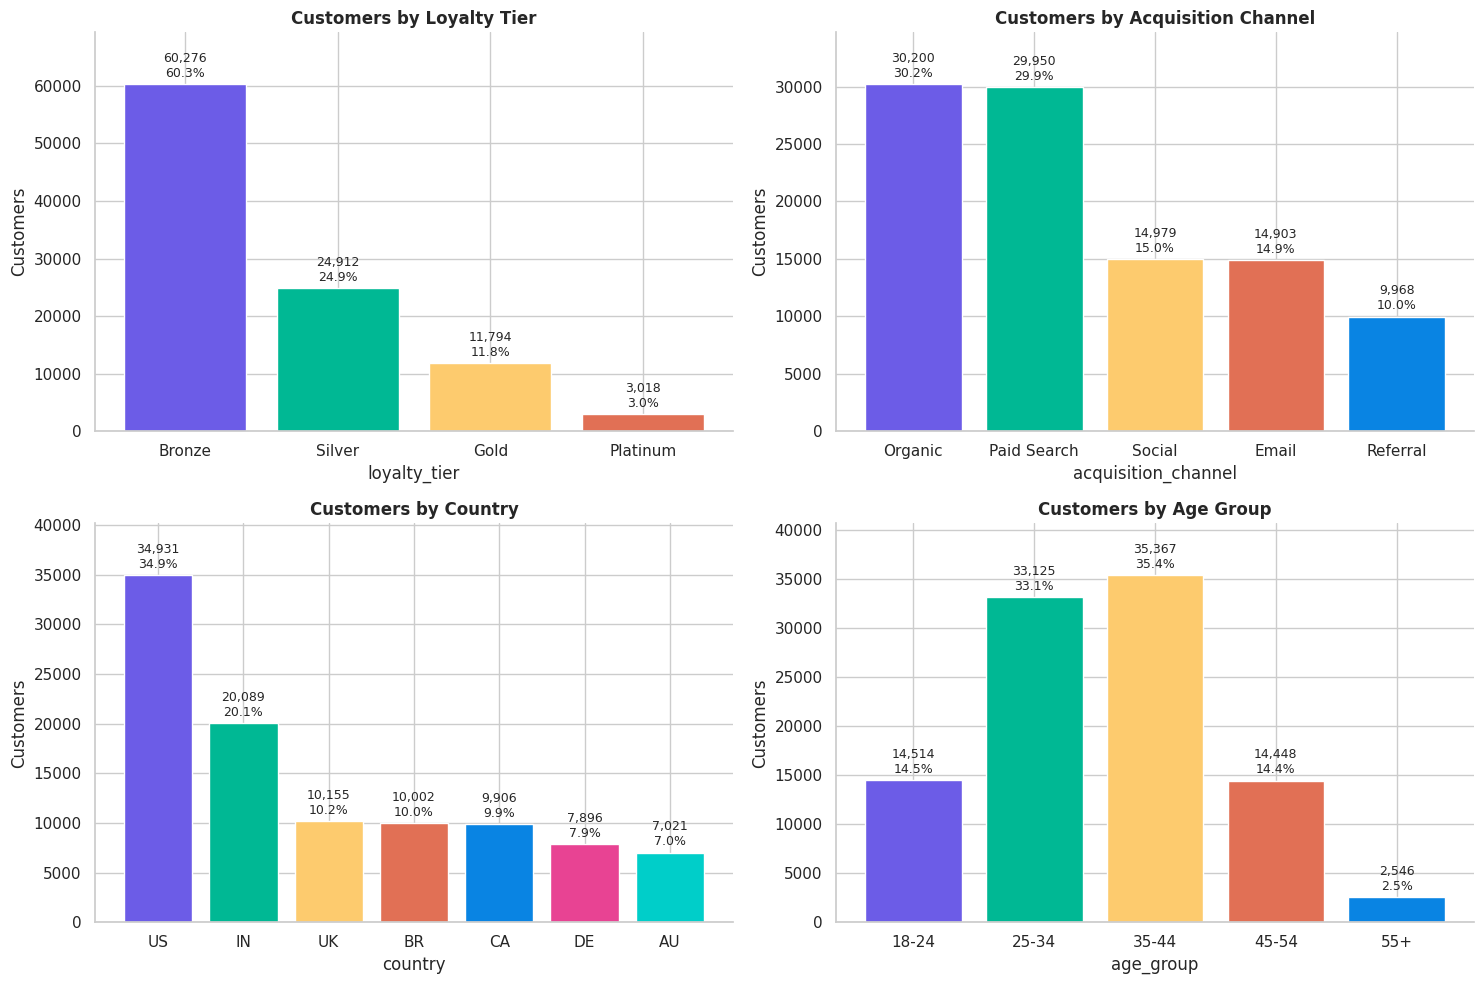

In [10]:
PALETTE = ["#6C5CE7", "#00B894", "#FDCB6E", "#E17055", "#0984E3", "#E84393", "#00CEC9", "#A29BFE"]

def bar_panel(ax, labels, values, title, xlabel="", ylabel="", colors=None, fmt="{:,.0f}", extra=None, rotation=0, ylim_pad=1.15):
    """Bar chart with value labels, styled consistently across the notebook."""
    colors = colors or PALETTE[: len(labels)]
    bars = ax.bar(labels, values, color=colors)
    texts = [fmt.format(v) + (f"\n{e}" if extra is not None else "") for v, e in zip(values, extra if extra is not None else values)]
    ax.bar_label(bars, labels=texts, padding=3, fontsize=9)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=rotation)
    ax.set_ylim(0, max(values) * ylim_pad if len(values) else 1)
    sns.despine(ax=ax)

# Customers: SQL summaries
q_tier = run_sql("""
SELECT loyalty_tier, COUNT(*) AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM customers
GROUP BY loyalty_tier
""").set_index("loyalty_tier").reindex(TIER_ORDER).reset_index()

q_acq = run_sql("""
SELECT acquisition_channel, COUNT(*) AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM customers
GROUP BY acquisition_channel
ORDER BY customers DESC
""")

q_country = run_sql("""
SELECT country, COUNT(*) AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM customers
GROUP BY country
ORDER BY customers DESC
""")

q_age = run_sql("""
SELECT age_group, COUNT(*) AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct,
       ROUND(AVG(age), 1) AS avg_age
FROM customers
GROUP BY age_group
ORDER BY age_group
""")

q_gender = run_sql("""
SELECT gender, COUNT(*) AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM customers
GROUP BY gender
ORDER BY customers DESC
""")

display(q_tier); display(q_acq); display(q_country); display(q_age); display(q_gender)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (d, col, title) in zip(axes.flatten(), [
    (q_tier, "loyalty_tier", "Customers by Loyalty Tier"),
    (q_acq, "acquisition_channel", "Customers by Acquisition Channel"),
    (q_country, "country", "Customers by Country"),
    (q_age, "age_group", "Customers by Age Group"),
]):
    bar_panel(ax, d[col], d["customers"], title, xlabel=col, ylabel="Customers",
              extra=[f"{p:.1f}%" for p in d["pct"]])
plt.tight_layout(); plt.show()

top_country = q_country.iloc[0]; top_tier = q_tier.sort_values("customers", ascending=False).iloc[0]
show_banner(
    "How to read the customer profile",
    f"<strong>{html.escape(str(top_tier['loyalty_tier']))}</strong> is the largest loyalty tier ({top_tier['pct']:.1f}% of customers) and "
    f"<strong>{html.escape(str(top_country['country']))}</strong> the largest country ({top_country['pct']:.1f}%). "
    f"Gold and Platinum together are {q_tier.loc[q_tier['loyalty_tier'].isin(['Gold','Platinum']), 'pct'].sum():.1f}% of the base. "
    "Group sizes matter later: a high conversion rate in a very small group is less reliable than a modest rate in a large one.",
    color="teal", icon="📊"
)

,category,products,avg_price,min_price,max_price,premium_pct
0,Electronics,455,130.45,33.53,464.58,95.40
1,Fashion,418,53.48,12.79,170.42,29.40
2,Home,396,86.84,25.15,301.83,73.70
3,Grocery,312,16.20,5.11,46.89,0.00
4,Sports,218,76.30,22.57,174.13,66.10
5,Beauty,201,32.59,8.90,88.05,3.50


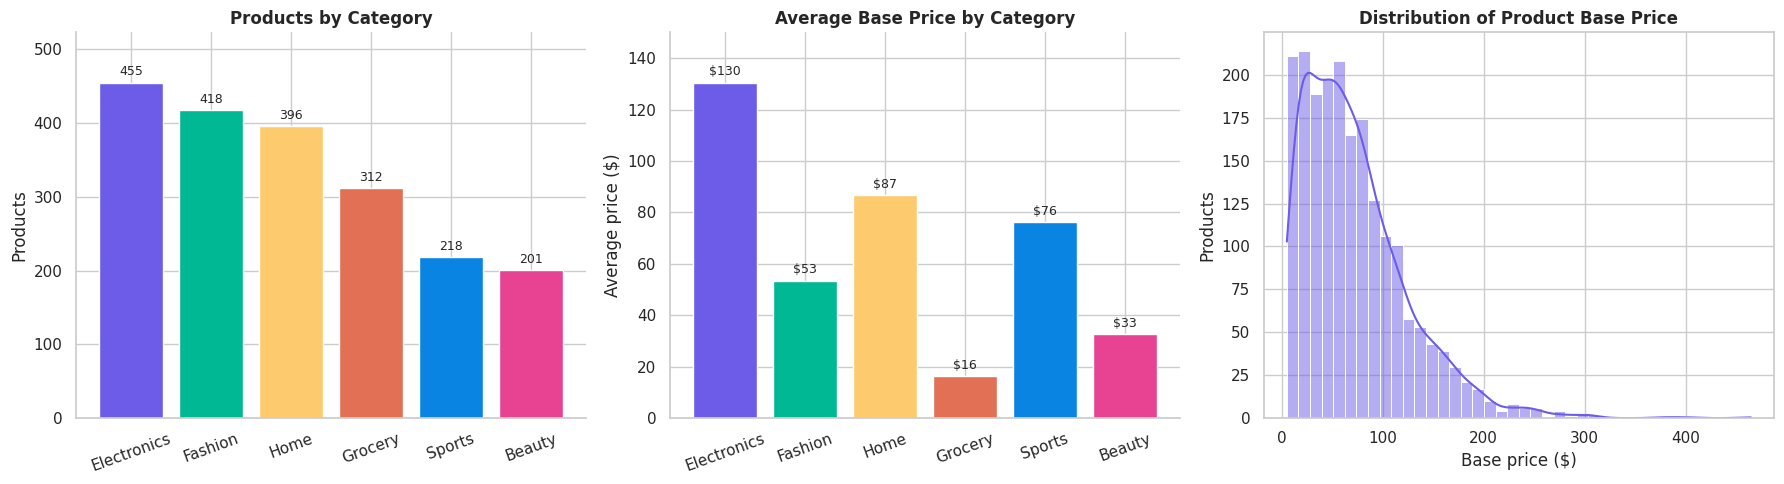

In [11]:
# Products: SQL summaries
q_cat = run_sql("""
SELECT category,
       COUNT(*)                            AS products,
       ROUND(AVG(base_price), 2)           AS avg_price,
       ROUND(MIN(base_price), 2)           AS min_price,
       ROUND(MAX(base_price), 2)           AS max_price,
       ROUND(100.0 * AVG(is_premium), 1)   AS premium_pct
FROM products
GROUP BY category
ORDER BY products DESC
""")
display(q_cat)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
bar_panel(axes[0], q_cat["category"], q_cat["products"], "Products by Category", ylabel="Products", rotation=20)
bar_panel(axes[1], q_cat["category"], q_cat["avg_price"], "Average Base Price by Category", ylabel="Average price ($)", fmt="${:,.0f}", rotation=20)
sns.histplot(prod["base_price"], bins=40, kde=True, color=PALETTE[0], ax=axes[2])
axes[2].set_title("Distribution of Product Base Price", fontweight="bold")
axes[2].set_xlabel("Base price ($)"); axes[2].set_ylabel("Products")
plt.tight_layout(); plt.show()

skew_price = prod["base_price"].skew()
priciest = q_cat.sort_values("avg_price", ascending=False).iloc[0]
show_banner(
    "How to read the product profile",
    f"<strong>{html.escape(str(q_cat.iloc[0]['category']))}</strong> has the most products ({int(q_cat.iloc[0]['products']):,}), and "
    f"<strong>{html.escape(str(priciest['category']))}</strong> has the highest average price (${priciest['avg_price']:,.2f}). "
    f"Base price is right-skewed (skew = {skew_price:.2f}; median ${prod['base_price'].median():,.2f} vs mean ${prod['base_price'].mean():,.2f}), "
    "so compare medians as well as averages. Catalogue size does not show how well each category sells, that is analysed in Section 13.",
    color="purple", icon="🧩"
)

## 6. Conversion funnel analysis

The funnel follows the stages **view → click → add to cart → purchase**. `bounce` is tracked separately because it is a drop-off, not a step forward.

> **Important limitation.** `session_id` is almost always unique to a single event, so events cannot be chained into real user journeys. The funnel below is therefore built from **event counts** (how many events of each type exist), not from tracking the same user through each step. Step ratios such as *Click ÷ View* describe the shape of the activity, not the share of individual users who progressed.

**Primary conversion metric used in this notebook:** *purchase rate* = purchase events ÷ all events.

,event_type,events,customers,pct_of_events
0,view,1043573,99997,52.18
1,click,379008,97725,18.95
2,add_to_cart,284370,94228,14.22
3,bounce,189922,85048,9.50
4,purchase,103127,64035,5.16


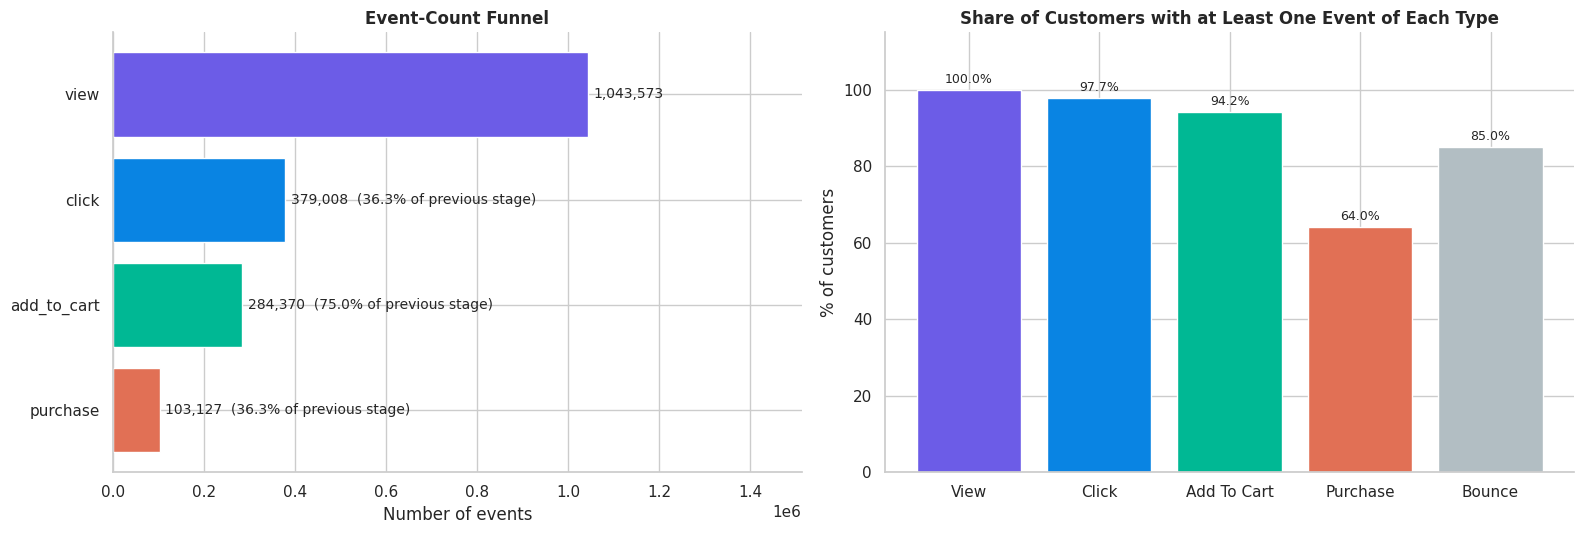

In [12]:
funnel_counts = run_sql("""
SELECT event_type,
       COUNT(*)                                          AS events,
       COUNT(DISTINCT customer_id)                       AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_events
FROM events
GROUP BY event_type
ORDER BY events DESC
""")
display(funnel_counts)

stages = ["view", "click", "add_to_cart", "purchase"]
fc = funnel_counts.set_index("event_type")
stage_events = [int(fc.loc[s, "events"]) for s in stages]
step_ratio = [np.nan] + [stage_events[i] / stage_events[i - 1] * 100 for i in range(1, len(stages))]
overall_purchase_rate = fc.loc["purchase", "events"] / fc["events"].sum() * 100
n_customers = len(customers)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
funnel_colors = ["#6C5CE7", "#0984E3", "#00B894", "#E17055"]
bars = axes[0].barh(stages[::-1], stage_events[::-1], color=funnel_colors[::-1])
labels = []
for i in range(len(stages) - 1, -1, -1):
    base = f"{stage_events[i]:,}"
    labels.append(base if i == 0 else f"{base}  ({step_ratio[i]:.1f}% of previous stage)")
axes[0].bar_label(bars, labels=labels, padding=4, fontsize=10)
axes[0].set_xlim(0, max(stage_events) * 1.45)
axes[0].set_title("Event-Count Funnel", fontweight="bold"); axes[0].set_xlabel("Number of events")
sns.despine(ax=axes[0])

reach = fc.loc[stages + ["bounce"], "customers"] / n_customers * 100
bar_panel(axes[1], [s.replace("_", " ").title() for s in reach.index], reach.values,
          "Share of Customers with at Least One Event of Each Type", ylabel="% of customers", fmt="{:.1f}%",
          colors=funnel_colors + ["#B2BEC3"])
plt.tight_layout(); plt.show()

FINDINGS["overall_purchase_rate"] = overall_purchase_rate
FINDINGS["buyer_share"] = fc.loc["purchase", "customers"] / n_customers * 100

show_cards([
    {"title": "Overall purchase rate", "body": f"<strong>{overall_purchase_rate:.2f}%</strong> of all events are purchases", "color": "green", "icon": "🛒"},
    {"title": "Biggest drop-off", "body": f"Only <strong>{step_ratio[3]:.1f}%</strong> as many purchase events as add-to-cart events; "
                                          f"<strong>{step_ratio[2]:.1f}%</strong> as many carts as clicks", "color": "orange", "icon": "🔻"},
    {"title": "Bounce share", "body": f"<strong>{fc.loc['bounce', 'pct_of_events']:.1f}%</strong> of events are bounces", "color": "red", "icon": "↩️"},
    {"title": "Customer reach", "body": f"<strong>{FINDINGS['buyer_share']:.1f}%</strong> of customers have at least one purchase event", "color": "blue", "icon": "👥"},
], columns=4)

### 6.1 Funnel by segment

The same funnel is repeated for each traffic source, device, loyalty tier, page category and experiment group. SQL conditional aggregation (`SUM(event_type = 'view')`) creates one row per segment.

Funnel by Traffic source


,segment,events,views,clicks,carts,purchases,bounces,click_per_view_%,cart_per_click_%,purchase_per_cart_%,purchase_rate_%,bounce_rate_%
0,Organic,800489,430833,156328,117858,16755,78715,36.29,75.39,14.22,2.09,9.83
1,Direct,199762,107740,38987,29368,4200,19467,36.19,75.33,14.30,2.10,9.75
2,Email,299640,150240,54591,40922,26636,27251,36.34,74.96,65.09,8.89,9.09
3,Paid Search,399838,201321,73653,54516,33633,36715,36.58,74.02,61.69,8.41,9.18
4,Social,300271,153439,55449,41706,21903,27774,36.14,75.22,52.52,7.29,9.25


Funnel by Device


,segment,events,views,clicks,carts,purchases,bounces,click_per_view_%,cart_per_click_%,purchase_per_cart_%,purchase_rate_%,bounce_rate_%
0,tablet,98121,51013,18926,13766,5071,9345,37.10,72.74,36.84,5.17,9.52
1,mobile,1176146,613828,222896,167285,60657,111480,36.31,75.05,36.26,5.16,9.48
2,desktop,685433,357777,129562,97487,35323,65284,36.21,75.24,36.23,5.15,9.52
3,Unknown,40300,20955,7624,5832,2076,3813,36.38,76.50,35.60,5.15,9.46


Funnel by Loyalty tier


,segment,events,views,clicks,carts,purchases,bounces,click_per_view_%,cart_per_click_%,purchase_per_cart_%,purchase_rate_%,bounce_rate_%
0,Bronze,1205206,632636,229659,172352,55232,115327,36.30,75.05,32.05,4.58,9.57
1,Silver,498393,259019,93738,70754,28005,46877,36.19,75.48,39.58,5.62,9.41
2,Gold,235803,120807,44229,32758,15906,22103,36.61,74.06,48.56,6.75,9.37
3,Platinum,60598,31111,11382,8506,3984,5615,36.59,74.73,46.84,6.57,9.27


Funnel by Page category


,segment,events,views,clicks,carts,purchases,bounces,click_per_view_%,cart_per_click_%,purchase_per_cart_%,purchase_rate_%,bounce_rate_%
0,Checkout,199871,104001,37709,28474,10399,19288,36.26,75.51,36.52,5.20,9.65
1,Home,399723,208312,75879,57002,20719,37811,36.43,75.12,36.35,5.18,9.46
2,PLP,601284,313258,114401,85390,31082,57153,36.52,74.64,36.40,5.17,9.51
3,PDP,599638,313841,113021,85154,30794,56828,36.01,75.34,36.16,5.14,9.48
4,Cart,199484,104161,37998,28350,10133,18842,36.48,74.61,35.74,5.08,9.45


Funnel by Experiment group


,segment,events,views,clicks,carts,purchases,bounces,click_per_view_%,cart_per_click_%,purchase_per_cart_%,purchase_rate_%,bounce_rate_%
0,Control,1198404,628630,227428,170912,56855,114579,36.18,75.15,33.27,4.74,9.56
1,Variant_A,401413,208655,76463,57100,21045,38150,36.65,74.68,36.86,5.24,9.50
2,Variant_B,400183,206288,75117,56358,25227,37193,36.41,75.03,44.76,6.30,9.29


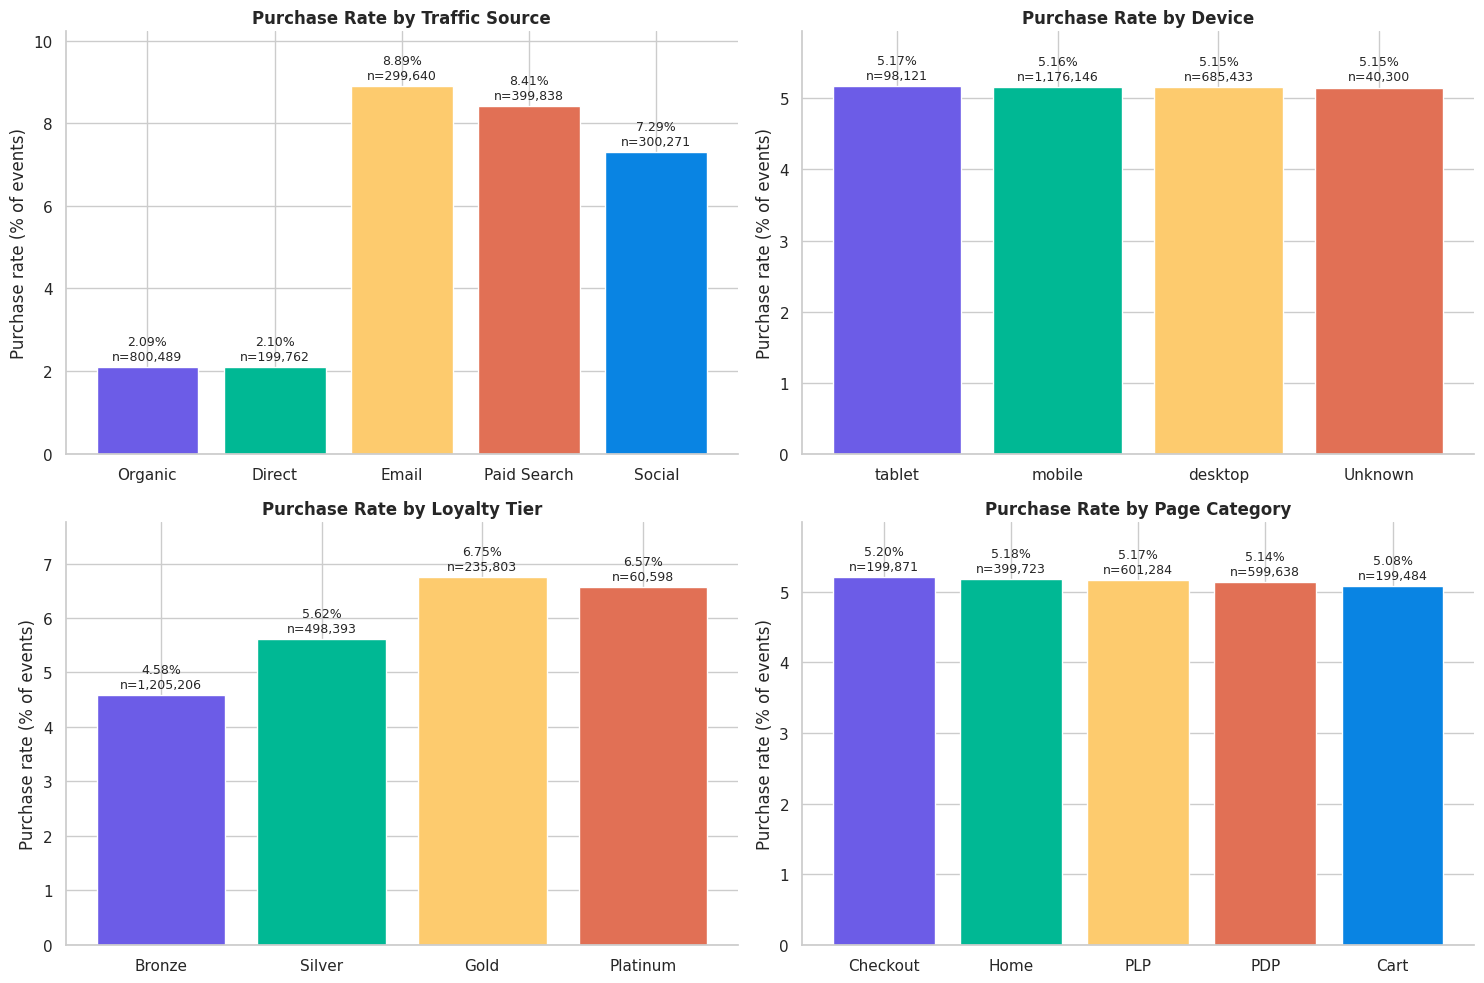

In [13]:
def funnel_by(dim_expr, join_sql="", order=None):
    q = f"""
    SELECT {dim_expr} AS segment,
           COUNT(*)                          AS events,
           SUM(e.event_type = 'view')        AS views,
           SUM(e.event_type = 'click')       AS clicks,
           SUM(e.event_type = 'add_to_cart') AS carts,
           SUM(e.event_type = 'purchase')    AS purchases,
           SUM(e.event_type = 'bounce')      AS bounces
    FROM events e
    {join_sql}
    GROUP BY 1
    """
    out = run_sql(q)
    out["click_per_view_%"] = out["clicks"] / out["views"] * 100
    out["cart_per_click_%"] = out["carts"] / out["clicks"] * 100
    out["purchase_per_cart_%"] = out["purchases"] / out["carts"] * 100
    out["purchase_rate_%"] = out["purchases"] / out["events"] * 100
    out["bounce_rate_%"] = out["bounces"] / out["events"] * 100
    if order:
        out = out.set_index("segment").reindex(order).reset_index()
    else:
        out = out.sort_values("purchase_rate_%", ascending=False).reset_index(drop=True)
    return out

f_source = funnel_by("e.traffic_source", order=SOURCE_ORDER)
f_device = funnel_by("e.device_type")
f_tier   = funnel_by("c.loyalty_tier", "JOIN customers c ON c.customer_id = e.customer_id", order=TIER_ORDER)
f_page   = funnel_by("e.page_category")
f_group  = funnel_by("e.experiment_group", order=GROUP_ORDER)

for name, tbl in [("Traffic source", f_source), ("Device", f_device), ("Loyalty tier", f_tier),
                  ("Page category", f_page), ("Experiment group", f_group)]:
    print(f"Funnel by {name}")
    display(tbl)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (tbl, title) in zip(axes.flatten(), [
    (f_source, "Purchase Rate by Traffic Source"), (f_device, "Purchase Rate by Device"),
    (f_tier, "Purchase Rate by Loyalty Tier"), (f_page, "Purchase Rate by Page Category"),
]):
    bar_panel(ax, tbl["segment"], tbl["purchase_rate_%"], title, ylabel="Purchase rate (% of events)", fmt="{:.2f}%",
              extra=[f"n={n:,.0f}" for n in tbl["events"]])
plt.tight_layout(); plt.show()

def spread(tbl):
    hi, lo = tbl.loc[tbl["purchase_rate_%"].idxmax()], tbl.loc[tbl["purchase_rate_%"].idxmin()]
    return hi["segment"], hi["purchase_rate_%"], lo["segment"], lo["purchase_rate_%"]

s_hi, s_hv, s_lo, s_lv = spread(f_source)
d_hi, d_hv, d_lo, d_lv = spread(f_device)
t_hi, t_hv, t_lo, t_lv = spread(f_tier)
show_banner(
    "What the segment funnels show",
    f"<ul><li><strong>Traffic source</strong> separates conversion most: <strong>{html.escape(str(s_hi))}</strong> ({s_hv:.2f}%) vs "
    f"<strong>{html.escape(str(s_lo))}</strong> ({s_lv:.2f}%), a {s_hv / s_lv:.1f}x gap.</li>"
    f"<li><strong>Loyalty tier</strong>: {html.escape(str(t_hi))} ({t_hv:.2f}%) vs {html.escape(str(t_lo))} ({t_lv:.2f}%).</li>"
    + (f"<li><strong>Device</strong> barely matters: {d_lo} {d_lv:.2f}% vs {d_hi} {d_hv:.2f}%.</li></ul>" if (d_hv - d_lv) < 0.25 else
       f"<li><strong>Device</strong> also differs: {d_hi} {d_hv:.2f}% vs {d_lo} {d_lv:.2f}%.</li></ul>")
    +
    "These are descriptive differences. Traffic source and campaign exposure overlap heavily (Section 7), so they should not be read as independent effects.",
    color="blue", icon="💡"
)
FINDINGS.update({"src_hi": s_hi, "src_hi_rate": s_hv, "src_lo": s_lo, "src_lo_rate": s_lv})

## 7. Marketing campaign effectiveness

Campaign exposure is recorded on every event (`campaign_id`; **0 = no campaign**). This section compares exposed and unexposed events, checks how exposure relates to traffic source, and then compares campaigns by their design (channel, objective, target segment).

**How to read this section:** a higher purchase rate among exposed events is *association*, not proof that the campaign caused the difference. Section 7.2 shows why that matters in this dataset.

,exposure,events,purchases,purchase_rate_pct
0,No campaign,1000251,20955,2.10
1,Exposed to a campaign,999749,82172,8.22


,Exposed rate (%),Unexposed rate (%),Difference (pp),95% CI low (pp),95% CI high (pp),Relative lift (%),z,p-value
0,8.22,2.09,6.12,6.06,6.19,292.33,195.82,<0.001


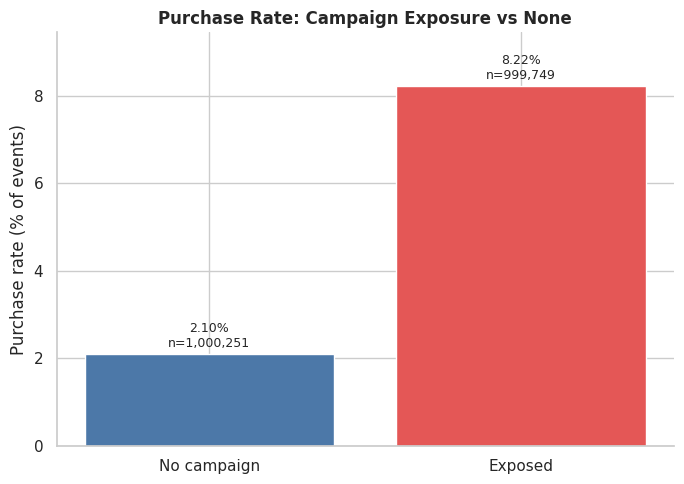

In [14]:
exposure = run_sql("""
SELECT CASE has_campaign WHEN 1 THEN 'Exposed to a campaign' ELSE 'No campaign' END AS exposure,
       COUNT(*)                            AS events,
       SUM(is_purchase)                    AS purchases,
       ROUND(100.0 * AVG(is_purchase), 3)  AS purchase_rate_pct
FROM events
GROUP BY has_campaign
ORDER BY has_campaign
""")
display(exposure)

e0 = exposure.iloc[0]; e1 = exposure.iloc[1]
exp_test = two_prop_test(e1["purchases"], e1["events"], e0["purchases"], e0["events"])
exp_df = pd.DataFrame([{
    "Exposed rate (%)": exp_test["rate_treat"] * 100, "Unexposed rate (%)": exp_test["rate_ctrl"] * 100,
    "Difference (pp)": exp_test["diff"] * 100,
    "95% CI low (pp)": exp_test["ci_low"] * 100, "95% CI high (pp)": exp_test["ci_high"] * 100,
    "Relative lift (%)": exp_test["rel_lift"] * 100, "z": exp_test["z"], "p-value": fmt_p(exp_test["p_value"]),
}])
display(exp_df)

fig, ax = plt.subplots(figsize=(7, 5))
bar_panel(ax, ["No campaign", "Exposed"], exposure["purchase_rate_pct"].values, "Purchase Rate: Campaign Exposure vs None",
          ylabel="Purchase rate (% of events)", fmt="{:.2f}%", colors=["#4C78A8", "#E45756"],
          extra=[f"n={n:,}" for n in exposure["events"]])
plt.tight_layout(); plt.show()

FINDINGS.update({"exp_rate": exp_test["rate_treat"] * 100, "unexp_rate": exp_test["rate_ctrl"] * 100,
                 "exp_diff_pp": exp_test["diff"] * 100, "exp_rel_lift": exp_test["rel_lift"] * 100})
show_banner(
    "Exposed vs unexposed",
    f"Events with campaign exposure convert at <strong>{exp_test['rate_treat']*100:.2f}%</strong> versus "
    f"<strong>{exp_test['rate_ctrl']*100:.2f}%</strong> without, a difference of <strong>{exp_test['diff']*100:.2f} percentage points</strong> "
    f"(relative lift {exp_test['rel_lift']*100:.0f}%, 95% CI {exp_test['ci_low']*100:.2f} to {exp_test['ci_high']*100:.2f} pp, p {html.escape(fmt_p(exp_test['p_value']))}). "
    "With two million events almost any difference is statistically significant, so judge the <em>size</em> of the gap, and first check what else differs between the two groups.",
    color="green", icon="📈"
)

### 7.2 Does exposure overlap with traffic source?

If every exposed event comes from paid channels and every unexposed event from organic or direct traffic, then "campaign effect" and "traffic-source effect" cannot be separated.

,traffic_source,events,exposed_events,exposed_pct,purchase_rate_pct
0,Organic,800489,0,0.00,2.09
1,Direct,199762,0,0.00,2.10
2,Email,299640,299640,100.00,8.89
3,Paid Search,399838,399838,100.00,8.41
4,Social,300271,300271,100.00,7.29


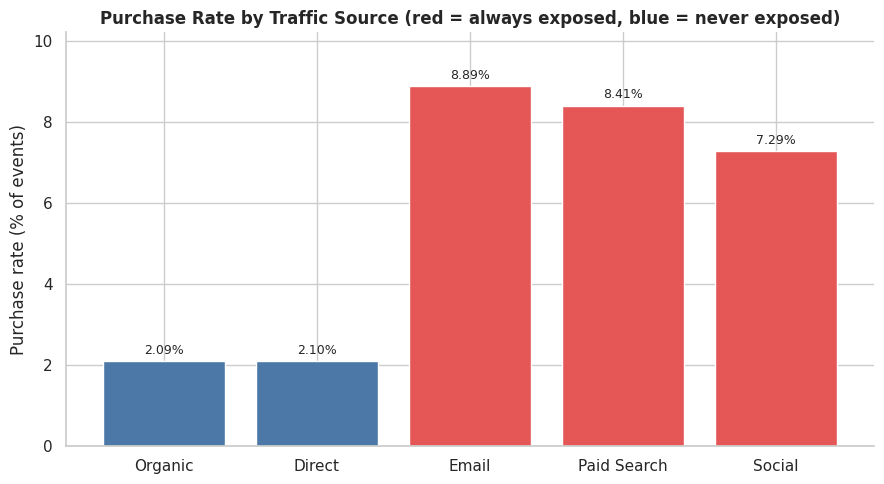

In [15]:
src_exposure = run_sql("""
SELECT traffic_source,
       COUNT(*)                                   AS events,
       SUM(has_campaign)                          AS exposed_events,
       ROUND(100.0 * AVG(has_campaign), 1)        AS exposed_pct,
       ROUND(100.0 * AVG(is_purchase), 3)         AS purchase_rate_pct
FROM events
GROUP BY traffic_source
""").set_index("traffic_source").reindex(SOURCE_ORDER).reset_index()
display(src_exposure)

fully_exposed = src_exposure.loc[src_exposure["exposed_pct"] >= 99.9, "traffic_source"].tolist()
never_exposed = src_exposure.loc[src_exposure["exposed_pct"] <= 0.1, "traffic_source"].tolist()
mixed = src_exposure.loc[(src_exposure["exposed_pct"] > 0.1) & (src_exposure["exposed_pct"] < 99.9), "traffic_source"].tolist()

fig, ax = plt.subplots(figsize=(9, 5))
cols = ["#E45756" if p >= 99.9 else ("#4C78A8" if p <= 0.1 else "#FDCB6E") for p in src_exposure["exposed_pct"]]
bar_panel(ax, src_exposure["traffic_source"], src_exposure["purchase_rate_pct"], "Purchase Rate by Traffic Source (red = always exposed, blue = never exposed)",
          ylabel="Purchase rate (% of events)", fmt="{:.2f}%", colors=cols)
plt.tight_layout(); plt.show()

confounded = len(mixed) == 0
FINDINGS.update({"fully_exposed": fully_exposed, "never_exposed": never_exposed, "confounded": confounded})
show_banner(
    "Campaign exposure and traffic source are not separable" if confounded else "Campaign exposure partly overlaps with traffic source",
    f"Always exposed: <strong>{', '.join(fully_exposed) or 'none'}</strong>. Never exposed: <strong>{', '.join(never_exposed) or 'none'}</strong>. "
    + ("Because the two never mix, the exposed-vs-unexposed gap is a comparison of <em>paid/owned channels</em> with <em>organic/direct traffic</em>. "
       "The data cannot say how much of the gap is the campaign itself and how much is the channel. A proper campaign-lift estimate needs a holdout within each channel."
       if confounded else "Some sources contain both exposed and unexposed events, so lift can be compared within those sources."),
    color="red", icon="⚠️"
)

Purchase rate by campaign channel (baseline without campaign = 2.09%)


,channel,campaigns,events,purchases,avg_expected_uplift_pct,purchase_rate_%,observed_uplift_pp
0,Affiliate,11,220077,19694,9.86,8.95,6.85
1,Paid Search,11,219726,18841,9.35,8.57,6.48
2,Display,9,180397,14995,8.91,8.31,6.22
3,Email,11,219959,16741,7.49,7.61,5.52
4,Social,8,159590,11901,7.41,7.46,5.36


Purchase rate by campaign objective (baseline without campaign = 2.09%)


,objective,campaigns,events,purchases,avg_expected_uplift_pct,purchase_rate_%,observed_uplift_pp
0,Retention,13,260921,22239,9.26,8.52,6.43
1,Cross-sell,12,239844,19647,8.52,8.19,6.10
2,Acquisition,10,199174,16113,8.46,8.09,5.99
3,Reactivation,15,299810,24173,8.41,8.06,5.97


Purchase rate by target segment (baseline without campaign = 2.09%)


,target_segment,campaigns,events,purchases,avg_expected_uplift_pct,purchase_rate_%,observed_uplift_pp
0,All,8,160046,13900,9.55,8.69,6.59
1,New Customers,12,239513,20745,9.40,8.66,6.57
2,High Value,9,180518,15075,8.84,8.35,6.26
3,Deal Seekers,10,199954,16325,8.64,8.16,6.07
4,Churn Risk,11,219718,16127,7.10,7.34,5.24


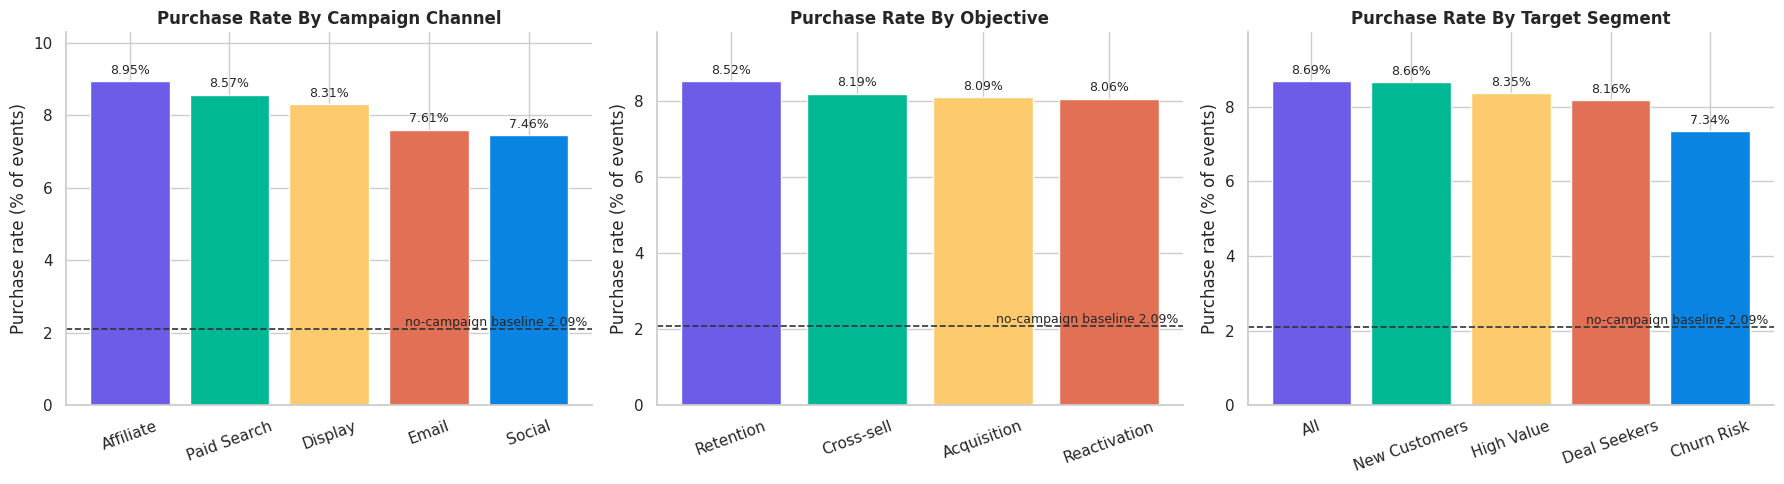

In [16]:
# Campaign-level performance (SQL join of events to the campaigns table)
camp_perf = run_sql("""
SELECT c.campaign_id, c.channel, c.objective, c.target_segment, c.expected_uplift,
       COUNT(*)            AS events,
       SUM(e.is_purchase)  AS purchases
FROM events e
JOIN campaigns c ON c.campaign_id = e.campaign_id
GROUP BY c.campaign_id, c.channel, c.objective, c.target_segment, c.expected_uplift
""")
camp_perf["purchase_rate_%"] = camp_perf["purchases"] / camp_perf["events"] * 100
baseline_rate = exp_test["rate_ctrl"] * 100
camp_perf["observed_uplift_pp"] = camp_perf["purchase_rate_%"] - baseline_rate
camp_perf["expected_uplift_%"] = camp_perf["expected_uplift"] * 100

def design_summary(col):
    g = camp_perf.groupby(col).agg(campaigns=("campaign_id", "nunique"), events=("events", "sum"), purchases=("purchases", "sum"),
                                   avg_expected_uplift_pct=("expected_uplift_%", "mean")).reset_index()
    g["purchase_rate_%"] = g["purchases"] / g["events"] * 100
    g["observed_uplift_pp"] = g["purchase_rate_%"] - baseline_rate
    return g.sort_values("purchase_rate_%", ascending=False).reset_index(drop=True)

by_channel, by_objective, by_segment = design_summary("channel"), design_summary("objective"), design_summary("target_segment")
for name, tbl in [("campaign channel", by_channel), ("campaign objective", by_objective), ("target segment", by_segment)]:
    print(f"Purchase rate by {name} (baseline without campaign = {baseline_rate:.2f}%)")
    display(tbl)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (tbl, col, title) in zip(axes, [(by_channel, "channel", "By Campaign Channel"), (by_objective, "objective", "By Objective"),
                                        (by_segment, "target_segment", "By Target Segment")]):
    bar_panel(ax, tbl[col], tbl["purchase_rate_%"], f"Purchase Rate {title}", ylabel="Purchase rate (% of events)",
              fmt="{:.2f}%", rotation=20)
    ax.axhline(baseline_rate, color="#2D3436", linestyle="--", linewidth=1.2)
    ax.text(0.99, baseline_rate, f" no-campaign baseline {baseline_rate:.2f}%", transform=ax.get_yaxis_transform(),
            ha="right", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

best_ch, worst_ch = by_channel.iloc[0], by_channel.iloc[-1]
FINDINGS.update({"best_channel": best_ch["channel"], "best_channel_rate": best_ch["purchase_rate_%"],
                 "worst_channel": worst_ch["channel"], "worst_channel_rate": worst_ch["purchase_rate_%"]})
show_banner(
    "What the campaign design shows",
    f"By campaign channel, <strong>{html.escape(str(best_ch['channel']))}</strong> has the highest purchase rate ({best_ch['purchase_rate_%']:.2f}%) and "
    f"<strong>{html.escape(str(worst_ch['channel']))}</strong> the lowest ({worst_ch['purchase_rate_%']:.2f}%). "
    + (f"Every design group sits above the {baseline_rate:.2f}% no-campaign baseline. " if min(by_channel['purchase_rate_%'].min(), by_objective['purchase_rate_%'].min(), by_segment['purchase_rate_%'].min()) > baseline_rate else
       f"Some design groups fall below the {baseline_rate:.2f}% no-campaign baseline. ")
    + f"The spread <em>between</em> channels ({best_ch['purchase_rate_%'] - worst_ch['purchase_rate_%']:.2f} pp) is "
    + ("much smaller than" if (best_ch['purchase_rate_%'] - worst_ch['purchase_rate_%']) < 0.5 * exp_test['diff'] * 100 else "comparable to")
    + f" the gap between exposed and unexposed events ({exp_test['diff']*100:.2f} pp)"
    + (", so channel, objective and segment matter less than whether an event is attributed to a campaign at all." if (best_ch['purchase_rate_%'] - worst_ch['purchase_rate_%']) < 0.5 * exp_test['diff'] * 100 else "."),
    color="purple", icon="🎯"
)

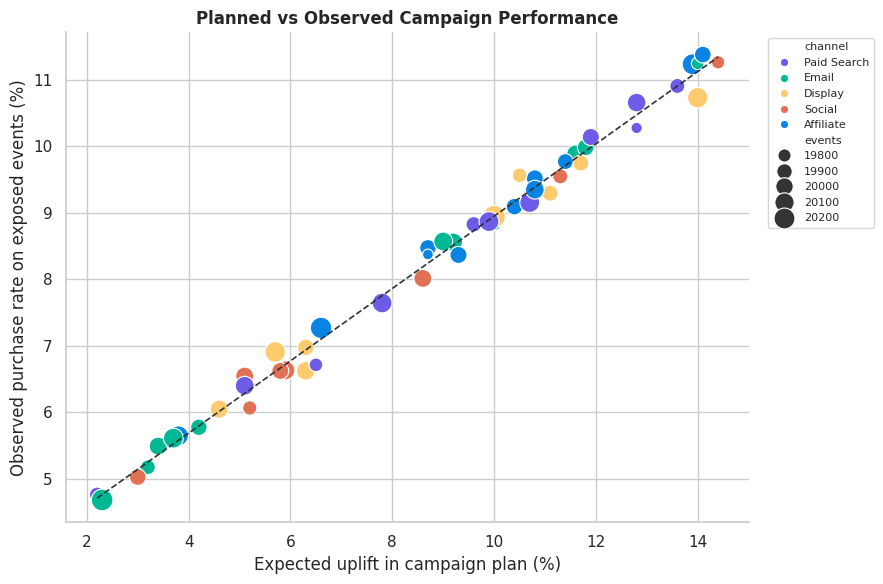

Top 5 campaigns by purchase rate


,campaign_id,channel,objective,target_segment,expected_uplift_%,events,purchase_rate_%,observed_uplift_pp
0,44,Affiliate,Reactivation,All,14.10,19959,11.38,9.28
1,5,Social,Acquisition,New Customers,14.40,19809,11.26,9.17
2,29,Email,Acquisition,New Customers,14.00,19775,11.25,9.15
3,18,Affiliate,Retention,All,13.90,20199,11.23,9.14
4,7,Paid Search,Cross-sell,High Value,13.60,19878,10.91,8.81


Bottom 5 campaigns by purchase rate


,campaign_id,channel,objective,target_segment,expected_uplift_%,events,purchase_rate_%,observed_uplift_pp
0,50,Email,Retention,Churn Risk,2.30,20247,4.68,2.58
1,1,Paid Search,Cross-sell,Deal Seekers,2.20,19885,4.76,2.66
2,46,Social,Cross-sell,All,3.00,19954,5.02,2.93
3,12,Email,Acquisition,Churn Risk,3.20,19863,5.17,3.08
4,10,Email,Cross-sell,Churn Risk,3.40,20025,5.49,3.39


In [17]:
# Expected vs observed performance per campaign
pearson_r, pearson_p = stats.pearsonr(camp_perf["expected_uplift_%"], camp_perf["purchase_rate_%"])
spearman_r, spearman_p = stats.spearmanr(camp_perf["expected_uplift_%"], camp_perf["purchase_rate_%"])
slope, intercept, *_ = stats.linregress(camp_perf["expected_uplift_%"], camp_perf["purchase_rate_%"])

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=camp_perf, x="expected_uplift_%", y="purchase_rate_%", hue="channel", size="events", sizes=(60, 260),
                palette=PALETTE[:5], ax=ax)
xs = np.linspace(camp_perf["expected_uplift_%"].min(), camp_perf["expected_uplift_%"].max(), 50)
ax.plot(xs, intercept + slope * xs, color="#2D3436", linestyle="--", linewidth=1.2)
ax.set_title("Planned vs Observed Campaign Performance", fontweight="bold")
ax.set_xlabel("Expected uplift in campaign plan (%)"); ax.set_ylabel("Observed purchase rate on exposed events (%)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
sns.despine(); plt.tight_layout(); plt.show()

show_cols = ["campaign_id", "channel", "objective", "target_segment", "expected_uplift_%", "events", "purchase_rate_%", "observed_uplift_pp"]
print("Top 5 campaigns by purchase rate")
display(camp_perf.sort_values("purchase_rate_%", ascending=False)[show_cols].head(5).reset_index(drop=True))
print("Bottom 5 campaigns by purchase rate")
display(camp_perf.sort_values("purchase_rate_%")[show_cols].head(5).reset_index(drop=True))

FINDINGS["plan_vs_obs_r"] = pearson_r
show_banner(
    "Did the campaign plan predict results?",
    f"Across {len(camp_perf)} campaigns, planned <code>expected_uplift</code> and the observed purchase rate have a Pearson correlation of "
    f"<strong>r = {pearson_r:.2f}</strong> (Spearman {spearman_r:.2f}). "
    + ("Campaigns planned to perform better did perform better, so the planning assumptions are consistent with the recorded behaviour. " if pearson_r >= 0.5 else
       "The plan is only weakly related to the recorded results, so the planning assumptions should be reviewed. ")
    + "The two measures are on different scales, so use the correlation (the ranking), not the raw gap. "
    + ("In a real business a correlation this close to 1 would be unusual and worth double-checking; here it most likely reflects how the synthetic data was generated." if pearson_r >= 0.95 else ""),
    color="teal", icon="🔍"
)

In [18]:
# Are exposed events concentrated inside the campaign start/end window?
window_check = run_sql("""
SELECT CASE WHEN date(e.timestamp) BETWEEN c.start_date AND c.end_date
            THEN 'Inside campaign window' ELSE 'Outside campaign window' END AS window_status,
       COUNT(*)                            AS events,
       SUM(e.is_purchase)                  AS purchases,
       ROUND(100.0 * AVG(e.is_purchase), 3) AS purchase_rate_pct
FROM events e
JOIN campaigns c ON c.campaign_id = e.campaign_id
GROUP BY 1
ORDER BY 1
""")
window_check["share_of_exposed_events_%"] = window_check["events"] / window_check["events"].sum() * 100
display(window_check)

w_in = window_check.loc[window_check["window_status"].str.startswith("Inside")].iloc[0]
w_out = window_check.loc[window_check["window_status"].str.startswith("Outside")].iloc[0]
show_banner(
    "Campaign dates do not constrain exposure",
    f"Only <strong>{w_in['share_of_exposed_events_%']:.1f}%</strong> of exposed events fall inside the campaign's own start and end dates, and the purchase rate is "
    f"{w_in['purchase_rate_pct']:.2f}% inside vs {w_out['purchase_rate_pct']:.2f}% outside the window. "
    "In practice <code>campaign_id</code> works as an exposure label, not as a dated activity. For this reason the notebook does not attempt a before/after-campaign analysis.",
    color="yellow", icon="📅"
)

,window_status,events,purchases,purchase_rate_pct,share_of_exposed_events_%
0,Inside campaign window,47467,4070,8.57,4.75
1,Outside campaign window,952282,78102,8.20,95.25


## 8. A/B testing: experiment groups

Every event carries an `experiment_group`: **Control**, **Variant_A** or **Variant_B**. The analysis follows four steps:

1. **Check the design**: is the split what was intended, and are the groups comparable?
2. **Compare conversion**: purchase rate per group, with confidence intervals.
3. **Test significance and size**: two-proportion z-tests against Control, with false-discovery-rate adjustment.
4. **Look deeper**: do effects differ by segment, hold after adjustment, and translate into revenue?

> **Design caveat found in Section 3.** Assignment happens **per event**, not per customer, so almost every customer appears in all three groups. The tests below treat events as the unit of analysis; a cluster-robust model in Section 8.5 checks whether that choice changes the conclusion.

In [19]:
# Design check: group sizes, split and balance
group_sizes = run_sql("""
SELECT experiment_group,
       COUNT(*)                                            AS events,
       COUNT(DISTINCT customer_id)                         AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)  AS pct_of_events
FROM events
GROUP BY experiment_group
""").set_index("experiment_group").reindex(GROUP_ORDER).reset_index()
display(group_sizes)

# How many groups does each customer appear in?
groups_per_cust = run_sql("""
SELECT n_groups, COUNT(*) AS customers, ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM (SELECT customer_id, COUNT(DISTINCT experiment_group) AS n_groups FROM events GROUP BY customer_id)
GROUP BY n_groups
ORDER BY n_groups
""")
display(groups_per_cust)

# Sample-ratio check against the observed 60 / 20 / 20 design
observed = group_sizes["events"].values
expected_share = np.array([0.6, 0.2, 0.2])
srm_chi2, srm_p = stats.chisquare(observed, f_exp=expected_share * observed.sum())

# Balance: are traffic source, loyalty tier, device and exposure distributed equally across groups?
bal = ev.merge(cust[["customer_id", "loyalty_tier"]], on="customer_id")
balance_rows = []
for col in ["traffic_source", "loyalty_tier", "device_type", "has_campaign", "page_category", "holiday_season", "is_weekend"]:
    chi2, p, dof, v = cramers_v(pd.crosstab(bal["experiment_group"], bal[col]))
    balance_rows.append({"Variable": col, "Chi-square": chi2, "p-value": p, "Cramér's V": v})
balance = pd.DataFrame(balance_rows)
balance["q-value (BH)"] = benjamini_hochberg(balance["p-value"])
balance["Balanced (q ≥ 0.05)"] = np.where(balance["q-value (BH)"] >= 0.05, "✅ Yes", "⚠️ No")
balance_show = balance.copy()
balance_show["p-value"] = balance_show["p-value"].map(fmt_p)
balance_show["q-value (BH)"] = balance_show["q-value (BH)"].map(fmt_p)
balance_show["Cramér's V"] = balance_show["Cramér's V"].map(lambda x: f"{x:.5f}")
display(balance_show)

multi_pct = groups_per_cust.loc[groups_per_cust["n_groups"] > 1, "pct"].sum()
all_balanced = bool((balance["q-value (BH)"] >= 0.05).all())
max_bal_v = float(balance["Cramér's V"].max())
show_cards([
    {"title": "Split of events", "body": " / ".join(f"{g}: <strong>{p:.1f}%</strong>" for g, p in zip(group_sizes["experiment_group"], group_sizes["pct_of_events"])),
     "color": "blue", "icon": "⚖️"},
    {"title": "Sample-ratio check (60/20/20)", "body": f"χ² = {srm_chi2:.2f}, p {html.escape(fmt_p(srm_p))}<br>" + ("No evidence of a sample-ratio problem (alarm threshold p &lt; 0.001)." if srm_p >= 0.001 else "Split deviates from 60/20/20: investigate before trusting results."),
     "color": "green" if srm_p >= 0.001 else "red", "icon": "🧪"},
    {"title": "Group balance", "body": ("All checked variables are balanced across groups." if all_balanced else "Some variables are unbalanced; interpret raw differences with care."),
     "color": "green" if all_balanced else "orange", "icon": "✅" if all_balanced else "⚠️"},
    {"title": "Customer overlap", "body": f"<strong>{multi_pct:.1f}%</strong> of customers appear in 2 or more groups", "color": "orange", "icon": "🔀"},
], columns=4)

show_banner(
    "What the design check tells us",
    ("The balance tests show no group differences on traffic source, loyalty tier, device and campaign exposure (all Cramér's V below "
     f"{max_bal_v:.3f}), so differences in purchase rate are unlikely to come from an uneven mix of events. " if all_balanced else
     "At least one variable is unevenly spread across groups, so the raw group comparison may be distorted; rely on the adjusted model in Section 8.5. ")
    + "The remaining weakness is the <strong>unit of randomisation</strong>: because customers are mixed across groups, a customer's behaviour in one group can "
    "spill into another, and events from the same customer are not fully independent.",
    color="blue", icon="💡"
)

,experiment_group,events,customers,pct_of_events
0,Control,1198404,100000,59.92
1,Variant_A,401413,98199,20.07
2,Variant_B,400183,98116,20.01


,n_groups,customers,pct
0,1,37,0.04
1,2,3611,3.61
2,3,96352,96.35


,Variable,Chi-square,p-value,Cramér's V,q-value (BH),Balanced (q ≥ 0.05)
0,traffic_source,6.41,0.602,0.00127,0.838,✅ Yes
1,loyalty_tier,16.74,0.010,0.00205,0.072,✅ Yes
2,device_type,3.69,0.719,0.00096,0.838,✅ Yes
3,has_campaign,0.14,0.934,0.00026,0.934,✅ Yes
4,page_category,8.03,0.431,0.00142,0.838,✅ Yes
5,holiday_season,0.78,0.677,0.00062,0.838,✅ Yes
6,is_weekend,0.95,0.623,0.00069,0.838,✅ Yes


### 8.2 Conversion rate by experiment group

The primary metric is the **purchase rate** (purchase events ÷ all events). Secondary metrics are the add-to-cart rate and the bounce rate, to see *where* in the funnel the variants change behaviour.

,experiment_group,events,purchases,carts,bounces,purchase_rate_%,cart_rate_%,bounce_rate_%
0,Control,1198404,56855,170912,114579,4.74,14.26,9.56
1,Variant_A,401413,21045,57100,38150,5.24,14.22,9.50
2,Variant_B,400183,25227,56358,37193,6.30,14.08,9.29


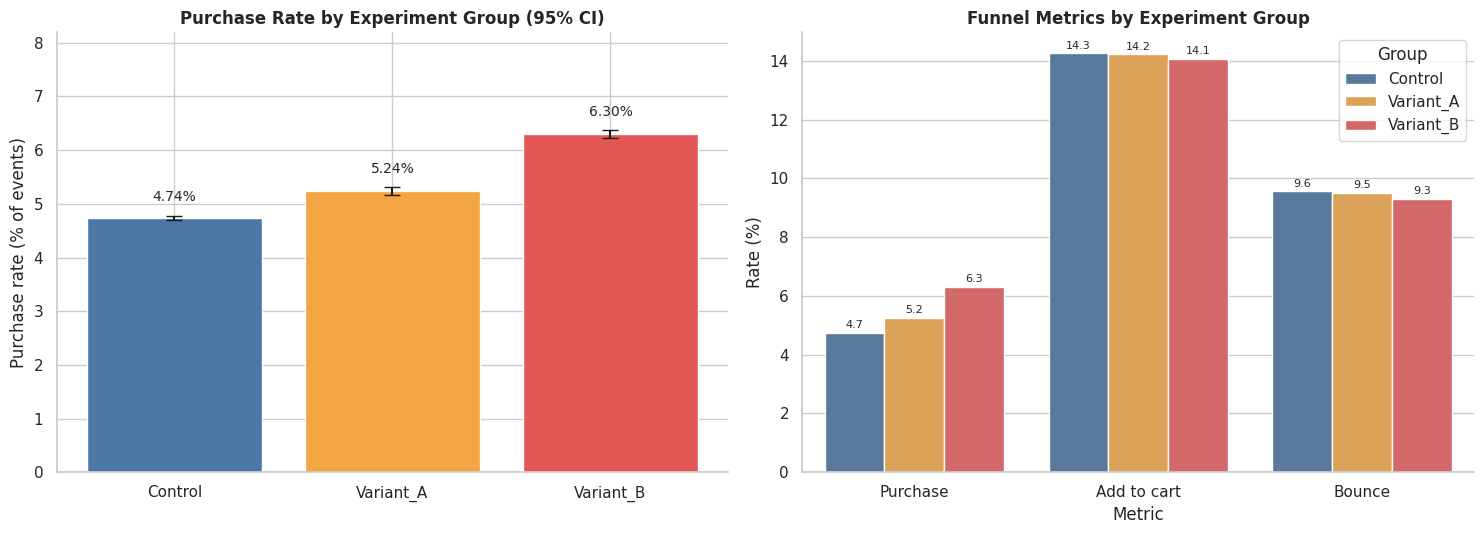

In [20]:
ab = run_sql("""
SELECT experiment_group,
       COUNT(*)                                AS events,
       SUM(is_purchase)                        AS purchases,
       SUM(event_type = 'add_to_cart')         AS carts,
       SUM(event_type = 'bounce')              AS bounces
FROM events
GROUP BY experiment_group
""").set_index("experiment_group").reindex(GROUP_ORDER)
ab["purchase_rate_%"] = ab["purchases"] / ab["events"] * 100
ab["cart_rate_%"] = ab["carts"] / ab["events"] * 100
ab["bounce_rate_%"] = ab["bounces"] / ab["events"] * 100
display(ab.reset_index())

# Confidence interval for each group's own rate
ab["ci_low"] = ab["purchase_rate_%"] - 1.96 * np.sqrt(ab["purchase_rate_%"] / 100 * (1 - ab["purchase_rate_%"] / 100) / ab["events"]) * 100
ab["ci_high"] = ab["purchase_rate_%"] + 1.96 * np.sqrt(ab["purchase_rate_%"] / 100 * (1 - ab["purchase_rate_%"] / 100) / ab["events"]) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
colors = ["#4C78A8", "#F2A541", "#E45756"]
bars = axes[0].bar(ab.index, ab["purchase_rate_%"], color=colors,
                   yerr=[ab["purchase_rate_%"] - ab["ci_low"], ab["ci_high"] - ab["purchase_rate_%"]], capsize=6)
axes[0].bar_label(bars, labels=[f"{v:.2f}%" for v in ab["purchase_rate_%"]], padding=8, fontsize=10)
axes[0].set_title("Purchase Rate by Experiment Group (95% CI)", fontweight="bold")
axes[0].set_ylabel("Purchase rate (% of events)"); axes[0].set_ylim(0, ab["purchase_rate_%"].max() * 1.3)
sns.despine(ax=axes[0])

metric_df = ab[["purchase_rate_%", "cart_rate_%", "bounce_rate_%"]].reset_index().melt(id_vars="experiment_group", var_name="Metric", value_name="Rate (%)")
metric_df["Metric"] = metric_df["Metric"].map({"purchase_rate_%": "Purchase", "cart_rate_%": "Add to cart", "bounce_rate_%": "Bounce"})
sns.barplot(data=metric_df, x="Metric", y="Rate (%)", hue="experiment_group", hue_order=GROUP_ORDER, palette=colors, ax=axes[1])
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.1f", padding=2, fontsize=8)
axes[1].set_title("Funnel Metrics by Experiment Group", fontweight="bold")
axes[1].legend(title="Group"); sns.despine(ax=axes[1])
plt.tight_layout(); plt.show()

,Comparison,Treatment rate (%),Baseline rate (%),Uplift (pp),95% CI low (pp),95% CI high (pp),Relative uplift (%),z,p_raw,q-value (BH),Significant (q < 0.05)
0,Variant_A vs Control,5.24,4.74,0.50,0.42,0.58,10.51,12.70,<0.001,<0.001,✅ Yes
1,Variant_B vs Control,6.30,4.74,1.56,1.48,1.64,32.87,38.71,<0.001,<0.001,✅ Yes
2,Variant_B vs Variant_A,6.30,5.24,1.06,0.96,1.16,20.24,20.37,<0.001,<0.001,✅ Yes


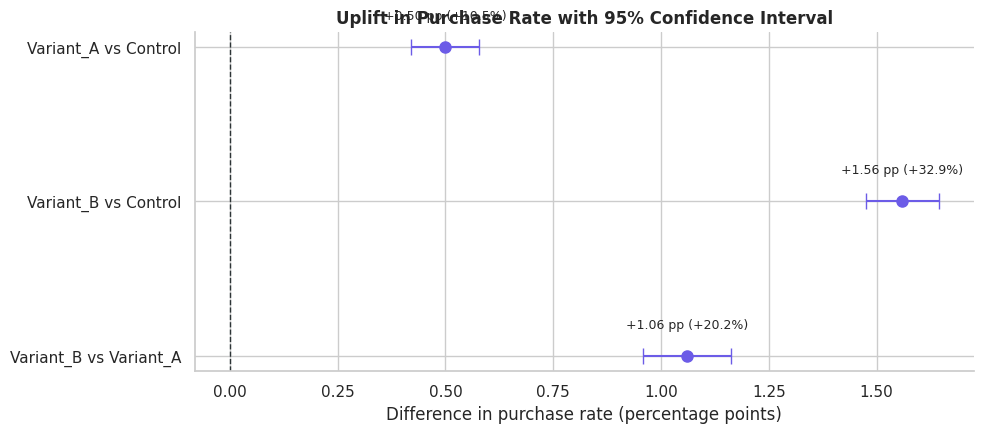

In [21]:
# Significance tests: each variant vs Control, plus Variant_B vs Variant_A
comparisons = [("Variant_A", "Control"), ("Variant_B", "Control"), ("Variant_B", "Variant_A")]
rows = []
for t_grp, c_grp in comparisons:
    r = two_prop_test(ab.loc[t_grp, "purchases"], ab.loc[t_grp, "events"], ab.loc[c_grp, "purchases"], ab.loc[c_grp, "events"])
    rows.append({"Comparison": f"{t_grp} vs {c_grp}", "Treatment rate (%)": r["rate_treat"] * 100, "Baseline rate (%)": r["rate_ctrl"] * 100,
                 "Uplift (pp)": r["diff"] * 100, "95% CI low (pp)": r["ci_low"] * 100, "95% CI high (pp)": r["ci_high"] * 100,
                 "Relative uplift (%)": r["rel_lift"] * 100, "z": r["z"], "p_raw": r["p_value"]})
ab_tests = pd.DataFrame(rows)
ab_tests["q-value (BH)"] = benjamini_hochberg(ab_tests["p_raw"])
ab_tests["Significant (q < 0.05)"] = np.where(ab_tests["q-value (BH)"] < 0.05, "✅ Yes", "No")
ab_show = ab_tests.copy()
ab_show["p_raw"] = ab_show["p_raw"].map(fmt_p); ab_show["q-value (BH)"] = ab_show["q-value (BH)"].map(fmt_p)
display(ab_show)

# Forest-style plot of uplift with confidence intervals
fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(ab_tests))[::-1]
ax.errorbar(ab_tests["Uplift (pp)"], y,
            xerr=[ab_tests["Uplift (pp)"] - ab_tests["95% CI low (pp)"], ab_tests["95% CI high (pp)"] - ab_tests["Uplift (pp)"]],
            fmt="o", color="#6C5CE7", ecolor="#6C5CE7", capsize=6, markersize=8)
ax.axvline(0, color="#2D3436", linestyle="--", linewidth=1)
ax.set_yticks(y); ax.set_yticklabels(ab_tests["Comparison"])
for yi, (u, rel) in zip(y, zip(ab_tests["Uplift (pp)"], ab_tests["Relative uplift (%)"])):
    ax.text(u, yi + 0.18, f"{u:+.2f} pp ({rel:+.1f}%)", ha="center", fontsize=9)
ax.set_xlabel("Difference in purchase rate (percentage points)")
ax.set_title("Uplift in Purchase Rate with 95% Confidence Interval", fontweight="bold")
sns.despine(); plt.tight_layout(); plt.show()

a_vs_c, b_vs_c, b_vs_a = ab_tests.iloc[0], ab_tests.iloc[1], ab_tests.iloc[2]
FINDINGS.update({"A_uplift_pp": a_vs_c["Uplift (pp)"], "A_rel": a_vs_c["Relative uplift (%)"],
                 "B_uplift_pp": b_vs_c["Uplift (pp)"], "B_rel": b_vs_c["Relative uplift (%)"],
                 "B_vs_A_pp": b_vs_a["Uplift (pp)"], "ctrl_rate": ab.loc["Control", "purchase_rate_%"],
                 "A_rate": ab.loc["Variant_A", "purchase_rate_%"], "B_rate": ab.loc["Variant_B", "purchase_rate_%"]})
beat = [r["Comparison"].split(" vs ")[0] for _, r in ab_tests.iloc[:2].iterrows() if r["q-value (BH)"] < 0.05 and r["Uplift (pp)"] > 0]
winner = "Variant_B" if b_vs_a["q-value (BH)"] < 0.05 and b_vs_a["Uplift (pp)"] > 0 else ("Variant_A" if a_vs_c["q-value (BH)"] < 0.05 else "Control")
FINDINGS["ab_winner"] = winner
show_banner(
    "A/B test result",
    f"<ul><li><strong>Variant_A</strong> converts at {a_vs_c['Treatment rate (%)']:.2f}% vs {a_vs_c['Baseline rate (%)']:.2f}% for Control: "
    f"<strong>{a_vs_c['Uplift (pp)']:+.2f} pp</strong> ({a_vs_c['Relative uplift (%)']:+.1f}% relative, q {html.escape(fmt_p(a_vs_c['q-value (BH)']))}).</li>"
    f"<li><strong>Variant_B</strong> converts at {b_vs_c['Treatment rate (%)']:.2f}%: <strong>{b_vs_c['Uplift (pp)']:+.2f} pp</strong> "
    f"({b_vs_c['Relative uplift (%)']:+.1f}% relative, q {html.escape(fmt_p(b_vs_c['q-value (BH)']))}).</li>"
    f"<li><strong>Variant_B vs Variant_A</strong>: {b_vs_a['Uplift (pp)']:+.2f} pp (q {html.escape(fmt_p(b_vs_a['q-value (BH)']))}).</li></ul>"
    + (f"{' and '.join(beat)} beat{'s' if len(beat) == 1 else ''} Control after adjustment for multiple comparisons, and the best-performing arm is <strong>{winner}</strong>. " if beat else
       "Neither variant beats Control after adjustment for multiple comparisons. ")
    +
    "Statistical significance is easy to reach with this many events, so the business question is whether a lift of this size justifies the cost of rolling the variant out.",
    color="green", icon="🏆"
)

### 8.4 Does the effect differ by segment?

An overall uplift can hide groups where the variant helps a lot, a little, or not at all. The same z-tests are repeated within each traffic source, loyalty tier and exposure group, and p-values are adjusted for the number of comparisons.

,Dimension,Segment,Variant,Control rate (%),Variant rate (%),Uplift (pp),Relative uplift (%),p_raw,Events (variant),q-value (BH),Significant (q < 0.05)
0,traffic_source,Direct,Variant_A,1.68,2.29,0.61,36.35,<0.001,39946,<0.001,✅ Yes
1,traffic_source,Direct,Variant_B,1.68,3.18,1.50,89.08,<0.001,40109,<0.001,✅ Yes
2,traffic_source,Email,Variant_A,8.46,9.01,0.54,6.42,<0.001,59809,<0.001,✅ Yes
3,traffic_source,Email,Variant_B,8.46,10.04,1.58,18.64,<0.001,60239,<0.001,✅ Yes
4,traffic_source,Organic,Variant_A,1.68,2.16,0.47,28.14,<0.001,160901,<0.001,✅ Yes
5,traffic_source,Organic,Variant_B,1.68,3.26,1.58,93.92,<0.001,160062,<0.001,✅ Yes
6,traffic_source,Paid Search,Variant_A,8.01,8.46,0.45,5.59,<0.001,80343,<0.001,✅ Yes
7,traffic_source,Paid Search,Variant_B,8.01,9.56,1.54,19.24,<0.001,79717,<0.001,✅ Yes
8,traffic_source,Social,Variant_A,6.88,7.41,0.53,7.76,<0.001,60414,<0.001,✅ Yes
9,traffic_source,Social,Variant_B,6.88,8.43,1.56,22.67,<0.001,60056,<0.001,✅ Yes


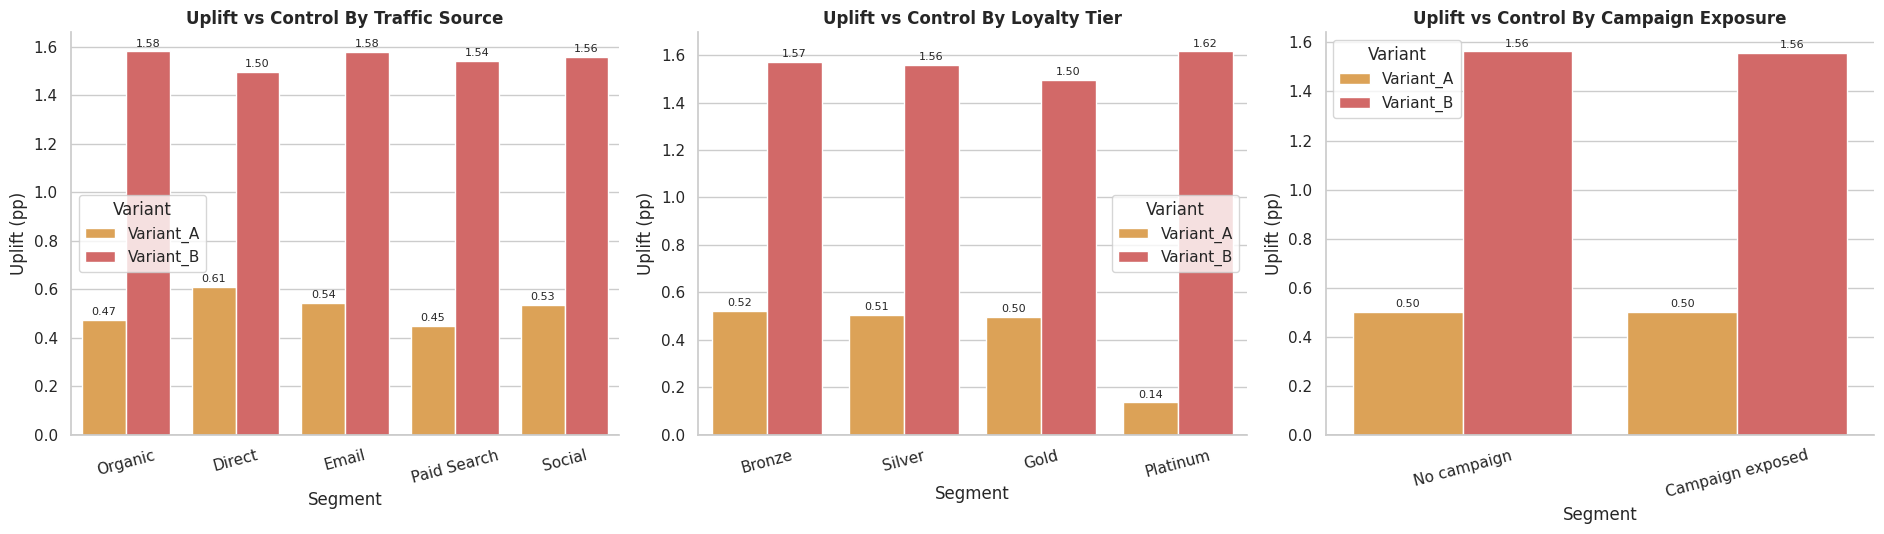

In [22]:
seg_events = ev.merge(cust[["customer_id", "loyalty_tier"]], on="customer_id")
seg_events["exposure"] = np.where(seg_events["has_campaign"] == 1, "Campaign exposed", "No campaign")

seg_rows = []
for dim in ["traffic_source", "loyalty_tier", "exposure"]:
    agg = seg_events.groupby([dim, "experiment_group"])["is_purchase"].agg(["sum", "count"]).reset_index()
    for seg in agg[dim].unique():
        sub = agg[agg[dim] == seg].set_index("experiment_group")
        ctrl = sub.loc["Control"]
        for v in ["Variant_A", "Variant_B"]:
            r = two_prop_test(sub.loc[v, "sum"], sub.loc[v, "count"], ctrl["sum"], ctrl["count"])
            seg_rows.append({"Dimension": dim, "Segment": seg, "Variant": v, "Control rate (%)": r["rate_ctrl"] * 100,
                             "Variant rate (%)": r["rate_treat"] * 100, "Uplift (pp)": r["diff"] * 100,
                             "Relative uplift (%)": r["rel_lift"] * 100, "p_raw": r["p_value"], "Events (variant)": int(sub.loc[v, "count"])})
seg_tests = pd.DataFrame(seg_rows)
seg_tests["q-value (BH)"] = benjamini_hochberg(seg_tests["p_raw"])
seg_tests["Significant (q < 0.05)"] = np.where(seg_tests["q-value (BH)"] < 0.05, "✅ Yes", "No")
seg_show = seg_tests.copy()
seg_show["p_raw"] = seg_show["p_raw"].map(fmt_p); seg_show["q-value (BH)"] = seg_show["q-value (BH)"].map(fmt_p)
display(seg_show)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, dim, order, title in zip(axes, ["traffic_source", "loyalty_tier", "exposure"],
                                 [SOURCE_ORDER, TIER_ORDER, ["No campaign", "Campaign exposed"]],
                                 ["By Traffic Source", "By Loyalty Tier", "By Campaign Exposure"]):
    d = seg_tests[seg_tests["Dimension"] == dim]
    sns.barplot(data=d, x="Segment", y="Uplift (pp)", hue="Variant", order=order, palette=["#F2A541", "#E45756"], ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", padding=2, fontsize=8)
    ax.axhline(0, color="#2D3436", linewidth=1)
    ax.set_title(f"Uplift vs Control {title}", fontweight="bold"); ax.set_ylabel("Uplift (pp)"); ax.tick_params(axis="x", rotation=15)
    sns.despine(ax=ax)
plt.tight_layout(); plt.show()

sig_share = (seg_tests["q-value (BH)"] < 0.05).mean() * 100
segB = seg_tests[seg_tests["Variant"] == "Variant_B"]
segA = seg_tests[seg_tests["Variant"] == "Variant_A"]
max_rel_row = segB.loc[segB["Relative uplift (%)"].idxmax()]
min_rel_row = segB.loc[segB["Relative uplift (%)"].idxmin()]
not_sig = seg_tests[seg_tests["q-value (BH)"] >= 0.05]
not_sig_txt = ("; ".join(f"{r['Variant']} in {r['Segment']} ({r['Uplift (pp)']:+.2f} pp, q {fmt_p(r['q-value (BH)'])})" for _, r in not_sig.iterrows())
               if len(not_sig) else "none")
FINDINGS.update({"segB_all_sig": bool((segB["q-value (BH)"] < 0.05).all()), "seg_sig_share": sig_share, "segB_abs_min": segB["Uplift (pp)"].min(), "segB_abs_max": segB["Uplift (pp)"].max(),
                 "segB_rel_max_seg": max_rel_row["Segment"], "segB_rel_max": max_rel_row["Relative uplift (%)"],
                 "segB_rel_min_seg": min_rel_row["Segment"], "segB_rel_min": min_rel_row["Relative uplift (%)"]})
show_banner(
    "Segment-level effects",
    f"{sig_share:.0f}% of the {len(seg_tests)} segment-level comparisons are significant after adjustment. "
    f"<strong>Variant_B</strong> adds between <strong>{segB['Uplift (pp)'].min():+.2f}</strong> and <strong>{segB['Uplift (pp)'].max():+.2f} pp</strong> in every segment, "
    f"whereas its <em>relative</em> uplift ranges from {min_rel_row['Relative uplift (%)']:.0f}% ({html.escape(str(min_rel_row['Segment']))}, control rate {min_rel_row['Control rate (%)']:.2f}%) "
    f"to {max_rel_row['Relative uplift (%)']:.0f}% ({html.escape(str(max_rel_row['Segment']))}, control rate {max_rel_row['Control rate (%)']:.2f}%). "
    "When the absolute gain is nearly constant, the relative gain is largest wherever the baseline conversion is lowest. "
    f"Variant_A's absolute uplift ranges from {segA['Uplift (pp)'].min():+.2f} to {segA['Uplift (pp)'].max():+.2f} pp. "
    f"Comparisons <strong>not</strong> significant after adjustment: {html.escape(not_sig_txt)}. "
    "Small segments (for example Platinum) have wide intervals, so treat their numbers as indicative only.",
    color="purple", icon="🔬"
)

### 8.5 Adjusted estimate (logistic regression with cluster-robust errors)

The raw comparison could be distorted if the groups differed on other factors, and events from the same customer are not independent. A **logistic regression** estimates the variant effect while holding traffic source, loyalty tier, device, weekend and holiday season constant, with standard errors **clustered by customer**. Campaign exposure is *not* added as a separate covariate because it is fully determined by traffic source (Section 7.2), which would make the model unstable.

**How to read odds ratios:** an odds ratio (OR) above 1 means higher odds of purchase relative to the reference group; below 1 means lower. An OR of 1.00 means no association. The confidence interval shows the plausible range.

,Odds ratio,CI low,CI high,p-value
experiment_group_Variant_A,1.12,1.10,1.13,<0.001
experiment_group_Variant_B,1.36,1.34,1.38,<0.001
traffic_source_Direct,1.00,0.97,1.04,0.793
traffic_source_Email,4.59,4.50,4.68,<0.001
traffic_source_Paid Search,4.32,4.24,4.40,<0.001
traffic_source_Social,3.69,3.62,3.77,<0.001
loyalty_tier_Gold,1.52,1.50,1.55,<0.001
loyalty_tier_Platinum,1.48,1.43,1.53,<0.001
loyalty_tier_Silver,1.25,1.23,1.27,<0.001
device_type_Unknown,1.00,0.96,1.05,0.985


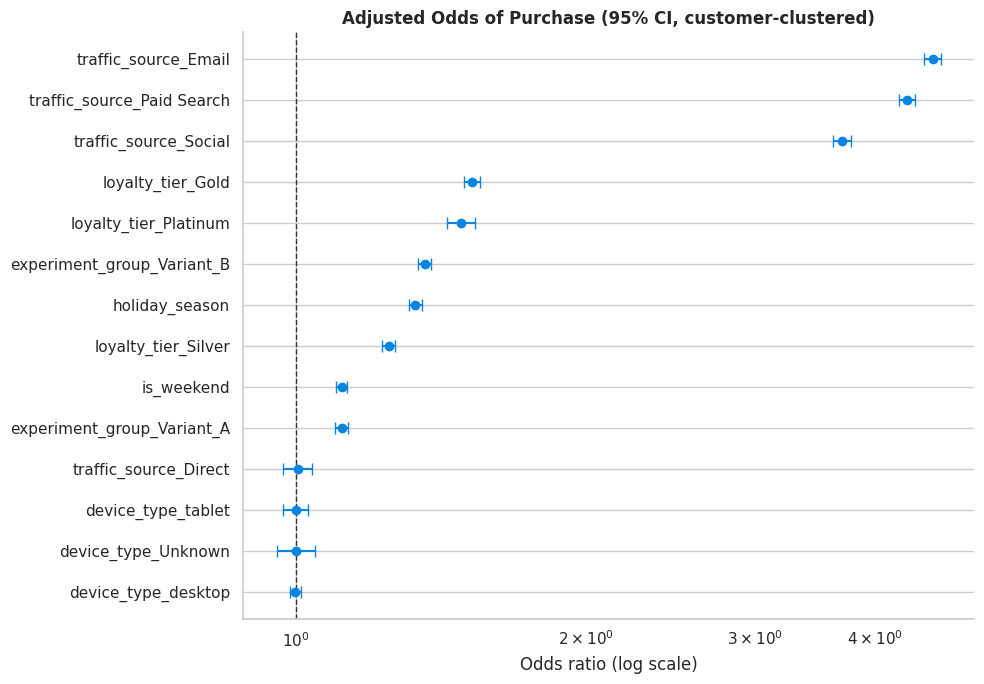

In [23]:
# Build the design matrix: group dummies (reference = Control) + covariates
model_df = ev.merge(cust[["customer_id", "loyalty_tier"]], on="customer_id")
X = pd.get_dummies(
    model_df[["experiment_group", "traffic_source", "loyalty_tier", "device_type"]],
    drop_first=False, dtype=float
).drop(columns=["experiment_group_Control", "traffic_source_Organic", "loyalty_tier_Bronze", "device_type_mobile"])
X["is_weekend"] = model_df["is_weekend"].astype(float)
X["holiday_season"] = model_df["holiday_season"].astype(float)
X = sm.add_constant(X)
y = model_df["is_purchase"].astype(float)

logit_fit = sm.Logit(y, X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": model_df["customer_id"].values})

ci = logit_fit.conf_int()
or_table = pd.DataFrame({
    "Odds ratio": np.exp(logit_fit.params),
    "CI low": np.exp(ci[0]),
    "CI high": np.exp(ci[1]),
    "p-value": logit_fit.pvalues,
}).drop(index="const")
or_show = or_table.copy(); or_show["p-value"] = or_show["p-value"].map(fmt_p)
display(or_show)

plot_or = or_table.sort_values("Odds ratio")
fig, ax = plt.subplots(figsize=(10, 7))
yy = np.arange(len(plot_or))
ax.errorbar(plot_or["Odds ratio"], yy, xerr=[plot_or["Odds ratio"] - plot_or["CI low"], plot_or["CI high"] - plot_or["Odds ratio"]],
            fmt="o", color="#0984E3", ecolor="#0984E3", capsize=4)
ax.axvline(1, color="#2D3436", linestyle="--", linewidth=1)
ax.set_yticks(yy); ax.set_yticklabels(plot_or.index)
ax.set_xscale("log"); ax.set_xlabel("Odds ratio (log scale)")
ax.set_title("Adjusted Odds of Purchase (95% CI, customer-clustered)", fontweight="bold")
sns.despine(); plt.tight_layout(); plt.show()

del X, y, model_df
gc.collect()
orA, orB = or_table.loc["experiment_group_Variant_A"], or_table.loc["experiment_group_Variant_B"]
raw_or = lambda p, q: (p / (1 - p)) / (q / (1 - q))
rawA = raw_or(ab.loc["Variant_A", "purchase_rate_%"] / 100, ab.loc["Control", "purchase_rate_%"] / 100)
rawB = raw_or(ab.loc["Variant_B", "purchase_rate_%"] / 100, ab.loc["Control", "purchase_rate_%"] / 100)
FINDINGS.update({"or_A": orA["Odds ratio"], "or_B": orB["Odds ratio"]})
excl_A, excl_B = not (orA["CI low"] <= 1 <= orA["CI high"]), not (orB["CI low"] <= 1 <= orB["CI high"])
top_cov = or_table.drop(index=["experiment_group_Variant_A", "experiment_group_Variant_B"]).sort_values("Odds ratio", ascending=False).iloc[0]
if excl_A and excl_B:
    verdict = "Both variant effects remain distinguishable from 1 after adjustment and customer clustering, so the A/B conclusion does not depend on treating events as independent."
elif excl_B:
    verdict = "Only Variant_B remains distinguishable from 1 after customer clustering; the evidence for Variant_A is weaker than the raw test suggested."
else:
    verdict = "Neither variant is clearly distinguishable from 1 once customer clustering is accounted for, so the raw A/B result should be treated with caution."
show_banner(
    "Adjusted A/B result",
    f"After adjusting for traffic source, loyalty tier, device, weekend and season, the odds of purchase are <strong>{orA['Odds ratio']:.2f}x</strong> for Variant_A "
    f"(95% CI {orA['CI low']:.2f}–{orA['CI high']:.2f}; unadjusted {rawA:.2f}x) and <strong>{orB['Odds ratio']:.2f}x</strong> for Variant_B "
    f"({orB['CI low']:.2f}–{orB['CI high']:.2f}; unadjusted {rawB:.2f}x) compared with Control. {verdict} "
    f"The strongest covariate is <strong>{html.escape(str(top_cov.name))}</strong> (OR {top_cov['Odds ratio']:.2f}). "
    "Odds ratios describe odds, not probabilities; use the percentage-point uplifts above when communicating to business readers.",
    color="blue", icon="💡"
)

,experiment_group,events,orders,rev_missing_%,AOV ($),refund_rate_value_%,net_revenue,net_revenue_per_1000_events ($)
0,Control,1198404,56855,10.03,96.37,2.83,"4,789,887.91","3,996.89"
1,Variant_A,401413,21045,9.86,95.41,2.83,"1,758,603.78","4,381.03"
2,Variant_B,400183,25227,10.59,95.19,3.04,"2,081,777.62","5,202.06"


,Comparison,"Revenue per 1,000 events: diff ($)",95% CI low ($),95% CI high ($),Relative (%),z,p_raw,q-value (BH)
0,Variant_A vs Control,384.14,283.11,485.18,9.61,7.45,<0.001,<0.001
1,Variant_B vs Control,"1,205.17","1,097.36","1,312.99",30.15,21.91,<0.001,<0.001


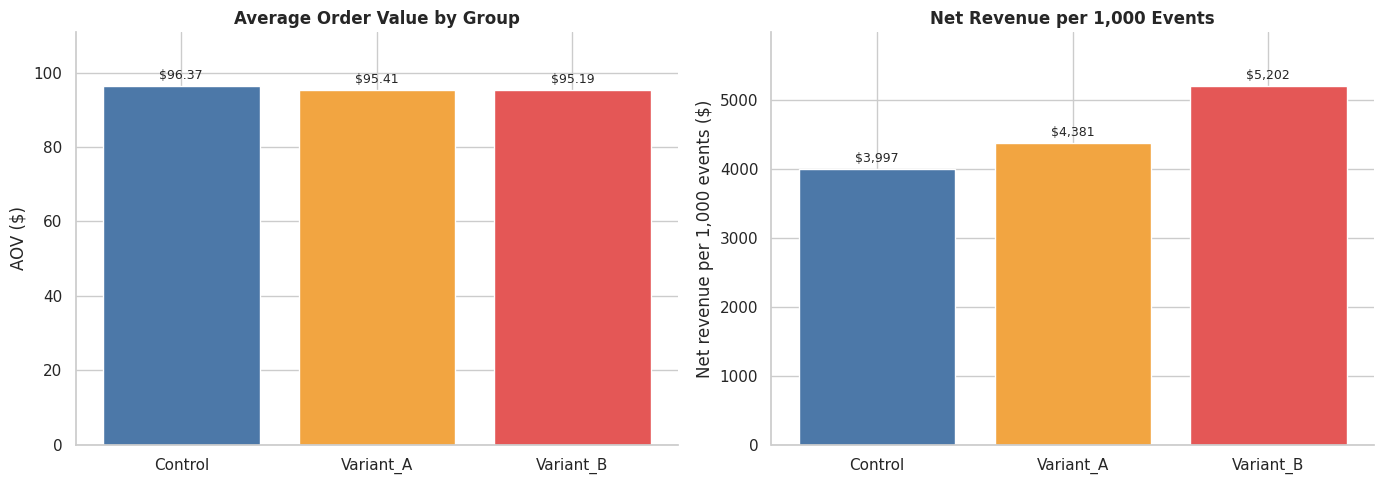

In [24]:
# From conversion to money: revenue per 1,000 events by experiment group
# Purchase events link 1-to-1 to transactions on (customer_id, timestamp).
rev_by_group = run_sql("""
SELECT e.experiment_group,
       COUNT(*)                                  AS events,
       SUM(e.is_purchase)                        AS orders,
       SUM(v.has_revenue)                        AS orders_with_revenue,
       SUM(v.order_value)                        AS gross_sales,
       SUM(v.refunded_value)                     AS refunded_value,
       SUM(v.net_revenue)                        AS net_revenue,
       SUM(v.net_revenue * v.net_revenue)        AS net_revenue_sq
FROM events e
LEFT JOIN v_transactions v
       ON e.is_purchase = 1 AND v.customer_id = e.customer_id AND v.timestamp = e.timestamp
GROUP BY e.experiment_group
""").set_index("experiment_group").reindex(GROUP_ORDER)

rev_by_group["AOV ($)"] = rev_by_group["gross_sales"] / rev_by_group["orders_with_revenue"]
rev_by_group["rev_missing_%"] = (1 - rev_by_group["orders_with_revenue"] / rev_by_group["orders"]) * 100
rev_by_group["refund_rate_value_%"] = rev_by_group["refunded_value"] / rev_by_group["gross_sales"] * 100
rev_by_group["net_revenue_per_1000_events ($)"] = rev_by_group["net_revenue"] / rev_by_group["events"] * 1000

# Welch-type z-test on per-event net revenue (non-purchase events count as 0 revenue)
n = rev_by_group["events"]; mean = rev_by_group["net_revenue"] / n
var = rev_by_group["net_revenue_sq"] / n - mean ** 2
se = np.sqrt(var / n)
rev_rows = []
for v in ["Variant_A", "Variant_B"]:
    d = mean[v] - mean["Control"]; s = np.sqrt(se[v] ** 2 + se["Control"] ** 2); z = d / s
    rev_rows.append({"Comparison": f"{v} vs Control", "Revenue per 1,000 events: diff ($)": d * 1000,
                     "95% CI low ($)": (d - 1.96 * s) * 1000, "95% CI high ($)": (d + 1.96 * s) * 1000,
                     "Relative (%)": d / mean["Control"] * 100, "z": z, "p_raw": 2 * (1 - norm.cdf(abs(z)))})
rev_tests = pd.DataFrame(rev_rows)
rev_tests["q-value (BH)"] = benjamini_hochberg(rev_tests["p_raw"])

display(rev_by_group[["events", "orders", "rev_missing_%", "AOV ($)", "refund_rate_value_%", "net_revenue", "net_revenue_per_1000_events ($)"]].reset_index())
rt = rev_tests.copy(); rt["p_raw"] = rt["p_raw"].map(fmt_p); rt["q-value (BH)"] = rt["q-value (BH)"].map(fmt_p)
display(rt)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bar_panel(axes[0], rev_by_group.index, rev_by_group["AOV ($)"], "Average Order Value by Group", ylabel="AOV ($)", fmt="${:,.2f}", colors=["#4C78A8", "#F2A541", "#E45756"])
bar_panel(axes[1], rev_by_group.index, rev_by_group["net_revenue_per_1000_events ($)"], "Net Revenue per 1,000 Events",
          ylabel="Net revenue per 1,000 events ($)", fmt="${:,.0f}", colors=["#4C78A8", "#F2A541", "#E45756"])
plt.tight_layout(); plt.show()

aov_spread = (rev_by_group["AOV ($)"].max() - rev_by_group["AOV ($)"].min()) / rev_by_group["AOV ($)"].mean() * 100
FINDINGS.update({"B_rev_rel": rev_tests.iloc[1]["Relative (%)"], "A_rev_rel": rev_tests.iloc[0]["Relative (%)"],
                 "B_rev_per_1000": rev_by_group.loc["Variant_B", "net_revenue_per_1000_events ($)"],
                 "ctrl_rev_per_1000": rev_by_group.loc["Control", "net_revenue_per_1000_events ($)"]})
show_banner(
    "Does higher conversion mean more revenue?",
    f"Average order value differs by only {aov_spread:.1f}% across groups, so the variants raise revenue mainly by <strong>converting more events</strong>, not by selling bigger baskets. "
    f"Net revenue per 1,000 events is <strong>${rev_by_group.loc['Variant_B','net_revenue_per_1000_events ($)']:,.0f}</strong> for Variant_B vs "
    f"<strong>${rev_by_group.loc['Control','net_revenue_per_1000_events ($)']:,.0f}</strong> for Control ({rev_tests.iloc[1]['Relative (%)']:+.1f}%). "
    f"Revenue is missing for {rev_by_group['rev_missing_%'].min():.1f}%–{rev_by_group['rev_missing_%'].max():.1f}% of orders across the groups, so absolute revenue is understated; "
    "the similar missing rates mean the groups remain comparable.",
    color="green", icon="💰"
)

## 9. Statistical tests: which factors are associated with purchase?

So far each factor was examined on its own. This section tests **all of them in one place**, using the same logic for every variable:

- **Categorical factors:** chi-square test of independence with purchase (yes/no) at event level, plus **Cramér's V** as an effect size.
- **Numeric factor (`session_duration_sec`):** Mann–Whitney U test between purchase and non-purchase events, with the probability-of-superiority as effect size.
- **Multiple testing:** Benjamini–Hochberg false-discovery-rate adjustment across all tests.

**How to understand the results:** with two million events, even trivial differences produce tiny p-values. The adjusted q-value tells us whether an association is *detectable*; **Cramér's V tells us whether it is *large***. Rule of thumb used here: V below 0.03 is negligible, 0.03–0.10 very small, 0.10–0.30 small to moderate, above 0.30 strong. (V is conservative when the outcome is rare, as purchases are here, so also read the relative lifts.)

**Important:** these tests show association, not cause. Several factors overlap (for example traffic source and campaign exposure), so a large V for one does not mean it works independently of the others.

,Factor,Test,Statistic,df,p_raw,Effect size,Effect measure,q-value (BH),Detectable (q < 0.05),Practical size
0,Traffic source,Chi-square,"39,177.51",4.00,<0.001,0.1400,Cramér's V,<0.001,✅ Yes,Small to moderate
1,Campaign exposure,Chi-square,"38,346.94",1.00,<0.001,0.1385,Cramér's V,<0.001,✅ Yes,Small to moderate
2,Loyalty tier,Chi-square,"2,495.72",3.00,<0.001,0.0353,Cramér's V,<0.001,✅ Yes,Very small
3,Experiment group,Chi-square,"1,499.85",2.00,<0.001,0.0274,Cramér's V,<0.001,✅ Yes,Negligible
4,Season (Nov-Dec),Chi-square,"1,238.97",1.00,<0.001,0.0249,Cramér's V,<0.001,✅ Yes,Negligible
5,Day type (weekend),Chi-square,221.12,1.00,<0.001,0.0105,Cramér's V,<0.001,✅ Yes,Negligible
6,Hour of day,Chi-square,19.69,23.00,0.661,0.0031,Cramér's V,0.712,No,Negligible
7,Session duration (sec),Mann-Whitney U,"97,626,012,244.50",NaN,0.310,0.0019,Rank-biserial |r|,0.510,No,Negligible
8,Country,Chi-square,5.56,6.00,0.474,0.0017,Cramér's V,0.604,No,Negligible
9,Age group,Chi-square,4.95,4.00,0.292,0.0016,Cramér's V,0.510,No,Negligible


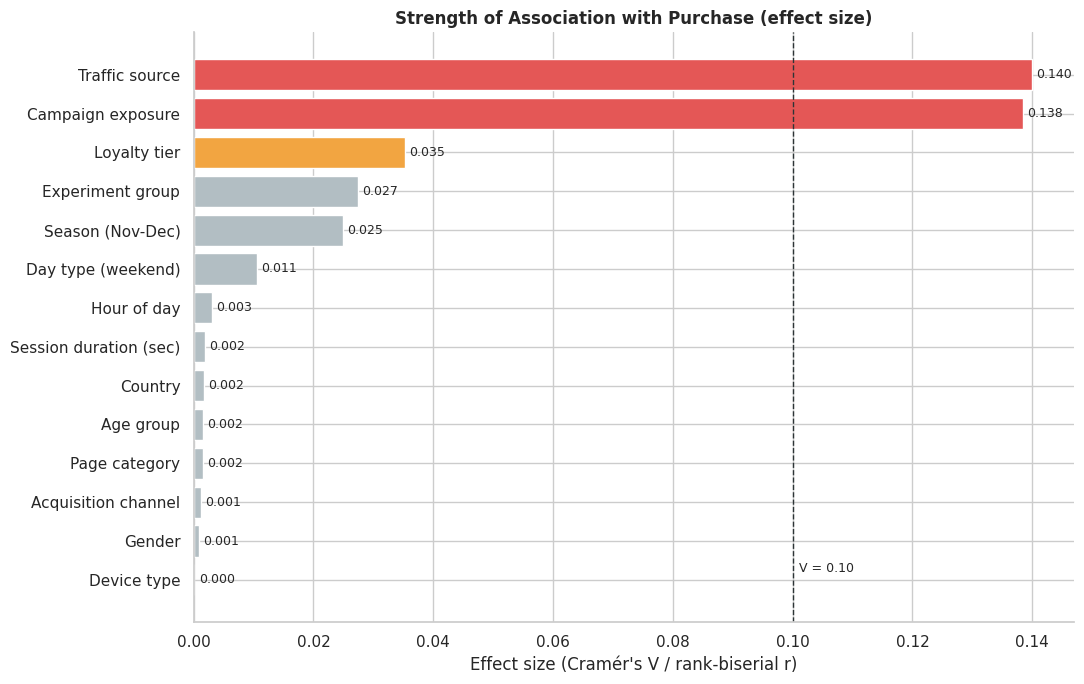

In [25]:
test_df = ev.merge(cust[["customer_id", "loyalty_tier", "country", "gender", "acquisition_channel", "age_group"]], on="customer_id")
test_df["exposure"] = np.where(test_df["has_campaign"] == 1, "Exposed", "Not exposed")
test_df["season"] = np.where(test_df["holiday_season"] == 1, "Nov-Dec", "Other months")
test_df["day_type"] = np.where(test_df["is_weekend"] == 1, "Weekend", "Weekday")

factors = {
    "Traffic source": "traffic_source", "Campaign exposure": "exposure", "Experiment group": "experiment_group",
    "Loyalty tier": "loyalty_tier", "Season (Nov-Dec)": "season", "Day type (weekend)": "day_type",
    "Device type": "device_type", "Page category": "page_category", "Country": "country", "Gender": "gender",
    "Acquisition channel": "acquisition_channel", "Age group": "age_group", "Hour of day": "event_hour",
}
test_rows = []
for label, col in factors.items():
    chi2, p, dof, v = cramers_v(pd.crosstab(test_df[col], test_df["is_purchase"]))
    test_rows.append({"Factor": label, "Test": "Chi-square", "Statistic": chi2, "df": dof, "p_raw": p, "Effect size": v, "Effect measure": "Cramér's V"})

# Numeric factor: session duration
dur_buy = test_df.loc[test_df["is_purchase"] == 1, "session_duration_sec"]
dur_no = test_df.loc[test_df["is_purchase"] == 0, "session_duration_sec"]
u_stat, u_p = mannwhitneyu(dur_buy, dur_no, alternative="two-sided")
prob_sup = u_stat / (len(dur_buy) * len(dur_no))
test_rows.append({"Factor": "Session duration (sec)", "Test": "Mann-Whitney U", "Statistic": u_stat, "df": np.nan, "p_raw": u_p,
                  "Effect size": abs(prob_sup - 0.5) * 2, "Effect measure": "Rank-biserial |r|"})

factor_tests = pd.DataFrame(test_rows)
factor_tests["q-value (BH)"] = benjamini_hochberg(factor_tests["p_raw"])
factor_tests["Detectable (q < 0.05)"] = np.where(factor_tests["q-value (BH)"] < 0.05, "✅ Yes", "No")
factor_tests["Practical size"] = pd.cut(factor_tests["Effect size"], [-1, 0.03, 0.10, 0.30, 1.01],
                                        labels=["Negligible", "Very small", "Small to moderate", "Strong"]).astype(str)
factor_tests = factor_tests.sort_values("Effect size", ascending=False).reset_index(drop=True)
ft_show = factor_tests.copy()
ft_show["p_raw"] = ft_show["p_raw"].map(fmt_p); ft_show["q-value (BH)"] = ft_show["q-value (BH)"].map(fmt_p)
ft_show["Effect size"] = ft_show["Effect size"].map(lambda x: f"{x:.4f}")
display(ft_show)

fig, ax = plt.subplots(figsize=(11, 7))
plot_ft = factor_tests.sort_values("Effect size")
cols = ["#E45756" if s >= 0.10 else ("#F2A541" if s >= 0.03 else "#B2BEC3") for s in plot_ft["Effect size"]]
bars = ax.barh(plot_ft["Factor"], plot_ft["Effect size"], color=cols)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in plot_ft["Effect size"]], padding=3, fontsize=9)
ax.axvline(0.10, color="#2D3436", linestyle="--", linewidth=1)
ax.text(0.101, 0.2, "V = 0.10", fontsize=9)
ax.set_title("Strength of Association with Purchase (effect size)", fontweight="bold")
ax.set_xlabel("Effect size (Cramér's V / rank-biserial r)")
sns.despine(); plt.tight_layout(); plt.show()

n_detect = int((factor_tests["q-value (BH)"] < 0.05).sum()); n_strong = int((factor_tests["Effect size"] >= 0.10).sum())
negligible_but_sig = factor_tests[(factor_tests["q-value (BH)"] < 0.05) & (factor_tests["Effect size"] < 0.03)]["Factor"].tolist()
not_detect = factor_tests[factor_tests["q-value (BH)"] >= 0.05]["Factor"].tolist()
FINDINGS.update({"top_factor": factor_tests.iloc[0]["Factor"], "top_factor_v": factor_tests.iloc[0]["Effect size"], "n_factors": len(factor_tests),
                 "n_detect": n_detect, "n_strong": n_strong, "not_detect": not_detect})

show_banner(
    "Statistical significance vs practical importance",
    f"{n_detect} of {len(factor_tests)} factors are statistically detectable after adjustment, but only <strong>{n_strong}</strong> have an effect size of 0.10 or more. "
    f"The strongest association is <strong>{html.escape(str(factor_tests.iloc[0]['Factor']))}</strong> (effect size {factor_tests.iloc[0]['Effect size']:.3f}). "
    + (f"Factors with no detectable association: <strong>{html.escape(', '.join(not_detect))}</strong>. " if not_detect else "")
    + (f"Detectable but negligible: <strong>{html.escape(', '.join(negligible_but_sig))}</strong>. " if negligible_but_sig else "")
    + ("Note: Cramér's V is naturally small when the outcome is rare (about 5% of events are purchases), so a small V does not mean a small business effect. "
       f"For example, Variant_B's relative lift of {FINDINGS['B_rel']:.0f}% is commercially meaningful even though 'Experiment group' ranks low here. " if "Experiment group" in negligible_but_sig else "")
    + "Use effect sizes together with the relative lifts above, not the p-value alone, to decide where to focus.",
    color="yellow", icon="⚖️"
)

## 10. Revenue and transaction analysis

All revenue figures use the rebuilt measures from Section 4.1:

- **Gross sales** = value of orders at the time of sale.
- **Refunded value** = value of orders flagged as refunded.
- **Net revenue** = gross sales − refunded value.
- **AOV (average order value)** = gross sales ÷ orders with a revenue value.

About 10% of transactions have no revenue (and no product), so totals describe the transactions that do have values. Missing revenue is **not imputed**.

In [26]:
rev_summary = run_sql("""
SELECT COUNT(*)                                          AS orders,
       SUM(has_revenue)                                  AS orders_with_revenue,
       SUM(quantity)                                     AS units,
       ROUND(SUM(order_value), 2)                        AS gross_sales,
       ROUND(SUM(refunded_value), 2)                     AS refunded_value,
       ROUND(SUM(net_revenue), 2)                        AS net_revenue,
       ROUND(AVG(order_value), 2)                        AS aov,
       ROUND(100.0 * SUM(refunded_value) / SUM(order_value), 2) AS refund_rate_value_pct,
       ROUND(100.0 * AVG(refund_flag), 2)                AS refund_rate_orders_pct,
       ROUND(SUM(discount_value), 2)                     AS discount_cost,
       COUNT(DISTINCT customer_id)                       AS buyers
FROM v_transactions
""")
display(rev_summary)
rs = rev_summary.iloc[0]

list_value = run_sql("SELECT SUM(base_price * quantity) AS v FROM v_transactions WHERE has_revenue = 1").iloc[0, 0]
discount_share = rs["discount_cost"] / list_value * 100

FINDINGS.update({"net_revenue": rs["net_revenue"], "gross_sales": rs["gross_sales"], "aov": rs["aov"], "orders": rs["orders"],
                 "refund_rate_value": rs["refund_rate_value_pct"], "refund_rate_orders": rs["refund_rate_orders_pct"],
                 "discount_cost": rs["discount_cost"], "discount_share": discount_share, "buyers": rs["buyers"]})

show_cards([
    {"title": "Net revenue", "body": f"<strong>{money(rs['net_revenue'])}</strong><br>gross sales {money(rs['gross_sales'])}", "color": "green", "icon": "💰"},
    {"title": "Orders & buyers", "body": f"<strong>{int(rs['orders']):,}</strong> orders<br><strong>{int(rs['buyers']):,}</strong> buyers", "color": "blue", "icon": "🧾"},
    {"title": "Average order value", "body": f"<strong>{money(rs['aov'], 2)}</strong><br>{rs['units']/rs['orders']:.2f} units per order", "color": "purple", "icon": "🛍️"},
    {"title": "Refunds", "body": f"<strong>{rs['refund_rate_orders_pct']:.2f}%</strong> of orders<br>{rs['refund_rate_value_pct']:.2f}% of sales value ({money(rs['refunded_value'])})", "color": "red", "icon": "↩️"},
    {"title": "Discounts given", "body": f"<strong>{money(rs['discount_cost'])}</strong><br>{discount_share:.1f}% of list value", "color": "orange", "icon": "🏷️"},
    {"title": "Revenue coverage", "body": f"<strong>{rs['orders_with_revenue']/rs['orders']*100:.1f}%</strong> of orders have a revenue value", "color": "yellow", "icon": "🧹"},
], columns=3)

,orders,orders_with_revenue,units,gross_sales,refunded_value,net_revenue,aov,refund_rate_value_pct,refund_rate_orders_pct,discount_cost,buyers
0,103127,92678,142474,"8,886,572.26","256,302.95","8,630,269.31",95.89,2.88,2.94,"385,249.94",64035


,discount_pct,orders,share_of_orders_pct,avg_units,aov,refund_rate_pct,net_revenue,discount_cost
0,0.00,61923,60.00,1.38,99.58,2.91,"5,387,266.00",0.00
1,5.00,15473,15.00,1.39,95.78,2.89,"1,298,458.00","70,139.00"
2,10.00,12370,12.00,1.39,90.74,3.13,"976,055.00","111,948.00"
3,15.00,8311,8.10,1.39,86.00,3.04,"621,919.00","113,510.00"
4,20.00,5050,4.90,1.37,79.71,2.75,"346,572.00","89,654.00"


,Question,Statistic,p_raw,q-value (BH)
0,Do discounted orders contain more units? (Spearman),0.00,0.197,0.394
1,Is refund rate related to discount level? (chi-square),2.79,0.593,0.593


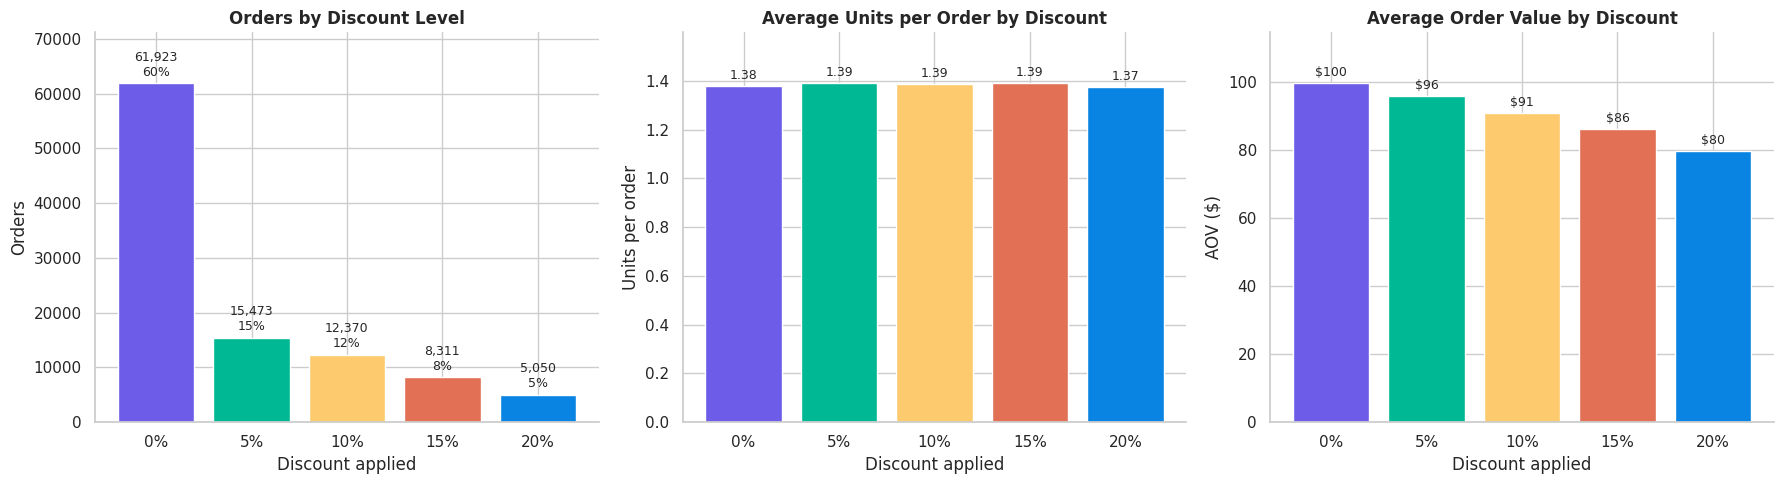

In [27]:
# Revenue by discount level
disc = run_sql("""
SELECT ROUND(discount_applied * 100) AS discount_pct,
       COUNT(*)                                       AS orders,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS share_of_orders_pct,
       ROUND(AVG(quantity), 3)                        AS avg_units,
       ROUND(AVG(order_value), 2)                     AS aov,
       ROUND(100.0 * AVG(refund_flag), 2)             AS refund_rate_pct,
       ROUND(SUM(net_revenue), 0)                     AS net_revenue,
       ROUND(SUM(discount_value), 0)                  AS discount_cost
FROM v_transactions
GROUP BY discount_applied
ORDER BY discount_applied
""")
display(disc)

# Do discounts change basket size or refunds? (units, refunds)
tx_stats = tx.copy()
rho, rho_p = stats.spearmanr(tx_stats["discount_applied"], tx_stats["quantity"])
chi_r, p_r, dof_r, v_r = cramers_v(pd.crosstab(tx_stats["discount_applied"], tx_stats["refund_flag"]))
disc_tests = pd.DataFrame([
    {"Question": "Do discounted orders contain more units? (Spearman)", "Statistic": rho, "p_raw": rho_p},
    {"Question": "Is refund rate related to discount level? (chi-square)", "Statistic": chi_r, "p_raw": p_r},
])
disc_tests["q-value (BH)"] = benjamini_hochberg(disc_tests["p_raw"])
dt = disc_tests.copy(); dt["p_raw"] = dt["p_raw"].map(fmt_p); dt["q-value (BH)"] = dt["q-value (BH)"].map(fmt_p)
display(dt)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
lab = [f"{int(d)}%" for d in disc["discount_pct"]]
bar_panel(axes[0], lab, disc["orders"], "Orders by Discount Level", xlabel="Discount applied", ylabel="Orders", extra=[f"{p:.0f}%" for p in disc["share_of_orders_pct"]])
bar_panel(axes[1], lab, disc["avg_units"], "Average Units per Order by Discount", xlabel="Discount applied", ylabel="Units per order", fmt="{:.2f}")
bar_panel(axes[2], lab, disc["aov"], "Average Order Value by Discount", xlabel="Discount applied", ylabel="AOV ($)", fmt="${:,.0f}")
plt.tight_layout(); plt.show()

units_range = disc["avg_units"].max() - disc["avg_units"].min()
show_banner(
    "Do discounts pay for themselves?",
    f"Orders with the deepest discount ({int(disc['discount_pct'].iloc[-1])}%) have an average of {disc['avg_units'].iloc[-1]:.2f} units versus {disc['avg_units'].iloc[0]:.2f} with no discount "
    f"(Spearman ρ = {rho:.3f}, q {html.escape(fmt_p(disc_tests['q-value (BH)'].iloc[0]))}), so discounts "
    + ("are <strong>not associated with larger baskets</strong>" if disc_tests["q-value (BH)"].iloc[0] >= 0.05 else "<strong>are associated with a different basket size</strong>")
    + (", and" if disc_tests["q-value (BH)"].iloc[1] >= 0.05 else ", but")
    + f" the refund rate {'does not change' if disc_tests['q-value (BH)'].iloc[1] >= 0.05 else 'differs'} by discount level (q {html.escape(fmt_p(disc_tests['q-value (BH)'].iloc[1]))}). "
    f"AOV moves from {money(disc['aov'].iloc[0], 2)} (no discount) to {money(disc['aov'].iloc[-1], 2)} (deepest discount), and total discount cost is {money(rs['discount_cost'])}. "
    "This is a correlational view: it cannot show whether purchases would have happened without the discount, which needs a discount-vs-no-discount experiment.",
    color="orange", icon="🏷️"
)
FINDINGS.update({"disc_units_rho": rho, "disc_aov_none": disc["aov"].iloc[0], "disc_aov_max": disc["aov"].iloc[-1], "disc_max_pct": int(disc["discount_pct"].iloc[-1])})

,category,orders,units,net_revenue,revenue_share_pct,aov,refund_rate_pct
0,Electronics,21095,29194,"3,554,176.00",41.20,173.33,2.97
1,Home,18421,25238,"2,053,955.00",23.80,114.62,2.75
2,Fashion,19339,26825,"1,338,782.00",15.50,71.33,2.79
3,Sports,10168,14175,"1,000,708.00",11.60,101.87,3.24
4,Beauty,9224,12686,"381,439.00",4.40,42.63,3.10
5,Grocery,14431,19930,"301,209.00",3.50,21.50,2.88


,attribution,orders,net_revenue,revenue_share_pct,aov,refund_rate_pct
0,Campaign-attributed,73889,"6,885,549.00",79.80,95.92,2.92
1,No campaign,18789,"1,744,720.00",20.20,95.76,2.93


,Refund rate vs,Chi-square,p_raw,Cramér's V,q-value (BH)
0,Category,7.82,0.167,0.0092,0.500
1,Loyalty tier,0.72,0.869,0.0026,0.946
2,Campaign attribution,0.00,0.946,0.0002,0.946


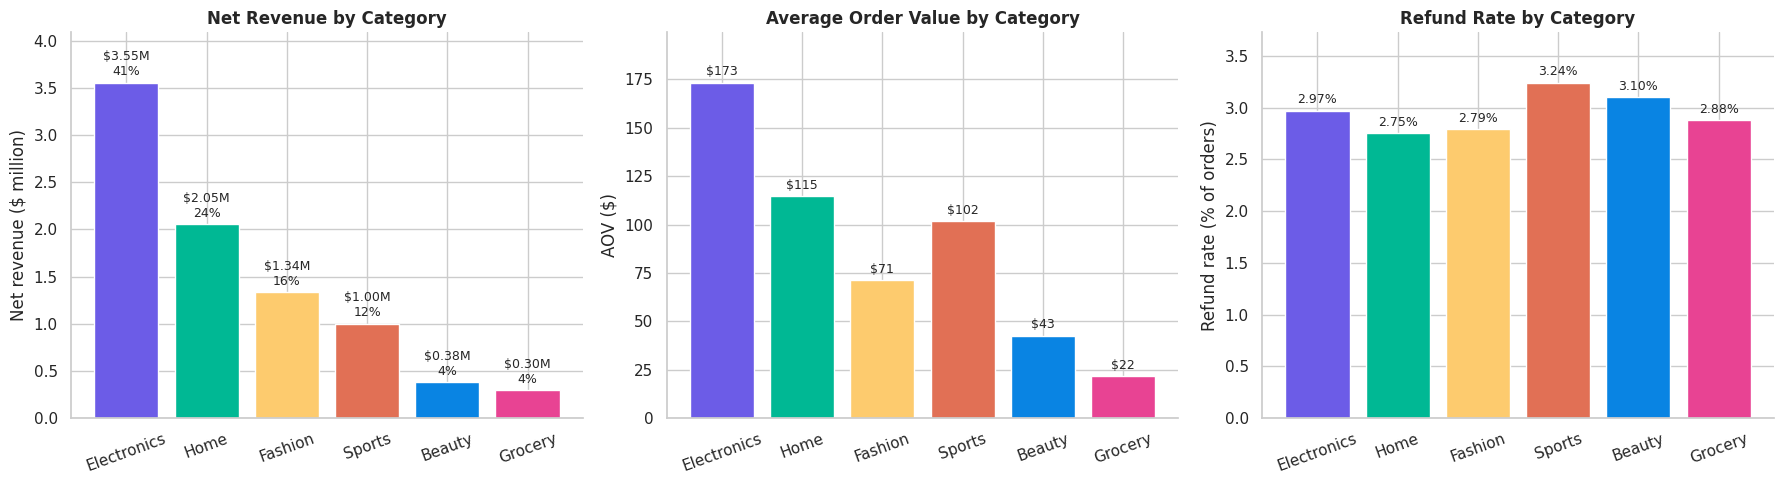

In [28]:
# Revenue by category, campaign exposure and refund hot-spots
rev_cat = run_sql("""
SELECT category,
       COUNT(*)                                       AS orders,
       SUM(quantity)                                  AS units,
       ROUND(SUM(net_revenue), 0)                     AS net_revenue,
       ROUND(100.0 * SUM(net_revenue) / SUM(SUM(net_revenue)) OVER (), 1) AS revenue_share_pct,
       ROUND(AVG(order_value), 2)                     AS aov,
       ROUND(100.0 * AVG(refund_flag), 2)             AS refund_rate_pct
FROM v_transactions
WHERE category IS NOT NULL AND has_revenue = 1
GROUP BY category
ORDER BY net_revenue DESC
""")
display(rev_cat)

rev_exposure = run_sql("""
SELECT CASE has_campaign WHEN 1 THEN 'Campaign-attributed' ELSE 'No campaign' END AS attribution,
       COUNT(*)                                       AS orders,
       ROUND(SUM(net_revenue), 0)                     AS net_revenue,
       ROUND(100.0 * SUM(net_revenue) / SUM(SUM(net_revenue)) OVER (), 1) AS revenue_share_pct,
       ROUND(AVG(order_value), 2)                     AS aov,
       ROUND(100.0 * AVG(refund_flag), 2)             AS refund_rate_pct
FROM v_transactions
WHERE has_revenue = 1
GROUP BY has_campaign
ORDER BY has_campaign DESC
""")
display(rev_exposure)

# Refund-rate differences (chi-square on order level)
refund_rows = []
tx_ref = run_sql("""
SELECT v.refund_flag, v.category, v.discount_applied, v.has_campaign, c.loyalty_tier
FROM v_transactions v JOIN customers c ON c.customer_id = v.customer_id
""")
for label, col in [("Category", "category"), ("Loyalty tier", "loyalty_tier"), ("Campaign attribution", "has_campaign")]:
    sub = tx_ref.dropna(subset=[col])
    chi2, p, dof, v = cramers_v(pd.crosstab(sub[col], sub["refund_flag"]))
    refund_rows.append({"Refund rate vs": label, "Chi-square": chi2, "p_raw": p, "Cramér's V": v})
refund_tests = pd.DataFrame(refund_rows)
refund_tests["q-value (BH)"] = benjamini_hochberg(refund_tests["p_raw"])
rf = refund_tests.copy(); rf["p_raw"] = rf["p_raw"].map(fmt_p); rf["q-value (BH)"] = rf["q-value (BH)"].map(fmt_p); rf["Cramér's V"] = rf["Cramér's V"].map(lambda x: f"{x:.4f}")
display(rf)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
bar_panel(axes[0], rev_cat["category"], rev_cat["net_revenue"] / 1e6, "Net Revenue by Category", ylabel="Net revenue ($ million)", fmt="${:,.2f}M", rotation=20,
          extra=[f"{s:.0f}%" for s in rev_cat["revenue_share_pct"]])
bar_panel(axes[1], rev_cat["category"], rev_cat["aov"], "Average Order Value by Category", ylabel="AOV ($)", fmt="${:,.0f}", rotation=20)
bar_panel(axes[2], rev_cat["category"], rev_cat["refund_rate_pct"], "Refund Rate by Category", ylabel="Refund rate (% of orders)", fmt="{:.2f}%", rotation=20)
plt.tight_layout(); plt.show()

top_cat = rev_cat.iloc[0]; camp_share = rev_exposure.loc[rev_exposure["attribution"] == "Campaign-attributed", "revenue_share_pct"].iloc[0]
refund_sig = refund_tests[refund_tests["q-value (BH)"] < 0.05]["Refund rate vs"].tolist()
FINDINGS.update({"top_cat": top_cat["category"], "top_cat_share": top_cat["revenue_share_pct"], "camp_rev_share": camp_share})
show_banner(
    "Where the revenue comes from",
    f"<strong>{html.escape(str(top_cat['category']))}</strong> generates {top_cat['revenue_share_pct']:.0f}% of net revenue (AOV {money(top_cat['aov'], 2)}). "
    f"Campaign-attributed orders bring <strong>{camp_share:.0f}%</strong> of net revenue. "
    + (f"Refund rates differ significantly by: <strong>{html.escape(', '.join(refund_sig))}</strong>. " if refund_sig else
       "<strong>No significant difference in refund rate</strong> was found by category, loyalty tier or campaign attribution, so refunds look evenly spread rather than concentrated in a problem segment. ")
    + "Category revenue reflects both price level and order volume: high-priced categories can lead revenue with fewer orders.",
    color="green", icon="💡"
)

,decile,buyers,net_revenue,revenue_share_pct,cumulative_share_pct
0,1,6010,"2,824,261.00",32.70,32.70
1,2,6009,"1,563,182.00",18.10,50.80
2,3,6009,"1,140,617.00",13.20,64.00
3,4,6009,"881,215.00",10.20,74.20
4,5,6009,"689,624.00",8.00,82.20
5,6,6009,"540,924.00",6.30,88.50
6,7,6009,"417,302.00",4.80,93.30
7,8,6009,"307,175.00",3.60,96.90
8,9,6009,"194,155.00",2.20,99.10
9,10,6009,"71,815.00",0.80,99.90


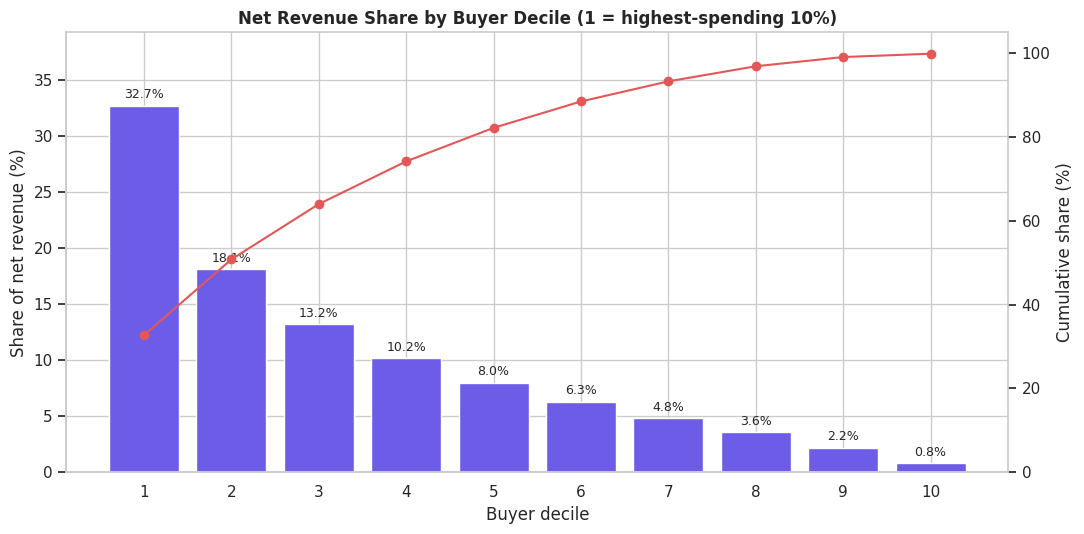

In [29]:
# Revenue concentration across buyers (Pareto)
conc = run_sql("""
WITH buyer_rev AS (
    SELECT customer_id, SUM(net_revenue) AS net_revenue
    FROM v_transactions
    WHERE has_revenue = 1
    GROUP BY customer_id
),
ranked AS (
    SELECT customer_id, net_revenue,
           NTILE(10) OVER (ORDER BY net_revenue DESC) AS decile
    FROM buyer_rev
)
SELECT decile,
       COUNT(*)                                              AS buyers,
       ROUND(SUM(net_revenue), 0)                            AS net_revenue,
       ROUND(100.0 * SUM(net_revenue) / SUM(SUM(net_revenue)) OVER (), 1) AS revenue_share_pct
FROM ranked
GROUP BY decile
ORDER BY decile
""")
conc["cumulative_share_pct"] = conc["revenue_share_pct"].cumsum()
display(conc)

fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar(conc["decile"].astype(str), conc["revenue_share_pct"], color=PALETTE[0])
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in conc["revenue_share_pct"]], padding=3, fontsize=9)
ax2 = ax.twinx(); ax2.plot(conc["decile"].astype(str), conc["cumulative_share_pct"], color="#E45756", marker="o"); ax2.set_ylabel("Cumulative share (%)"); ax2.set_ylim(0, 105); ax2.grid(False)
ax.set_title("Net Revenue Share by Buyer Decile (1 = highest-spending 10%)", fontweight="bold")
ax.set_xlabel("Buyer decile"); ax.set_ylabel("Share of net revenue (%)"); ax.set_ylim(0, conc["revenue_share_pct"].max() * 1.2)
sns.despine(ax=ax); plt.tight_layout(); plt.show()

top10 = conc.loc[0, "revenue_share_pct"]; top20 = conc.loc[:1, "revenue_share_pct"].sum(); bottom50 = conc.loc[5:, "revenue_share_pct"].sum()
FINDINGS.update({"top10_share": top10, "top20_share": top20, "bottom50_share": bottom50})
show_banner(
    "Revenue concentration",
    f"The top 10% of buyers generate <strong>{top10:.1f}%</strong> of net revenue and the top 20% generate <strong>{top20:.1f}%</strong>, while the bottom half of buyers contribute {bottom50:.1f}%. "
    + ("Revenue is heavily concentrated: a small group of buyers drives most of it, so protecting those customers deserves priority." if top20 >= 70 else
       "Revenue is more concentrated than an even spread (which would give 20%) but well short of a strict 80/20 pattern: the top buyers matter, yet revenue still depends on a broad base of buyers." if top20 >= 35 else
       "Revenue is spread broadly across buyers, with no small group dominating."),
    color="teal", icon="📊"
)

## 11. Customer segmentation

Segmentation answers **who buys, how often and how much**. Customers are grouped by their profile (loyalty tier, acquisition channel, country, age group, gender) and then by purchasing behaviour (RFM).

Because the 100,000 customers include non-buyers, SQL uses a `LEFT JOIN` from `customers` to the transaction totals. This keeps customers with zero purchases in the denominator, so *buyer rate* and *revenue per customer* are not overstated.

In [30]:
# One row per customer with purchase totals (LEFT JOIN keeps non-buyers)
cust_value = run_sql("""
SELECT c.customer_id, c.loyalty_tier, c.acquisition_channel, c.country, c.gender, c.age_group,
       COUNT(v.transaction_id)               AS orders,
       COALESCE(SUM(v.net_revenue), 0)       AS net_revenue,
       COALESCE(SUM(v.order_value), 0)       AS gross_sales,
       COALESCE(SUM(v.refund_flag), 0)       AS refunds
FROM customers c
LEFT JOIN v_transactions v ON v.customer_id = c.customer_id
GROUP BY c.customer_id, c.loyalty_tier, c.acquisition_channel, c.country, c.gender, c.age_group
""")
cust_value["is_buyer"] = (cust_value["orders"] > 0).astype(int)

def segment_table(col, order=None):
    g = cust_value.groupby(col).agg(customers=("customer_id", "count"), buyers=("is_buyer", "sum"), orders=("orders", "sum"),
                                    net_revenue=("net_revenue", "sum"), gross_sales=("gross_sales", "sum"), refunds=("refunds", "sum"))
    g["buyer_rate_%"] = g["buyers"] / g["customers"] * 100
    g["orders_per_buyer"] = g["orders"] / g["buyers"]
    g["revenue_per_customer ($)"] = g["net_revenue"] / g["customers"]
    g["revenue_per_buyer ($)"] = g["net_revenue"] / g["buyers"]
    g["refund_rate_%"] = g["refunds"] / g["orders"] * 100
    g = g.reindex(order) if order else g.sort_values("revenue_per_customer ($)", ascending=False)
    return g.reset_index()

seg_tier = segment_table("loyalty_tier", TIER_ORDER)
seg_acq = segment_table("acquisition_channel")
seg_country = segment_table("country")
seg_age = segment_table("age_group", ["18-24", "25-34", "35-44", "45-54", "55+"])
seg_gender = segment_table("gender")

print("Loyalty tier"); display(seg_tier)
print("Acquisition channel"); display(seg_acq)
print("Country"); display(seg_country)
print("Age group"); display(seg_age)
print("Gender"); display(seg_gender)

Loyalty tier


,loyalty_tier,customers,buyers,orders,net_revenue,gross_sales,refunds,buyer_rate_%,orders_per_buyer,revenue_per_customer ($),revenue_per_buyer ($),refund_rate_%
0,Bronze,60276,36246,55232,"4,615,872.65","4,753,906.53",1631,60.13,1.52,76.58,127.35,2.95
1,Silver,24912,16855,28005,"2,369,478.75","2,436,870.74",816,67.66,1.66,95.11,140.58,2.91
2,Gold,11794,8705,15906,"1,313,263.06","1,351,381.82",458,73.81,1.83,111.35,150.86,2.88
3,Platinum,3018,2229,3984,"331,654.85","344,413.17",124,73.86,1.79,109.89,148.79,3.11


Acquisition channel


,acquisition_channel,customers,buyers,orders,net_revenue,gross_sales,refunds,buyer_rate_%,orders_per_buyer,revenue_per_customer ($),revenue_per_buyer ($),refund_rate_%
0,Organic,30200,19370,31148,"2,639,242.82","2,713,150.87",890,64.14,1.61,87.39,136.25,2.86
1,Email,14903,9499,15331,"1,290,734.52","1,325,649.09",420,63.74,1.61,86.61,135.88,2.74
2,Paid Search,29950,19251,31112,"2,580,468.61","2,661,265.29",925,64.28,1.62,86.16,134.04,2.97
3,Referral,9968,6330,10239,"858,748.74","882,692.31",297,63.50,1.62,86.15,135.66,2.90
4,Social,14979,9585,15297,"1,261,074.62","1,303,814.70",497,63.99,1.60,84.19,131.57,3.25


Country


,country,customers,buyers,orders,net_revenue,gross_sales,refunds,buyer_rate_%,orders_per_buyer,revenue_per_customer ($),revenue_per_buyer ($),refund_rate_%
0,AU,7021,4515,7350,"610,977.16","631,159.00",232,64.31,1.63,87.02,135.32,3.16
1,US,34931,22296,35981,"3,033,489.05","3,116,890.53",1010,63.83,1.61,86.84,136.06,2.81
2,IN,20089,12838,20727,"1,732,260.65","1,784,812.37",598,63.91,1.61,86.23,134.93,2.89
3,BR,10002,6453,10392,"862,223.63","887,649.83",293,64.52,1.61,86.21,133.62,2.82
4,UK,10155,6507,10311,"869,993.11","895,730.93",315,64.08,1.58,85.67,133.70,3.05
5,CA,9906,6356,10193,"846,893.46","875,931.53",322,64.16,1.60,85.49,133.24,3.16
6,DE,7896,5070,8173,"674,432.25","694,398.07",259,64.21,1.61,85.41,133.02,3.17


Age group


,age_group,customers,buyers,orders,net_revenue,gross_sales,refunds,buyer_rate_%,orders_per_buyer,revenue_per_customer ($),revenue_per_buyer ($),refund_rate_%
0,18-24,14514,9227,14855,"1,244,073.50","1,278,417.66",413,63.57,1.61,85.72,134.83,2.78
1,25-34,33125,21279,34438,"2,870,996.58","2,955,756.49",998,64.24,1.62,86.67,134.92,2.90
2,35-44,35367,22659,36309,"3,058,387.19","3,150,763.84",1059,64.07,1.60,86.48,134.97,2.92
3,45-54,14448,9216,14850,"1,238,834.09","1,278,317.01",485,63.79,1.61,85.74,134.42,3.27
4,55+,2546,1654,2675,"217,977.95","223,317.26",74,64.96,1.62,85.62,131.79,2.77


Gender


,gender,customers,buyers,orders,net_revenue,gross_sales,refunds,buyer_rate_%,orders_per_buyer,revenue_per_customer ($),revenue_per_buyer ($),refund_rate_%
0,Other,3940,2518,4132,"350,344.01","358,300.64",126,63.91,1.64,88.92,139.14,3.05
1,Female,48006,30785,49506,"4,148,272.29","4,273,931.39",1466,64.13,1.61,86.41,134.75,2.96
2,Male,48054,30732,49489,"4,131,653.01","4,254,340.23",1437,63.95,1.61,85.98,134.44,2.90


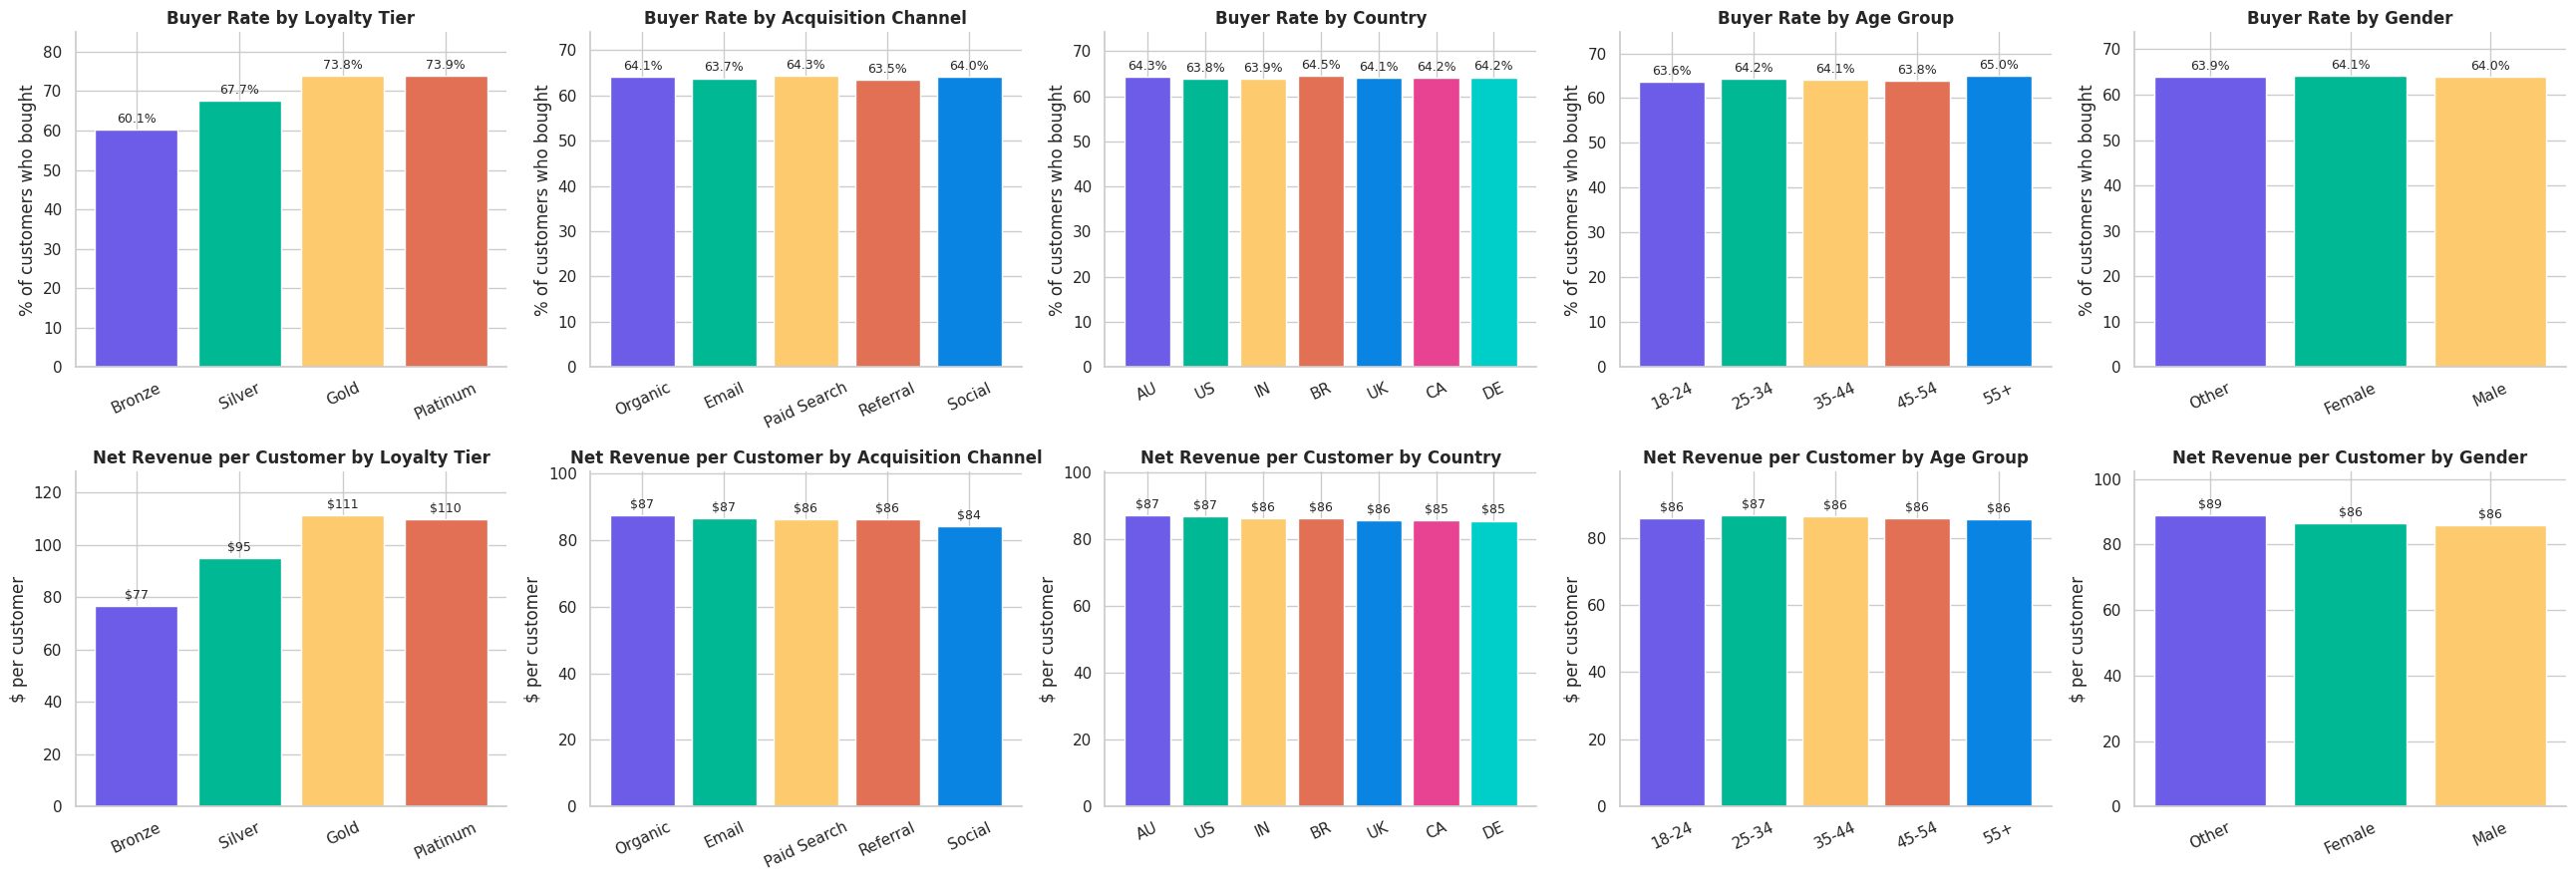

,Dimension,Buyer rate: chi-square p,Buyer rate: Cramér's V,Revenue per customer: Kruskal-Wallis p,Revenue: epsilon²,Buyer rate q,Revenue q
0,Loyalty Tier,<0.001,0.1075,<0.001,0.0137,<0.001,<0.001
1,Acquisition Channel,0.608,0.0052,0.234,0.0000,0.952,0.779
2,Country,0.899,0.0047,0.952,0.0000,0.952,0.952
3,Age Group,0.509,0.0057,0.594,0.0000,0.952,0.952
4,Gender,0.841,0.0019,0.882,0.0000,0.952,0.952


In [31]:
# Visual comparison of buyer rate and revenue per customer across every profile dimension
dims = [("loyalty_tier", seg_tier, "Loyalty Tier"), ("acquisition_channel", seg_acq, "Acquisition Channel"), ("country", seg_country, "Country"),
        ("age_group", seg_age, "Age Group"), ("gender", seg_gender, "Gender")]
fig, axes = plt.subplots(2, 5, figsize=(26, 9))
for j, (col, tbl, title) in enumerate(dims):
    bar_panel(axes[0, j], tbl[col], tbl["buyer_rate_%"], f"Buyer Rate by {title}", ylabel="% of customers who bought", fmt="{:.1f}%", rotation=25)
    bar_panel(axes[1, j], tbl[col], tbl["revenue_per_customer ($)"], f"Net Revenue per Customer by {title}", ylabel="$ per customer", fmt="${:,.0f}", rotation=25)
plt.tight_layout(); plt.show()

# Tests: is buyer status associated with each dimension? Does revenue per customer differ (Kruskal-Wallis)?
seg_rows = []
for col, tbl, title in dims:
    chi2, p, dof, v = cramers_v(pd.crosstab(cust_value[col], cust_value["is_buyer"]))
    groups = [g["net_revenue"].values for _, g in cust_value.groupby(col)]
    h, kp = stats.kruskal(*groups)
    n = len(cust_value); eps2 = (h - len(groups) + 1) / (n - len(groups))
    seg_rows.append({"Dimension": title, "Buyer rate: chi-square p": p, "Buyer rate: Cramér's V": v,
                     "Revenue per customer: Kruskal-Wallis p": kp, "Revenue: epsilon²": max(eps2, 0)})
seg_tests_df = pd.DataFrame(seg_rows)
all_p = np.r_[seg_tests_df["Buyer rate: chi-square p"].values, seg_tests_df["Revenue per customer: Kruskal-Wallis p"].values]
q = benjamini_hochberg(all_p)
seg_tests_df["Buyer rate q"] = q[:len(dims)]; seg_tests_df["Revenue q"] = q[len(dims):]
sg = seg_tests_df.copy()
for c in ["Buyer rate: chi-square p", "Revenue per customer: Kruskal-Wallis p", "Buyer rate q", "Revenue q"]:
    sg[c] = sg[c].map(fmt_p)
for c in ["Buyer rate: Cramér's V", "Revenue: epsilon²"]:
    sg[c] = sg[c].map(lambda x: f"{x:.4f}")
display(sg)

sig_dims = seg_tests_df[(seg_tests_df["Buyer rate q"] < 0.05) | (seg_tests_df["Revenue q"] < 0.05)]["Dimension"].tolist()
flat_dims = seg_tests_df[(seg_tests_df["Buyer rate q"] >= 0.05) & (seg_tests_df["Revenue q"] >= 0.05)]["Dimension"].tolist()
t_top, t_bot = seg_tier.iloc[-1], seg_tier.iloc[0]
FINDINGS.update({"tier_top_rev": seg_tier["revenue_per_customer ($)"].max(), "tier_bot_rev": seg_tier["revenue_per_customer ($)"].min(),
                 "sig_dims": sig_dims, "flat_dims": flat_dims, "buyer_rate_overall": cust_value["is_buyer"].mean() * 100})
show_banner(
    "What differentiates customers?",
    f"Overall, <strong>{cust_value['is_buyer'].mean()*100:.1f}%</strong> of customers made at least one purchase. "
    f"Revenue per customer ranges from <strong>{money(seg_tier['revenue_per_customer ($)'].min(), 2)}</strong> ({html.escape(str(seg_tier.loc[seg_tier['revenue_per_customer ($)'].idxmin(), 'loyalty_tier']))}) "
    f"to <strong>{money(seg_tier['revenue_per_customer ($)'].max(), 2)}</strong> ({html.escape(str(seg_tier.loc[seg_tier['revenue_per_customer ($)'].idxmax(), 'loyalty_tier']))}). "
    f"Dimensions with a significant difference after adjustment: <strong>{html.escape(', '.join(sig_dims) or 'none')}</strong>. "
    f"No detectable difference for: <strong>{html.escape(', '.join(flat_dims) or 'none')}</strong>. "
    + (f"Profile attributes with no detectable difference ({html.escape(', '.join(flat_dims))}) are weak targeting variables in this dataset." if flat_dims else ""),
    color="purple", icon="🧩"
)

### 11.1 RFM segmentation (Recency · Frequency · Monetary)

RFM describes buying behaviour with three numbers per buyer:

- **Recency**: days since the last purchase (lower is better), measured from the day after the last transaction in the data.
- **Frequency**: number of orders.
- **Monetary**: net revenue.

Recency is scored 1–4 with `NTILE(4)` (4 = most recent). Frequency is scored by **rules** (1 order = 1, 2 = 2, 3 = 3, 4+ = 4) because most buyers have exactly one order and quartiles would split identical values arbitrarily. Segments are then assigned with a SQL `CASE` expression.

> Monetary value excludes orders whose revenue is missing (about 10% of orders), so it is slightly understated for some buyers; it is used for profiling, not for assigning segments.

,segment,customers,avg_recency_days,avg_frequency,avg_monetary,total_monetary,customers_%,revenue_share_%
0,Champions,6966,159.73,3.37,283.52,"1,974,998.20",10.88,22.88
1,Loyal (lapsing),1885,564.54,3.21,266.81,"502,934.95",2.94,5.83
2,Potential loyalists,11325,182.84,2.00,166.48,"1,885,332.80",17.69,21.85
3,New / recent,13726,198.33,1.00,82.44,"1,131,628.91",21.44,13.11
4,At risk,7128,634.57,2.00,167.73,"1,195,571.72",11.13,13.85
5,Hibernating,23005,747.71,1.00,84.32,"1,939,802.73",35.93,22.48


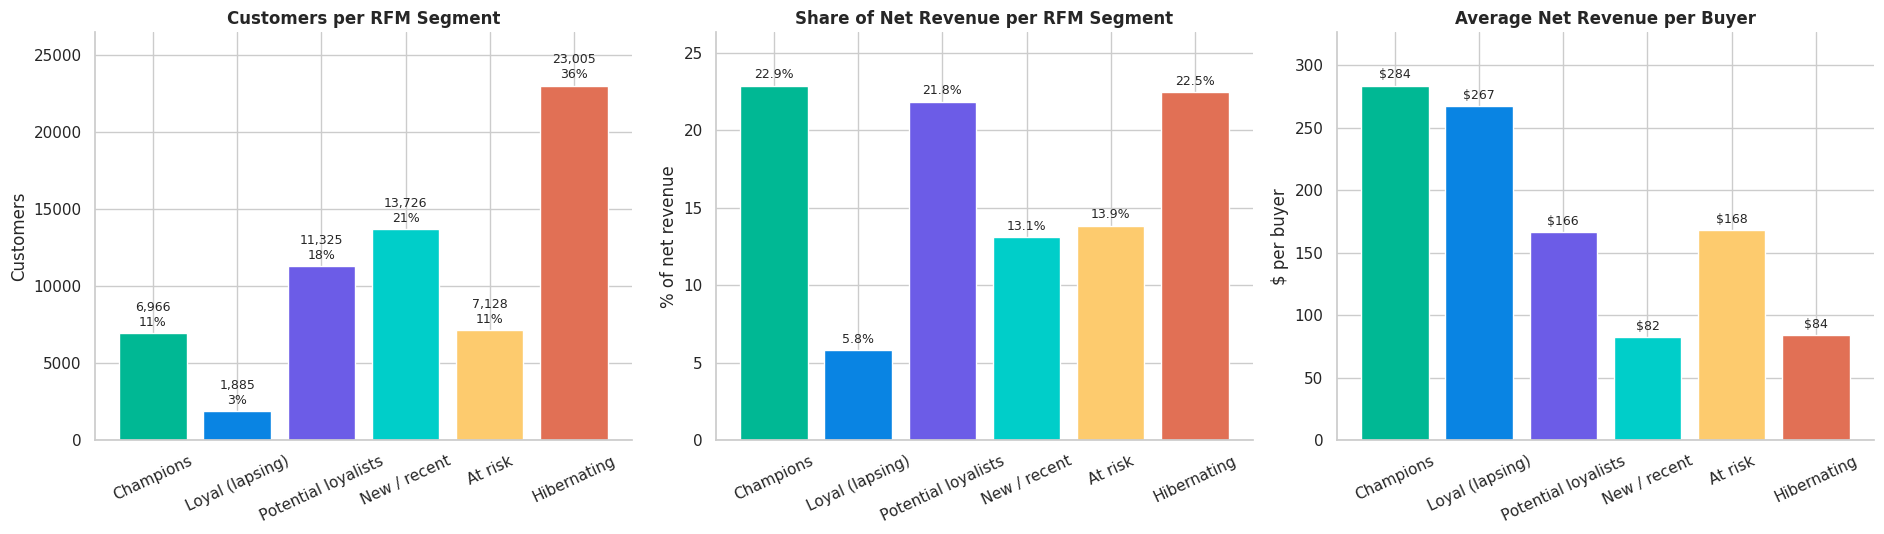

In [32]:
rfm = run_sql("""
WITH ref AS (SELECT date(MAX(timestamp), '+1 day') AS ref_date FROM transactions),
base AS (
    SELECT v.customer_id,
           CAST(julianday((SELECT ref_date FROM ref)) - julianday(MAX(date(v.timestamp))) AS INTEGER) AS recency_days,
           COUNT(*)                          AS frequency,
           COALESCE(SUM(v.net_revenue), 0)   AS monetary
    FROM v_transactions v
    GROUP BY v.customer_id
),
scored AS (
    SELECT *,
           NTILE(4) OVER (ORDER BY recency_days DESC) AS r_score,
           CASE WHEN frequency >= 4 THEN 4 ELSE frequency END AS f_score
    FROM base
)
SELECT customer_id, recency_days, frequency, monetary, r_score, f_score,
       CASE
           WHEN r_score >= 3 AND f_score >= 3 THEN 'Champions'
           WHEN f_score >= 3                  THEN 'Loyal (lapsing)'
           WHEN r_score >= 3 AND f_score = 2  THEN 'Potential loyalists'
           WHEN r_score >= 3 AND f_score = 1  THEN 'New / recent'
           WHEN f_score = 2                   THEN 'At risk'
           ELSE 'Hibernating'
       END AS segment
FROM scored
""")

RFM_ORDER = ["Champions", "Loyal (lapsing)", "Potential loyalists", "New / recent", "At risk", "Hibernating"]
rfm_summary = rfm.groupby("segment").agg(customers=("customer_id", "count"), avg_recency_days=("recency_days", "mean"),
                                         avg_frequency=("frequency", "mean"), avg_monetary=("monetary", "mean"),
                                         total_monetary=("monetary", "sum")).reindex(RFM_ORDER).reset_index()
rfm_summary["customers_%"] = rfm_summary["customers"] / rfm_summary["customers"].sum() * 100
rfm_summary["revenue_share_%"] = rfm_summary["total_monetary"] / rfm_summary["total_monetary"].sum() * 100
display(rfm_summary)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
seg_colors = ["#00B894", "#0984E3", "#6C5CE7", "#00CEC9", "#FDCB6E", "#E17055"]
bar_panel(axes[0], rfm_summary["segment"], rfm_summary["customers"], "Customers per RFM Segment", ylabel="Customers", rotation=25, colors=seg_colors,
          extra=[f"{p:.0f}%" for p in rfm_summary["customers_%"]])
bar_panel(axes[1], rfm_summary["segment"], rfm_summary["revenue_share_%"], "Share of Net Revenue per RFM Segment", ylabel="% of net revenue", fmt="{:.1f}%", rotation=25, colors=seg_colors)
bar_panel(axes[2], rfm_summary["segment"], rfm_summary["avg_monetary"], "Average Net Revenue per Buyer", ylabel="$ per buyer", fmt="${:,.0f}", rotation=25, colors=seg_colors)
plt.tight_layout(); plt.show()

champ = rfm_summary.iloc[0]; risk = rfm_summary[rfm_summary["segment"].isin(["At risk", "Loyal (lapsing)"])]
hib = rfm_summary[rfm_summary["segment"] == "Hibernating"].iloc[0]
FINDINGS.update({"champ_pct": champ["customers_%"], "champ_rev": champ["revenue_share_%"],
                 "risk_pct": risk["customers_%"].sum(), "risk_rev": risk["revenue_share_%"].sum(),
                 "hib_pct": hib["customers_%"], "hib_rev": hib["revenue_share_%"]})
show_banner(
    "What the RFM segments show",
    f"<strong>Champions</strong> (recent and frequent buyers) are only {champ['customers_%']:.1f}% of buyers but generate {champ['revenue_share_%']:.1f}% of net revenue. "
    f"<strong>At-risk and lapsing-loyal</strong> buyers (previously repeat buyers who have gone quiet) are {risk['customers_%'].sum():.1f}% of buyers and {risk['revenue_share_%'].sum():.1f}% of revenue, "
    "which makes them a sensible win-back priority, because they have already shown repeat-buying behaviour. "
    f"<strong>Hibernating</strong> buyers (a single, older purchase) are the largest group at {hib['customers_%']:.1f}% but bring {hib['revenue_share_%']:.1f}% of revenue. "
    "Recency is relative to the last date in the data (end of 2023); in a live business, re-run the query with the current date.",
    color="teal", icon="🎯"
)

## 12. Trends and seasonality

This section looks at **when** customers buy: month by month, by calendar month, by day of week and by hour. Event volume is spread almost evenly over time, so changes in purchase rate and revenue come from *behaviour*, not from more or fewer events.

**How to read the charts:** a flat line means no trend. A repeating spike in the same calendar months across years indicates **seasonality**.

,month,events,purchases,purchase_rate_pct,orders,net_revenue,aov,is_holiday
0,2021-01,56575,2813,4.97,2813,"230,743.00",94.27,False
1,2021-02,51072,2473,4.84,2473,"213,446.00",97.89,False
2,2021-03,56146,2812,5.01,2812,"236,469.00",97.20,False
3,2021-04,54811,2713,4.95,2713,"231,555.00",97.14,False
4,2021-05,56683,2859,5.04,2859,"243,624.00",96.07,False
5,2021-06,54622,2668,4.88,2668,"224,068.00",94.97,False
6,2021-07,56645,2749,4.85,2749,"237,841.00",99.92,False
7,2021-08,56730,2826,4.98,2826,"236,011.00",94.59,False
8,2021-09,54739,2721,4.97,2721,"224,594.00",93.78,False
9,2021-10,56657,2762,4.88,2762,"231,880.00",95.08,False


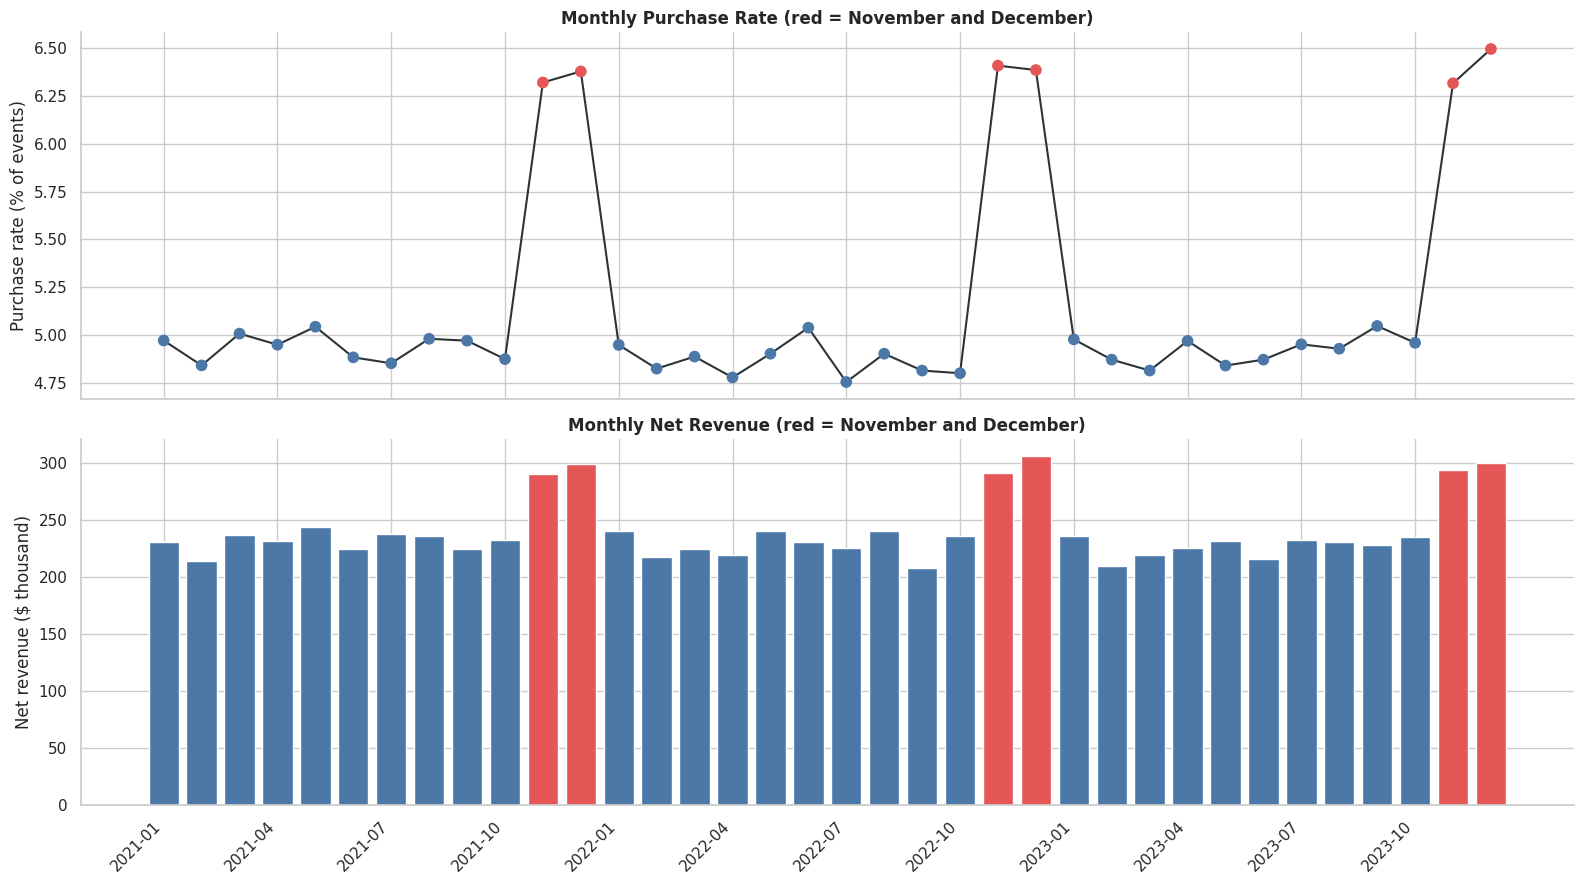

,year,events,purchases,purchase_rate_pct,net_revenue,aov,net_revenue_growth_%
0,2021,666156,34474,5.17,"2,898,776.00",95.82,NaN
1,2022,667512,34187,5.12,"2,876,743.00",96.79,-0.76
2,2023,666332,34466,5.17,"2,854,750.00",95.07,-0.76


In [33]:
monthly = run_sql("""
SELECT e.event_month AS month,
       COUNT(*)                                  AS events,
       SUM(e.is_purchase)                        AS purchases,
       ROUND(100.0 * AVG(e.is_purchase), 3)      AS purchase_rate_pct
FROM events e
GROUP BY e.event_month
ORDER BY e.event_month
""")
monthly_rev = run_sql("""
SELECT tx_month AS month, COUNT(*) AS orders, ROUND(SUM(net_revenue), 0) AS net_revenue, ROUND(AVG(order_value), 2) AS aov
FROM v_transactions
GROUP BY tx_month
ORDER BY tx_month
""")
monthly = monthly.merge(monthly_rev, on="month")
monthly["is_holiday"] = monthly["month"].str[5:7].isin(["11", "12"])
display(monthly.head(14))

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
cols = ["#E45756" if h else "#4C78A8" for h in monthly["is_holiday"]]
axes[0].plot(monthly["month"], monthly["purchase_rate_pct"], color="#2D3436", linewidth=1.5, zorder=1)
axes[0].scatter(monthly["month"], monthly["purchase_rate_pct"], c=cols, s=55, zorder=2)
axes[0].set_title("Monthly Purchase Rate (red = November and December)", fontweight="bold"); axes[0].set_ylabel("Purchase rate (% of events)")
axes[1].bar(monthly["month"], monthly["net_revenue"] / 1000, color=cols)
axes[1].set_title("Monthly Net Revenue (red = November and December)", fontweight="bold"); axes[1].set_ylabel("Net revenue ($ thousand)")
axes[1].set_xticks(range(0, len(monthly), 3)); axes[1].set_xticklabels(monthly["month"].iloc[::3], rotation=45, ha="right")
sns.despine(); plt.tight_layout(); plt.show()

yearly = run_sql("""
SELECT e.event_year AS year, COUNT(*) AS events, SUM(e.is_purchase) AS purchases, ROUND(100.0 * AVG(e.is_purchase), 3) AS purchase_rate_pct
FROM events e GROUP BY e.event_year ORDER BY e.event_year
""").merge(run_sql("SELECT tx_year AS year, ROUND(SUM(net_revenue), 0) AS net_revenue, ROUND(AVG(order_value), 2) AS aov FROM v_transactions GROUP BY tx_year"), on="year")
yearly["net_revenue_growth_%"] = yearly["net_revenue"].pct_change() * 100
display(yearly)
FINDINGS["yoy_growth_max"] = yearly["net_revenue_growth_%"].abs().max()

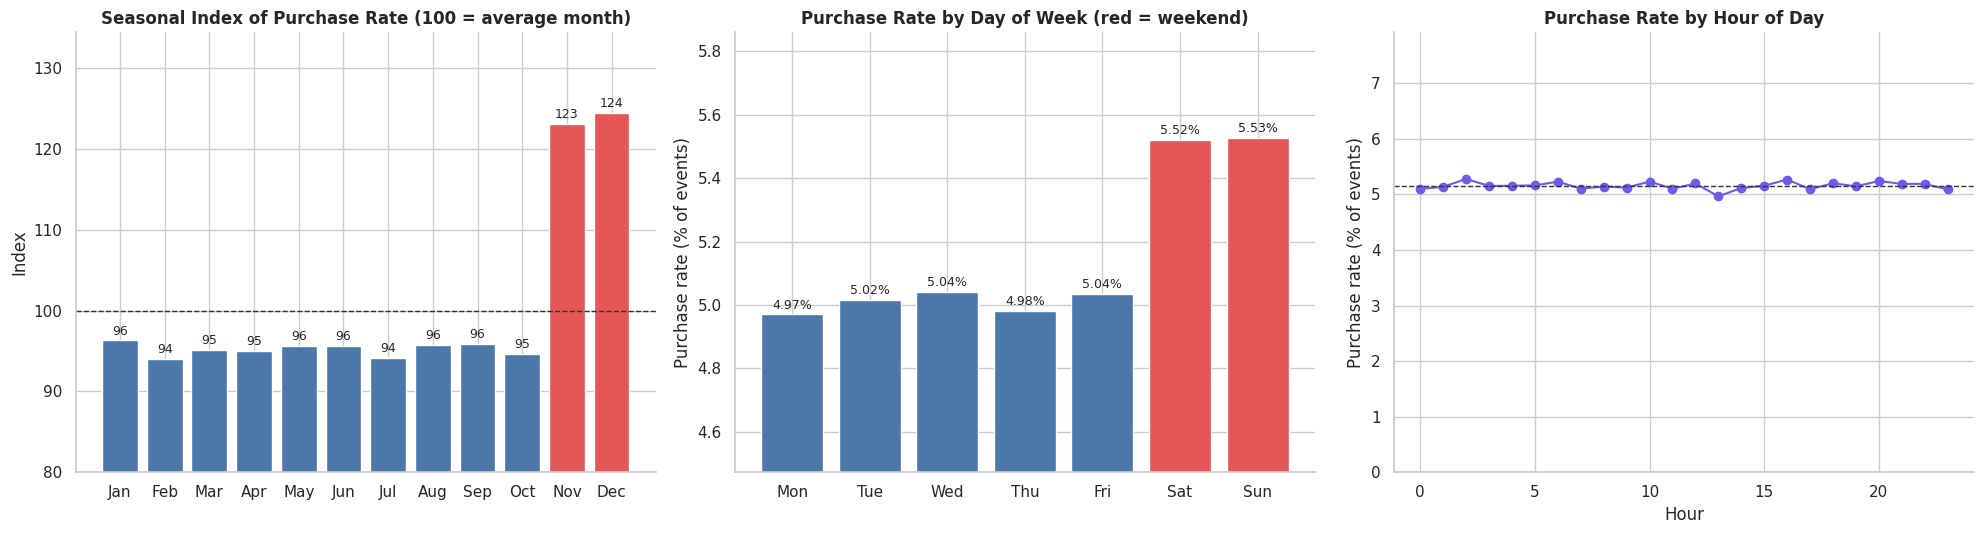

,Effect,Rate with effect (%),Rate without (%),Difference (pp),95% CI low (pp),95% CI high (pp),Relative lift (%),p_raw,q-value (BH)
0,Holiday season (Nov-Dec) vs other months,6.38,4.91,1.47,1.39,1.56,30.04,<0.001,<0.001
1,Weekend vs weekday,5.52,5.01,0.51,0.45,0.58,10.27,<0.001,<0.001


holiday_season,exposure,experiment_group,Other months (%),Nov-Dec (%),holiday_lift_pp
0,Campaign exposed,Control,7.40,9.81,2.41
1,Campaign exposed,Variant_A,7.93,10.17,2.24
2,Campaign exposed,Variant_B,8.92,11.58,2.66
3,No campaign,Control,1.61,2.05,0.44
4,No campaign,Variant_A,2.10,2.60,0.50
5,No campaign,Variant_B,3.11,3.93,0.82


In [34]:
# Calendar-month seasonality, day of week and hour
by_month = run_sql("""
SELECT month_num, COUNT(*) AS events, SUM(is_purchase) AS purchases, 100.0 * AVG(is_purchase) AS purchase_rate_pct
FROM events GROUP BY month_num ORDER BY month_num
""")
overall = by_month["purchases"].sum() / by_month["events"].sum() * 100
by_month["seasonal_index"] = by_month["purchase_rate_pct"] / overall * 100

by_dow = run_sql("""
SELECT CAST(strftime('%w', timestamp) AS INTEGER) AS dow_sun0, COUNT(*) AS events, SUM(is_purchase) AS purchases, 100.0 * AVG(is_purchase) AS purchase_rate_pct
FROM events GROUP BY 1 ORDER BY 1
""")
dow_names = {0: "Sun", 1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat"}
by_dow["day"] = by_dow["dow_sun0"].map(dow_names)
by_dow = by_dow.set_index("day").reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]).reset_index()

by_hour = run_sql("""
SELECT event_hour AS hour, COUNT(*) AS events, SUM(is_purchase) AS purchases, 100.0 * AVG(is_purchase) AS purchase_rate_pct
FROM events GROUP BY event_hour ORDER BY event_hour
""")

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
mnames = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
bars = axes[0].bar(mnames, by_month["seasonal_index"], color=["#E45756" if m in (11, 12) else "#4C78A8" for m in by_month["month_num"]])
axes[0].axhline(100, color="#2D3436", linestyle="--", linewidth=1)
axes[0].bar_label(bars, labels=[f"{v:.0f}" for v in by_month["seasonal_index"]], padding=2, fontsize=9)
axes[0].set_title("Seasonal Index of Purchase Rate (100 = average month)", fontweight="bold"); axes[0].set_ylabel("Index")
axes[0].set_ylim(80, by_month["seasonal_index"].max() * 1.08)
bars = axes[1].bar(by_dow["day"], by_dow["purchase_rate_pct"], color=["#4C78A8"] * 5 + ["#E45756"] * 2)
axes[1].bar_label(bars, labels=[f"{v:.2f}%" for v in by_dow["purchase_rate_pct"]], padding=2, fontsize=9)
axes[1].set_title("Purchase Rate by Day of Week (red = weekend)", fontweight="bold"); axes[1].set_ylabel("Purchase rate (% of events)")
axes[1].set_ylim(by_dow["purchase_rate_pct"].min() * 0.9, by_dow["purchase_rate_pct"].max() * 1.06)
axes[2].plot(by_hour["hour"], by_hour["purchase_rate_pct"], marker="o", color="#6C5CE7")
axes[2].axhline(overall, color="#2D3436", linestyle="--", linewidth=1)
axes[2].set_title("Purchase Rate by Hour of Day", fontweight="bold"); axes[2].set_xlabel("Hour"); axes[2].set_ylabel("Purchase rate (% of events)")
axes[2].set_ylim(0, by_hour["purchase_rate_pct"].max() * 1.5)
for ax in axes: sns.despine(ax=ax)
plt.tight_layout(); plt.show()

# Tests: holiday season and weekend
def rate_test(flag_col, label):
    g = ev.groupby(flag_col)["is_purchase"].agg(["sum", "count"])
    r = two_prop_test(g.loc[1, "sum"], g.loc[1, "count"], g.loc[0, "sum"], g.loc[0, "count"])
    return {"Effect": label, "Rate with effect (%)": r["rate_treat"] * 100, "Rate without (%)": r["rate_ctrl"] * 100,
            "Difference (pp)": r["diff"] * 100, "95% CI low (pp)": r["ci_low"] * 100, "95% CI high (pp)": r["ci_high"] * 100,
            "Relative lift (%)": r["rel_lift"] * 100, "p_raw": r["p_value"]}
season_tests = pd.DataFrame([rate_test("holiday_season", "Holiday season (Nov-Dec) vs other months"), rate_test("is_weekend", "Weekend vs weekday")])
season_tests["q-value (BH)"] = benjamini_hochberg(season_tests["p_raw"])
stt = season_tests.copy(); stt["p_raw"] = stt["p_raw"].map(fmt_p); stt["q-value (BH)"] = stt["q-value (BH)"].map(fmt_p)
display(stt)

# Does the holiday lift hold in each experiment group and traffic-source type?
hol = ev.assign(exposure=np.where(ev["has_campaign"] == 1, "Campaign exposed", "No campaign")).groupby(["exposure", "experiment_group", "holiday_season"])["is_purchase"].mean().unstack() * 100
hol["holiday_lift_pp"] = hol[1] - hol[0]
hol = hol.rename(columns={0: "Other months (%)", 1: "Nov-Dec (%)"})
display(hol.reset_index())

hs, ws = season_tests.iloc[0], season_tests.iloc[1]
peak = by_month.sort_values("purchase_rate_pct", ascending=False).head(2)["month_num"].tolist()
FINDINGS.update({"holiday_lift_pp": hs["Difference (pp)"], "holiday_rel": hs["Relative lift (%)"], "holiday_rate": hs["Rate with effect (%)"],
                 "nonholiday_rate": hs["Rate without (%)"], "weekend_lift_pp": ws["Difference (pp)"], "weekend_rel": ws["Relative lift (%)"],
                 "peak_months": [mnames[m - 1] for m in peak]})
hour_chi = cramers_v(pd.crosstab(ev["event_hour"], ev["is_purchase"]))
yr = ev.groupby(["event_year", "holiday_season"])["is_purchase"].mean().unstack() * 100
every_year = bool((yr[1] > yr[0]).all())
flat_business = yearly["net_revenue_growth_%"].abs().max() < 5
show_banner(
    "Seasonality and timing",
    f"<ul><li><strong>Holiday season:</strong> November and December convert at {hs['Rate with effect (%)']:.2f}% versus {hs['Rate without (%)']:.2f}% in other months "
    f"(<strong>{hs['Difference (pp)']:+.2f} pp, {hs['Relative lift (%)']:+.0f}% relative</strong>, q {html.escape(fmt_p(hs['q-value (BH)']))}). " + ("The spike appears in every year, so it is a repeating seasonal pattern." if every_year else "The spike is not present in every year, so treat it with caution.") + "</li>"
    f"<li><strong>Weekend effect:</strong> {ws['Rate with effect (%)']:.2f}% vs {ws['Rate without (%)']:.2f}% on weekdays ({ws['Difference (pp)']:+.2f} pp, {ws['Relative lift (%)']:+.0f}% relative) is statistically detectable but small.</li>"
    f"<li><strong>Hour of day:</strong> no detectable pattern (χ² p = {hour_chi[1]:.2f}).</li>"
    + (f"<li><strong>No growth trend:</strong> yearly net revenue changes by at most {yearly['net_revenue_growth_%'].abs().max():.1f}% year over year; business is flat apart from the holiday peaks.</li></ul>" if flat_business else
       f"<li><strong>Growth:</strong> yearly net revenue changes by up to {yearly['net_revenue_growth_%'].abs().max():.1f}% year over year.</li></ul>")
    + "Because event volume is flat across months, the November–December revenue spike comes from a higher purchase rate, not from more traffic.",
    color="red", icon="📅"
)

## 13. Product performance

Product analysis joins `events` and `v_transactions` to `products`. Two caveats apply:

- Events and transactions **without a `product_id`** (bounces and 10% of purchases) cannot be assigned to a product and are excluded here.
- Category-level conversion uses events that carry a product (views, clicks, carts and purchases).

,category,views,clicks,carts,purchases,purchase_rate_pct,orders,units,net_revenue,aov,refund_rate_pct,avg_discount_pct,revenue_per_view ($)
0,Electronics,237611,86078,64376,21095,5.16,21095,29194,"3,554,176.00",173.33,2.97,4.18,14.96
1,Home,206946,74740,56302,18421,5.17,18421,25238,"2,053,955.00",114.62,2.75,4.11,9.93
2,Fashion,217865,79648,59541,19339,5.14,19339,26825,"1,338,782.00",71.33,2.79,4.13,6.15
3,Sports,113798,41114,31147,10168,5.18,10168,14175,"1,000,708.00",101.87,3.24,4.17,8.79
4,Beauty,105056,38196,28720,9224,5.09,9224,12686,"381,439.00",42.63,3.10,4.06,3.63
5,Grocery,162297,59232,44284,14431,5.15,14431,19930,"301,209.00",21.50,2.88,4.10,1.86


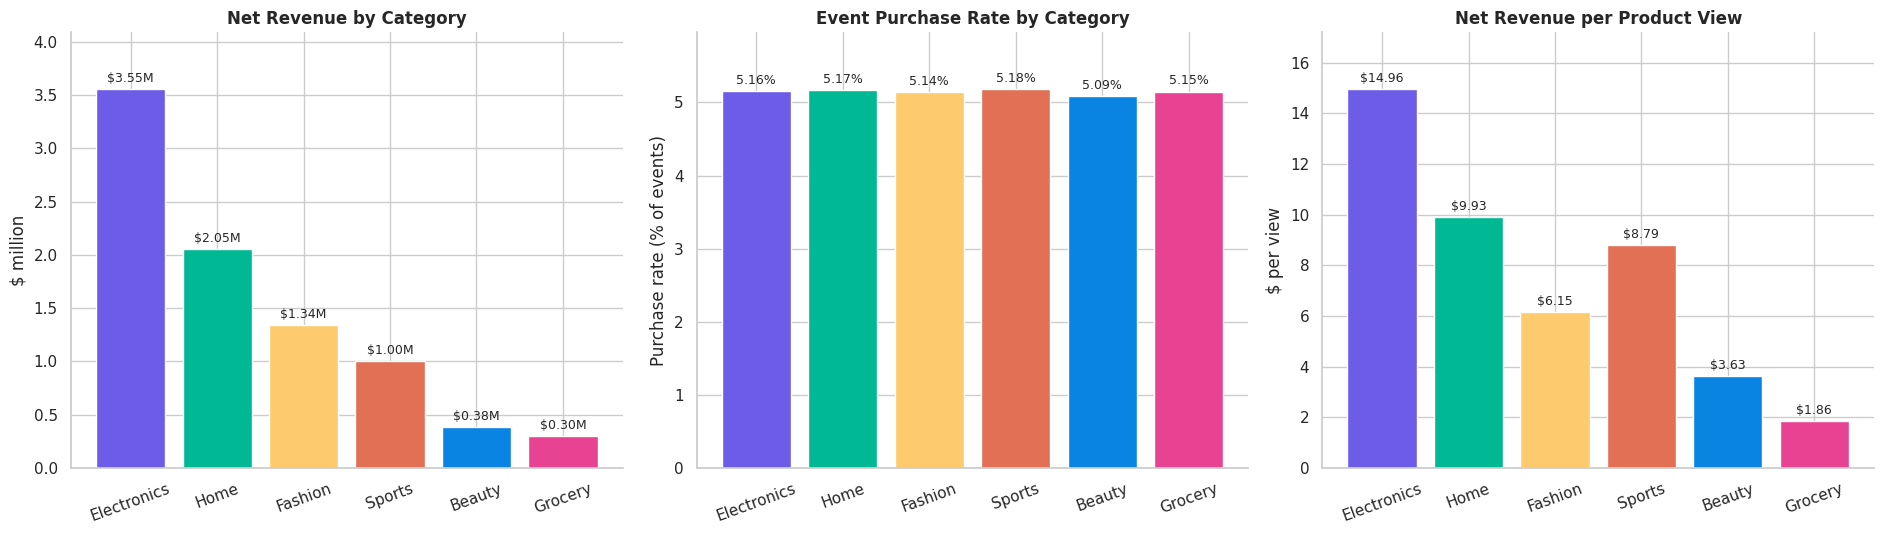

In [35]:
# Category: engagement and revenue side by side
cat_engage = run_sql("""
SELECT p.category,
       SUM(e.event_type = 'view')        AS views,
       SUM(e.event_type = 'click')       AS clicks,
       SUM(e.event_type = 'add_to_cart') AS carts,
       SUM(e.event_type = 'purchase')    AS purchases,
       ROUND(100.0 * SUM(e.event_type = 'purchase') / COUNT(*), 3) AS purchase_rate_pct
FROM events e
JOIN products p ON p.product_id = e.product_id
GROUP BY p.category
""")
cat_sales = run_sql("""
SELECT category, COUNT(*) AS orders, SUM(quantity) AS units, ROUND(SUM(net_revenue), 0) AS net_revenue,
       ROUND(AVG(order_value), 2) AS aov, ROUND(100.0 * AVG(refund_flag), 2) AS refund_rate_pct,
       ROUND(100.0 * AVG(discount_applied), 2) AS avg_discount_pct
FROM v_transactions WHERE category IS NOT NULL GROUP BY category
""")
cat_perf = cat_engage.merge(cat_sales, on="category").sort_values("net_revenue", ascending=False).reset_index(drop=True)
cat_perf["revenue_per_view ($)"] = cat_perf["net_revenue"] / cat_perf["views"]
display(cat_perf)

# Is category associated with event-level purchase? (chi-square)
cat_events = run_sql("""
SELECT p.category, e.is_purchase FROM events e JOIN products p ON p.product_id = e.product_id
""")
chi2_c, p_c, dof_c, v_c = cramers_v(pd.crosstab(cat_events["category"], cat_events["is_purchase"]))

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
bar_panel(axes[0], cat_perf["category"], cat_perf["net_revenue"] / 1e6, "Net Revenue by Category", ylabel="$ million", fmt="${:,.2f}M", rotation=20)
bar_panel(axes[1], cat_perf["category"], cat_perf["purchase_rate_pct"], "Event Purchase Rate by Category", ylabel="Purchase rate (% of events)", fmt="{:.2f}%", rotation=20)
bar_panel(axes[2], cat_perf["category"], cat_perf["revenue_per_view ($)"], "Net Revenue per Product View", ylabel="$ per view", fmt="${:,.2f}", rotation=20)
plt.tight_layout(); plt.show()

rate_spread = cat_perf["purchase_rate_pct"].max() - cat_perf["purchase_rate_pct"].min()
FINDINGS.update({"cat_rate_spread": rate_spread, "cat_chi_p": p_c, "cat_v": v_c})
show_banner(
    "Category performance",
    f"<strong>{html.escape(str(cat_perf.iloc[0]['category']))}</strong> leads net revenue (${cat_perf.iloc[0]['net_revenue']/1e6:,.2f}M). "
    f"The event-level purchase rate is almost identical across categories ({cat_perf['purchase_rate_pct'].min():.2f}%–{cat_perf['purchase_rate_pct'].max():.2f}%, "
    f"chi-square p {html.escape(fmt_p(p_c))}, Cramér's V {v_c:.4f}), "
    + ("so categories differ in <strong>price and volume</strong>, not in how well they convert. Revenue rankings therefore follow price level: to grow revenue, price and traffic allocation matter more than category conversion."
       if p_c >= 0.05 else "so categories also differ somewhat in how well they convert, although the effect size is small."),
    color="purple", icon="🛍️"
)

Top 15 products by net revenue


,product_id,category,brand,base_price,orders,units,net_revenue,refund_rate_pct
0,496.00,Electronics,Brand_16,464.58,53,75,"33,310.00",0.00
1,"1,590.00",Home,Brand_70,301.83,61,87,"24,946.00",1.60
2,730.00,Electronics,Brand_56,377.64,47,69,"24,830.00",4.30
3,223.00,Electronics,Brand_6,399.36,46,58,"21,605.00",2.20
4,87.00,Electronics,Brand_24,270.57,54,80,"20,929.00",0.00
5,"1,328.00",Electronics,Brand_71,252.91,50,81,"19,841.00",0.00
6,"1,792.00",Electronics,Brand_80,305.81,51,67,"19,740.00",2.00
7,705.00,Electronics,Brand_53,279.87,56,76,"18,989.00",3.60
8,316.00,Electronics,Brand_57,288.45,45,65,"17,942.00",0.00
9,"1,862.00",Electronics,Brand_29,254.34,52,74,"17,880.00",1.90


Premium vs standard


,tier,orders,net_revenue,aov,refund_rate_pct
0,Standard,46167,"1,980,257.00",44.15,2.86
1,Premium,46511,"6,650,012.00",147.24,2.98


Price band


,price_band,orders,net_revenue,aov,refund_rate_pct,avg_discount_pct
0,Q1 Low,23062,"562,735.00",25.14,2.87,4.09
1,Q2 Mid-low,23105,"1,417,522.00",63.12,2.84,4.13
2,Q3 Mid-high,23268,"2,338,580.00",103.67,3.01,4.15
3,Q4 High,23243,"4,311,432.00",190.87,2.94,4.15


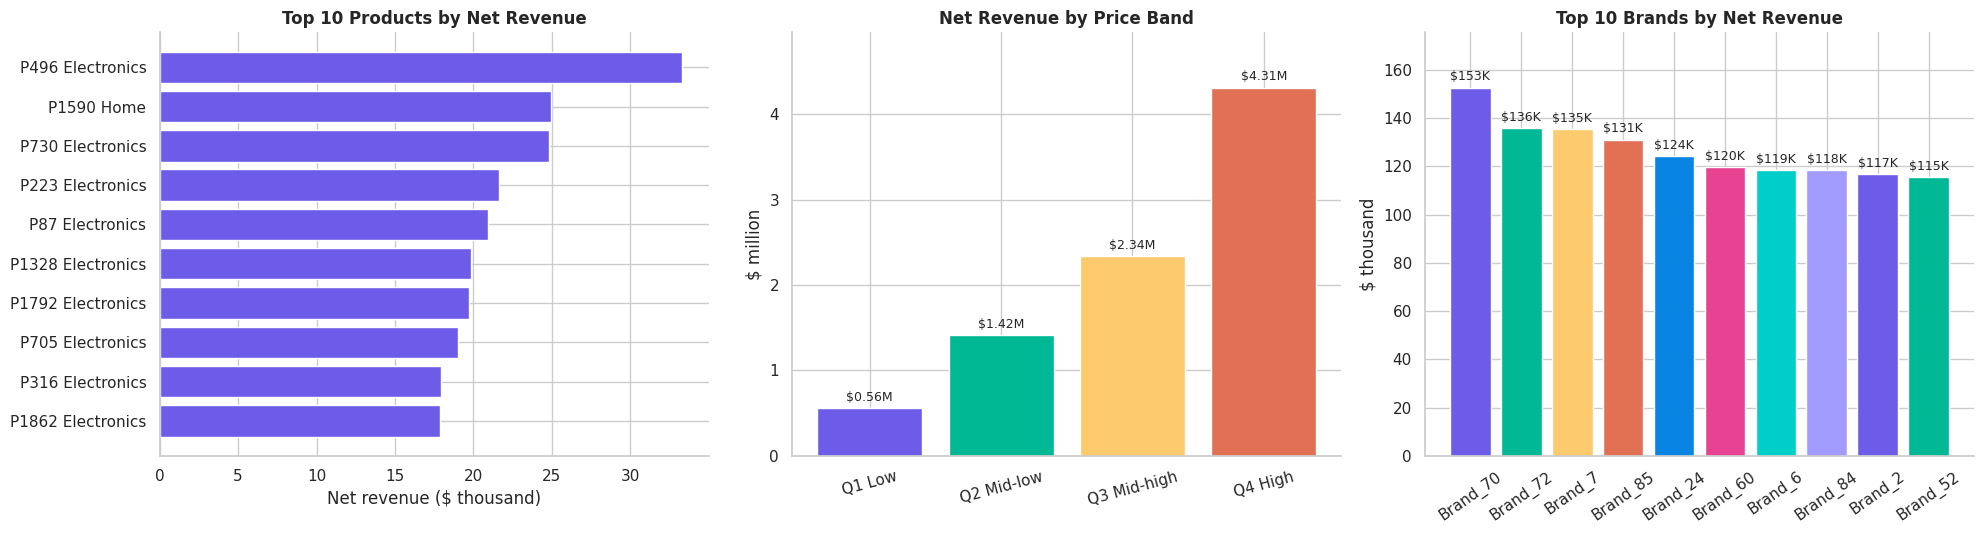

In [36]:
# Top products, brands, premium vs standard, price bands
top_products = run_sql("""
SELECT v.product_id, v.category, v.brand, ROUND(v.base_price, 2) AS base_price,
       COUNT(*) AS orders, SUM(v.quantity) AS units, ROUND(SUM(v.net_revenue), 0) AS net_revenue,
       ROUND(100.0 * AVG(v.refund_flag), 1) AS refund_rate_pct
FROM v_transactions v
WHERE v.product_id IS NOT NULL AND v.has_revenue = 1
GROUP BY v.product_id, v.category, v.brand, v.base_price
ORDER BY net_revenue DESC
LIMIT 15
""")
print("Top 15 products by net revenue"); display(top_products)

premium = run_sql("""
SELECT CASE is_premium WHEN 1 THEN 'Premium' ELSE 'Standard' END AS tier,
       COUNT(*) AS orders, ROUND(SUM(net_revenue), 0) AS net_revenue, ROUND(AVG(order_value), 2) AS aov,
       ROUND(100.0 * AVG(refund_flag), 2) AS refund_rate_pct
FROM v_transactions WHERE product_id IS NOT NULL AND has_revenue = 1 GROUP BY is_premium
""")
price_band = run_sql("""
SELECT price_band, COUNT(*) AS orders, ROUND(SUM(net_revenue), 0) AS net_revenue, ROUND(AVG(order_value), 2) AS aov,
       ROUND(100.0 * AVG(refund_flag), 2) AS refund_rate_pct, ROUND(100.0 * AVG(discount_applied), 2) AS avg_discount_pct
FROM v_transactions WHERE product_id IS NOT NULL AND has_revenue = 1 GROUP BY price_band ORDER BY price_band
""")
brands = run_sql("""
SELECT brand, COUNT(*) AS orders, ROUND(SUM(net_revenue), 0) AS net_revenue
FROM v_transactions WHERE product_id IS NOT NULL AND has_revenue = 1
GROUP BY brand ORDER BY net_revenue DESC LIMIT 10
""")
print("Premium vs standard"); display(premium)
print("Price band"); display(price_band)

# Product concentration (Pareto)
prod_rev = run_sql("""
SELECT product_id, SUM(net_revenue) AS net_revenue FROM v_transactions
WHERE product_id IS NOT NULL AND has_revenue = 1 GROUP BY product_id ORDER BY net_revenue DESC
""")
prod_rev["cum_share"] = prod_rev["net_revenue"].cumsum() / prod_rev["net_revenue"].sum() * 100
n_prod = len(prod_rev); top20_prod_share = prod_rev["cum_share"].iloc[int(np.ceil(n_prod * 0.2)) - 1]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
tp = top_products.head(10).copy(); tp["label"] = "P" + tp["product_id"].astype(int).astype(str) + " " + tp["category"]
axes[0].barh(tp["label"][::-1], tp["net_revenue"][::-1] / 1000, color=PALETTE[0])
axes[0].set_title("Top 10 Products by Net Revenue", fontweight="bold"); axes[0].set_xlabel("Net revenue ($ thousand)")
bar_panel(axes[1], price_band["price_band"], price_band["net_revenue"] / 1e6, "Net Revenue by Price Band", ylabel="$ million", fmt="${:,.2f}M", rotation=15)
bar_panel(axes[2], brands["brand"], brands["net_revenue"] / 1000, "Top 10 Brands by Net Revenue", ylabel="$ thousand", fmt="${:,.0f}K", rotation=35)
for ax in axes: sns.despine(ax=ax)
plt.tight_layout(); plt.show()

high_band = price_band.iloc[-1]; share_high = high_band["net_revenue"] / price_band["net_revenue"].sum() * 100
FINDINGS.update({"top20_prod_share": top20_prod_share, "high_band_share": share_high})
show_banner(
    "Product concentration and price",
    f"The top 20% of products generate <strong>{top20_prod_share:.0f}%</strong> of net revenue"
    + (", so sales are spread widely rather than driven by a few hits (a strict 80/20 pattern would show about 80%). " if top20_prod_share < 60 else ", so a minority of products drive most of the revenue. ")
    +
    f"The highest price band alone accounts for <strong>{share_high:.0f}%</strong> of net revenue. "
    f"Premium products have an AOV of {money(premium.loc[premium['tier']=='Premium','aov'].iloc[0], 2)} vs {money(premium.loc[premium['tier']=='Standard','aov'].iloc[0], 2)} for standard. "
    "The dataset is synthetic, so use the product rankings to illustrate the method rather than to name real best sellers.",
    color="teal", icon="🏅"
)

## 14. Business findings and recommendations

This section turns the results above into decisions. Every number is read from the analysis that produced it, so the text updates if the data changes. Findings are **associations** unless they come from the A/B test, and even there the design limits (event-level assignment) are stated.

In [37]:
F = FINDINGS
exposed_holiday_lift = hol.loc["Campaign exposed", "holiday_lift_pp"].mean()
unexposed_holiday_lift = hol.loc["No campaign", "holiday_lift_pp"].mean()

# Headline
show_banner(
    "Headline",
    f"The business generated <strong>{money(F['net_revenue'])}</strong> of net revenue from <strong>{int(F['orders']):,}</strong> orders and <strong>{int(F['buyers']):,}</strong> buyers. "
    f"<strong>{F['ab_winner']}</strong> is the strongest A/B arm (<strong>{F['B_uplift_pp']:+.2f} pp</strong> purchase rate, <strong>{F['B_rel']:+.0f}%</strong> relative, "
    f"vs Control {F['ctrl_rate']:.2f}%), and November–December lifts conversion by <strong>{F['holiday_rel']:+.0f}%</strong>. "
    "The biggest unresolved question is how much of the paid-channel advantage is caused by the campaigns themselves.",
    color="purple", icon="🏁"
)

# Findings
findings = [
    {"title": "Funnel", "icon": "🔻", "color": "orange",
     "body": f"<strong>{F['overall_purchase_rate']:.2f}%</strong> of events are purchases. The steepest step is add-to-cart → purchase (<strong>{step_ratio[3]:.0f}%</strong> as many purchases as carts), "
             f"and it varies widely by source: {F['src_hi']} {F['src_hi_rate']:.2f}% vs {F['src_lo']} {F['src_lo_rate']:.2f}% purchase rate."},
    {"title": "Campaigns", "icon": "📣", "color": "pink",
     "body": f"Exposed events convert at <strong>{F['exp_rate']:.2f}%</strong> vs <strong>{F['unexp_rate']:.2f}%</strong> ({F['exp_diff_pp']:+.2f} pp). "
             + ("Exposure and traffic source never overlap, so this gap <strong>cannot be split</strong> into campaign effect and channel effect." if F['confounded'] else "Exposure partly overlaps with traffic source.")
             + f" Best campaign channel: {F['best_channel']} ({F['best_channel_rate']:.2f}%)."},
    {"title": "A/B test", "icon": "🧪", "color": "green",
     "body": f"Variant_A <strong>{F['A_uplift_pp']:+.2f} pp</strong> ({F['A_rel']:+.0f}%), Variant_B <strong>{F['B_uplift_pp']:+.2f} pp</strong> ({F['B_rel']:+.0f}%). "
             f"Adjusted odds ratios: A {F['or_A']:.2f}, B {F['or_B']:.2f}. Net revenue per 1,000 events: ${F['B_rev_per_1000']:,.0f} (B) vs ${F['ctrl_rev_per_1000']:,.0f} (Control), "
             f"because order value is unchanged and conversion is what moves."},
    {"title": "Seasonality", "icon": "📅", "color": "red",
     "body": f"November–December purchase rate is <strong>{F['holiday_rate']:.2f}%</strong> vs {F['nonholiday_rate']:.2f}% the rest of the year ({F['holiday_rel']:+.0f}%). "
             f"The absolute holiday gain is larger on campaign-exposed traffic ({exposed_holiday_lift:+.2f} pp) than on unexposed traffic ({unexposed_holiday_lift:+.2f} pp). "
             f"Weekends add {F['weekend_lift_pp']:+.2f} pp."},
    {"title": "Revenue & discounts", "icon": "💰", "color": "teal",
     "body": f"Net revenue {money(F['net_revenue'])}, AOV {money(F['aov'], 2)}, refunds {F['refund_rate_orders']:.2f}% of orders. {F['top_cat']} brings {F['top_cat_share']:.0f}% of revenue. "
             f"Discounts cost {money(F['discount_cost'])} ({F['discount_share']:.1f}% of list value) and are not linked to larger baskets (ρ = {F['disc_units_rho']:.3f})."},
    {"title": "Customers", "icon": "🧩", "color": "blue",
     "body": f"{F['buyer_rate_overall']:.1f}% of customers bought. Loyalty tier is the main profile differentiator "
             f"(revenue per customer {money(F['tier_bot_rev'], 2)} to {money(F['tier_top_rev'], 2)}); no detectable difference for {', '.join(F['flat_dims']) or 'none'}. "
             f"Champions: {F['champ_pct']:.0f}% of buyers, {F['champ_rev']:.0f}% of revenue. At-risk and lapsing-loyal buyers: {F['risk_pct']:.0f}% of buyers, {F['risk_rev']:.0f}% of revenue."},
]
show_cards(findings, columns=3)

# Recommendations
recs = []
if F["ab_winner"] != "Control":
    recs.append({"title": f"1. Prioritise {F['ab_winner']}", "icon": "🚀", "color": "green",
                 "body": f"It lifts purchase rate by {F['B_uplift_pp']:+.2f} pp and net revenue per 1,000 events by {F['B_rev_rel']:+.0f}% without changing order value, " + ("and the lift is significant in every traffic source and loyalty tier tested. " if F['segB_all_sig'] else "and the lift is significant in most, but not all, segments tested. ")
                         + " <em>Before full rollout:</em> confirm with a customer-level (not event-level) split and check the variant's running cost."})
if F["confounded"]:
    recs.append({"title": "2. Run a proper campaign holdout", "icon": "🎯", "color": "orange",
                 "body": f"Campaign exposure only occurs on {', '.join(F['fully_exposed'])}. Keep a randomly chosen share of customers unexposed <em>within</em> each paid channel so the campaign effect can be separated from the channel effect "
                         "and a real return on spend can be calculated (no cost data is available here)."})
recs.append({"title": "3. Plan for November–December", "icon": "📅", "color": "red",
             "body": f"Conversion is about {F['holiday_rel']:.0f}% higher in the holiday months, every year. Align stock, budget and campaign calendar to this peak; the lift is larger in absolute terms on exposed traffic."})
recs.append({"title": "4. Test the discount policy", "icon": "🏷️", "color": "yellow",
             "body": f"Discounts cost {money(F['discount_cost'])} and show no link to basket size. Run a controlled test that reduces the deepest discounts ({F['disc_max_pct']}%) to learn whether they change purchase probability at all."})
recs.append({"title": "5. Use behaviour, not demographics, for targeting", "icon": "🧩", "color": "blue",
             "body": f"Loyalty tier and purchase history separate customers; age, gender, country and acquisition channel do not. Prioritise win-back for at-risk and lapsing-loyal buyers ({F['risk_pct']:.0f}% of buyers) and protect Champions."})
recs.append({"title": "6. Fix the tracking gaps", "icon": "🛠️", "color": "slate",
             "body": f"Record revenue for every order ({F['rev_missing_pct']:.0f}% are missing), make <code>session_id</code> unique per visit, randomise by customer, standardise <code>traffic_source</code> labels and keep campaign dates consistent with exposure."})
show_cards(recs, columns=3)

show_banner(
    "What these results cannot tell us",
    "<ul>"
    "<li><strong>The data is synthetic.</strong> The patterns demonstrate analytical technique and are not evidence about a real business.</li>"
    "<li><strong>No cost data.</strong> Return on ad spend, discount ROI and the cost of a variant cannot be calculated.</li>"
    "<li><strong>Event-level assignment.</strong> Customers see several experiment groups, so spill-over between groups cannot be ruled out.</li>"
    "<li><strong>Exposure equals traffic source.</strong> Campaign effect and channel effect are inseparable here.</li>"
    f"<li><strong>Revenue gaps.</strong> About {F['rev_missing_pct']:.0f}% of orders have no revenue; figures describe the rest.</li>"
    "<li><strong>No user journeys.</strong> Funnel steps are event counts, not the share of individual users who progressed.</li></ul>",
    color="yellow", icon="⚠️"
)

## 15. Conclusion

The summary below brings together the distinct findings without repeating the same metric in several cards.

**About the tables:** the source data has five tables (customers 7 columns, products 6, campaigns 7, events 12, transactions 9). The notebook adds analysis-only columns (for example `event_month`, `has_campaign`, `age_group`, `price_band`) to cleaned working copies and to the SQL database, and never overwrites the source files.

In [38]:
conclusion_cards = []

conclusion_cards.append({
    "title": "1. Data quality & structure", "icon": "🧹", "color": "blue",
    "body": f"<strong>{len(cust):,}</strong> customers, <strong>{len(prod):,}</strong> products, <strong>{len(camp)}</strong> campaigns, "
            f"<strong>{run_sql('SELECT COUNT(*) FROM events').iloc[0, 0]:,}</strong> events and <strong>{int(F['orders']):,}</strong> transactions. "
            f"Keys are consistent, revenue is missing for <strong>{F['rev_missing_pct']:.1f}%</strong> of orders, and refunds are stored as negative values (rebuilt in SQL)."
})
conclusion_cards.append({
    "title": "2. Conversion funnel", "icon": "🔻", "color": "orange",
    "body": f"Overall purchase rate <strong>{F['overall_purchase_rate']:.2f}%</strong>; <strong>{F['buyer_share']:.1f}%</strong> of customers have at least one purchase. "
            f"Source separates conversion most ({F['src_hi']} {F['src_hi_rate']:.2f}% vs {F['src_lo']} {F['src_lo_rate']:.2f}%)."
})
conclusion_cards.append({
    "title": "3. Campaign effectiveness", "icon": "📣", "color": "pink",
    "body": f"Exposed events convert at <strong>{F['exp_rate']:.2f}%</strong> vs <strong>{F['unexp_rate']:.2f}%</strong>. "
            f"Exposure is {'fully' if F['confounded'] else 'partly'} confounded with traffic source. Planned vs observed campaign performance: r = {F['plan_vs_obs_r']:.2f}."
})
conclusion_cards.append({
    "title": "4. A/B test", "icon": "🧪", "color": "green",
    "body": f"Control {F['ctrl_rate']:.2f}%, Variant_A {F['A_rate']:.2f}%, Variant_B {F['B_rate']:.2f}% purchase rate. "
            f"Variant_B: <strong>{F['B_uplift_pp']:+.2f} pp</strong> ({F['B_rel']:+.0f}%); adjusted OR {F['or_B']:.2f}. {F['seg_sig_share']:.0f}% of segment comparisons significant."
})
conclusion_cards.append({
    "title": "5. Statistical tests", "icon": "⚖️", "color": "purple",
    "body": f"<strong>{F['n_detect']}</strong> of <strong>{F['n_factors']}</strong> factors detectable after FDR adjustment; <strong>{F['n_strong']}</strong> with effect size ≥ 0.10. "
            f"Strongest: <strong>{html.escape(str(F['top_factor']))}</strong> ({F['top_factor_v']:.3f})."
})
conclusion_cards.append({
    "title": "6. Revenue & refunds", "icon": "💰", "color": "teal",
    "body": f"Net revenue <strong>{money(F['net_revenue'])}</strong>; AOV {money(F['aov'], 2)}; refund rate {F['refund_rate_orders']:.2f}% of orders. "
            f"Top 10% of buyers = {F['top10_share']:.0f}% of net revenue."
})
conclusion_cards.append({
    "title": "7. Discounts", "icon": "🏷️", "color": "yellow",
    "body": f"Discount cost <strong>{money(F['discount_cost'])}</strong> ({F['discount_share']:.1f}% of list value). "
            f"AOV from {money(F['disc_aov_none'], 2)} (no discount) to {money(F['disc_aov_max'], 2)} ({F['disc_max_pct']}% discount); no association with units per order."
})
conclusion_cards.append({
    "title": "8. Customer segmentation", "icon": "🧩", "color": "blue",
    "body": f"Significant differences: <strong>{html.escape(', '.join(F['sig_dims']) or 'none')}</strong>. Revenue per customer {money(F['tier_bot_rev'], 2)}–{money(F['tier_top_rev'], 2)} across loyalty tiers."
})
conclusion_cards.append({
    "title": "9. RFM", "icon": "🎯", "color": "teal",
    "body": f"Champions {F['champ_pct']:.1f}% of buyers ({F['champ_rev']:.1f}% of revenue); at-risk + lapsing-loyal {F['risk_pct']:.1f}% ({F['risk_rev']:.1f}%); hibernating {F['hib_pct']:.1f}% ({F['hib_rev']:.1f}%)."
})
conclusion_cards.append({
    "title": "10. Trends & seasonality", "icon": "📅", "color": "red",
    "body": f"Nov–Dec purchase rate {F['holiday_rate']:.2f}% vs {F['nonholiday_rate']:.2f}% ({F['holiday_rel']:+.0f}%); weekend {F['weekend_lift_pp']:+.2f} pp; no hour-of-day pattern. "
            f"Yearly revenue change at most {F['yoy_growth_max']:.1f}%."
})
conclusion_cards.append({
    "title": "11. Product performance", "icon": "🛍️", "color": "purple",
    "body": f"{F['top_cat']} leads revenue ({F['top_cat_share']:.0f}%). Category conversion is nearly identical (Cramér's V {F['cat_v']:.4f}), so revenue follows price. "
            f"Top 20% of products = {F['top20_prod_share']:.0f}% of revenue."
})
conclusion_cards.append({
    "title": "12. Limits of the analysis", "icon": "⚠️", "color": "slate",
    "body": "Synthetic data; event-level randomisation; exposure inseparable from traffic source; no cost data; funnel built from event counts, not user journeys."
})
show_cards(conclusion_cards, columns=2)

show_banner(
    "Overall conclusion",
    f"The analysis describes {run_sql('SELECT COUNT(*) FROM events').iloc[0, 0]:,} events and {int(F['orders']):,} orders across {len(cust):,} customers using SQL and Python. "
    f"The A/B test favours <strong>{F['ab_winner']}</strong>, conversion is strongly seasonal, and discounts show no sign of increasing basket size. "
    "Segment differences and campaign comparisons are associations, not causes; the campaign effect in particular cannot be separated from the traffic-source effect with this data.",
    color="blue", icon="📝"
)

conn.close()
print("Analysis complete. Yeayyy!")

Analysis complete. Yeayyy!
